In [1]:
!nvidia-smi

Tue Sep 29 16:04:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Colab-compatible installation
# Do NOT upgrade pip or requests

!pip install -q \
    "pymatgen==2025.5.28" \
    ase \
    chgnet \
    rdkit \
    scikit-learn \
    pandas \
    numpy \
    scipy \
    matplotlib \
    umap-learn \
    plotly \
    h5py

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 27.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 93.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.6/62.6 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 962.5/962.5 kB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
import requests
import ase
import pymatgen
import chgnet
import rdkit
import sklearn
import importlib.metadata as metadata

print("Requests:", requests.__version__)
print("ASE:", ase.__version__)
print("Pymatgen:", metadata.version("pymatgen"))
print("CHGNet: OK")
print("RDKit: OK")
print("Scikit-learn: OK")

Requests: 2.32.4
ASE: 3.29.0
Pymatgen: 2025.5.28
CHGNet: OK
RDKit: OK
Scikit-learn: OK


In [4]:
from google.colab import files

uploaded = files.upload()

cif_file = list(uploaded.keys())[0]

print("Uploaded:", cif_file)

Saving 1544195.cif to 1544195.cif
Uploaded: 1544195.cif


In [5]:
from pymatgen.core import Structure

structure_exp = Structure.from_file(cif_file)

print(structure_exp)
print()
print("Formula:", structure_exp.composition.reduced_formula)
print("Number of atoms:", len(structure_exp))
print("Lattice:", structure_exp.lattice)
print("Volume:", structure_exp.volume)
print("Density:", structure_exp.density)

Full Formula (H152 C176 N24 O32)
Reduced Formula: H19C22N3O4
abc   :  27.427000   7.640200  21.038000
angles:  90.000000 119.263000  90.000000
pbc   :       True       True       True
Sites (384)
  #  SP          a        b        c
---  ----  -------  -------  -------
  0  H     0.7458   0.765    0.6862
  1  H     0.2542   0.765    0.8138
  2  H     0.2458   0.265    0.6862
  3  H     0.7542   0.265    0.8138
  4  H     0.2542   0.235    0.3138
  5  H     0.7458   0.235    0.1862
  6  H     0.7542   0.735    0.3138
  7  H     0.2458   0.735    0.1862
  8  H     0.4842   0.369    0.5508
  9  H     0.5158   0.369    0.9492
 10  H     0.9842   0.869    0.5508
 11  H     0.0158   0.869    0.9492
 12  H     0.5158   0.631    0.4492
 13  H     0.4842   0.631    0.0508
 14  H     0.0158   0.131    0.4492
 15  H     0.9842   0.131    0.0508
 16  H     0.6447   0.397    0.6919
 17  H     0.3553   0.397    0.8081
 18  H     0.1447   0.897    0.6919
 19  H     0.8553   0.897    0.8081
 20  H    

/usr/local/lib/python3.13/dist-packages/pymatgen/core/composition.py:1372: FutureWarning: gcd is deprecated, and will be removed on 2028-01-01
Use math.gcd instead.
  factor = abs(gcd(*(int(i) for i in sym_amt.values())))


In [6]:
from pymatgen.io.ase import AseAtomsAdaptor

atoms_exp = AseAtomsAdaptor.get_atoms(structure_exp)

print(atoms_exp)
print("Atoms:", len(atoms_exp))
print("Cell:")
print(atoms_exp.cell)

MSONAtoms(symbols='C176H152N24O32', pbc=True, cell=[[23.926906685487953, 0.0, -13.406843978504106], [1.2286378668059438e-15, 7.6402, 4.678273237422804e-16], [0.0, 0.0, 21.038]])
Atoms: 384
Cell:
Cell([[23.926906685487953, 0.0, -13.406843978504106], [1.2286378668059438e-15, 7.6402, 4.678273237422804e-16], [0.0, 0.0, 21.038]])


In [7]:
import numpy as np

cell = atoms_exp.cell

lengths = atoms_exp.cell.lengths()
angles = atoms_exp.cell.angles()

print("a =", lengths[0], "Å")
print("b =", lengths[1], "Å")
print("c =", lengths[2], "Å")

print("alpha =", angles[0], "°")
print("beta  =", angles[1], "°")
print("gamma =", angles[2], "°")

print("Volume =", atoms_exp.get_volume(), "Å³")
print("Density =", structure_exp.density, "g/cm³")

a = 27.426999999999996 Å
b = 7.6402 Å
c = 21.038 Å
alpha = 90.0 °
beta  = 119.26300000000002 °
gamma = 90.0 °
Volume = 3845.8800430211886 Å³
Density = 1.3450663711584694 g cm^-3 g/cm³


In [8]:
from chgnet.model import CHGNet

chgnet = CHGNet.load()

print("CHGNet loaded successfully.")

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda
CHGNet loaded successfully.


In [9]:
# Inspect the CHGNet prediction output

prediction_exp = chgnet.predict_structure(structure_exp)

print("Prediction completed successfully.")
print("\nReturned object type:")
print(type(prediction_exp))

print("\nReturned keys:")
print(prediction_exp.keys())

print("\nFull prediction output:")
print(prediction_exp)

/usr/local/lib/python3.13/dist-packages/chgnet/model/model.py:898: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  volumes = torch.tensor(volumes, dtype=TORCH_DTYPE, device=atomic_numbers.device)


Prediction completed successfully.

Returned object type:
<class 'dict'>

Returned keys:
dict_keys(['e', 'f', 'm', 's'])

Full prediction output:
{'e': array(-6.622496, dtype=float32), 'f': array([[ 10.50923   ,   1.4704652 ,   2.5919495 ],
       [-10.509189  ,   1.47046   ,  -2.5919554 ],
       [ 10.509119  ,   1.4704528 ,   2.5919251 ],
       ...,
       [ -0.13138783,   0.46829432,  -0.39790598],
       [  0.13138591,   0.4683061 ,   0.39791557],
       [ -0.13141397,   0.46832228,  -0.39793086]], dtype=float32), 'm': array([0.01578146, 0.01578104, 0.0157811 , 0.01578128, 0.01578122,
       0.01578134, 0.01578134, 0.0157811 , 0.00644875, 0.00644898,
       0.00644869, 0.00644863, 0.00644892, 0.00644875, 0.00644892,
       0.00644863, 0.00794947, 0.00794959, 0.00794947, 0.00794965,
       0.00794959, 0.00794965, 0.00794941, 0.00794965, 0.02210331,
       0.02210343, 0.02210361, 0.02210379, 0.02210313, 0.02210331,
       0.02210373, 0.02210343, 0.01458293, 0.01458311, 0.01458281,
 

In [10]:
from chgnet.model import StructOptimizer

relaxer = StructOptimizer()

result = relaxer.relax(
    structure_exp,
    relax_cell=True,
    fmax=0.05,
    steps=500,
    verbose=True
)

structure_relaxed = result["final_structure"]

print(structure_relaxed)

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda
      Step     Time          Energy          fmax
FIRE:    0 16:05:38    -2543.038574       11.547589
FIRE:    1 16:05:39    -2561.472168        8.166344
FIRE:    2 16:05:40    -2574.335449        5.444408
FIRE:    3 16:05:41    -2582.500732        3.419347
FIRE:    4 16:05:43    -2586.962646        2.165830
FIRE:    5 16:05:43    -2588.795410        3.462188
FIRE:    6 16:05:44    -2589.163818        4.223658
FIRE:    7 16:05:44    -2590.947754        3.118785
FIRE:    8 16:05:45    -2593.021240        1.434299
FIRE:    9 16:05:45    -2593.988525        1.032285
FIRE:   10 16:05:46    -2594.073486        1.424826
FIRE:   11 16:05:46    -2594.234131        1.330306
FIRE:   12 16:05:47    -2594.520020        1.235123
FIRE:   13 16:05:47    -2594.870850        1.100104
FIRE:   14 16:05:48    -2595.218750        0.941438
FIRE:   15 16:05:48    -2595.502686        0.758728
FIRE:   16 16:05:49    -2595.692627        0

/usr/local/lib/python3.13/dist-packages/pymatgen/core/composition.py:1372: FutureWarning: gcd is deprecated, and will be removed on 2028-01-01
Use math.gcd instead.
  factor = abs(gcd(*(int(i) for i in sym_amt.values())))


In [11]:
def lattice_report(s):
    return {
        "a": s.lattice.a,
        "b": s.lattice.b,
        "c": s.lattice.c,
        "alpha": s.lattice.alpha,
        "beta": s.lattice.beta,
        "gamma": s.lattice.gamma,
        "volume": s.volume,
        "density": s.density
    }

exp_data = lattice_report(structure_exp)
rel_data = lattice_report(structure_relaxed)

for key in exp_data:
    print(
        f"{key:8s}: "
        f"experimental = {exp_data[key]:10.4f}   "
        f"relaxed = {rel_data[key]:10.4f}"
    )

a       : experimental =    27.4270   relaxed =    27.4401
b       : experimental =     7.6402   relaxed =     7.6430
c       : experimental =    21.0380   relaxed =    21.0459
alpha   : experimental =    90.0000   relaxed =    90.0000
beta    : experimental =   119.2630   relaxed =   119.2564
gamma   : experimental =    90.0000   relaxed =    90.0000
volume  : experimental =  3845.8800   relaxed =  3850.7977
density : experimental =     1.3451   relaxed =     1.3433


In [12]:
for key in ["a", "b", "c", "volume", "density"]:
    exp = exp_data[key]
    rel = rel_data[key]

    pct = 100 * (rel - exp) / exp

    print(f"{key:8s}: {pct:+.2f}%")

a       : +0.05%
b       : +0.04%
c       : +0.04%
volume  : +0.13%
density : -0.13%


In [13]:
# ============================================================
# CELL 13 — CHGNet energy comparison
# ============================================================

import numpy as np

print("=" * 65)
print("CHGNet ENERGY COMPARISON")
print("=" * 65)

# ------------------------------------------------------------
# Calculate CHGNet prediction for the relaxed structure
# ------------------------------------------------------------

print("\nCalculating CHGNet energy for relaxed structure...")

prediction_rel = chgnet.predict_structure(
    structure_relaxed
)

print("Relaxed-structure prediction completed.")

# ------------------------------------------------------------
# Extract CHGNet energies
# ------------------------------------------------------------

energy_exp = float(
    prediction_exp["e"]
)

energy_rel = float(
    prediction_rel["e"]
)

# ------------------------------------------------------------
# Number of atoms
# ------------------------------------------------------------

n_atoms = len(
    structure_exp
)

# ------------------------------------------------------------
# Energy difference
# ------------------------------------------------------------

delta_e = (
    energy_rel
    -
    energy_exp
)

delta_mev_atom = (
    delta_e * 1000
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print()
print(f"Number of atoms              : {n_atoms}")
print(
    f"Experimental structure       : "
    f"{energy_exp:.6f} eV/atom"
)

print(
    f"CHGNet-relaxed structure    : "
    f"{energy_rel:.6f} eV/atom"
)

print(
    f"Energy difference            : "
    f"{delta_e:.6f} eV/atom"
)

print(
    f"Energy difference            : "
    f"{delta_mev_atom:.3f} meV/atom"
)

# ------------------------------------------------------------
# Interpretation
# ------------------------------------------------------------

if energy_rel < energy_exp:

    print(
        "\nResult: The CHGNet-relaxed structure "
        "has a lower CHGNet-predicted energy "
        "than the experimental structure."
    )

elif energy_rel > energy_exp:

    print(
        "\nResult: The experimental structure "
        "has a lower CHGNet-predicted energy "
        "than the CHGNet-relaxed structure."
    )

else:

    print(
        "\nResult: Both structures have the same "
        "CHGNet-predicted energy within the "
        "reported numerical precision."
    )

print("=" * 65)
print("CELL 13 COMPLETE")
print("=" * 65)

CHGNet ENERGY COMPARISON

Calculating CHGNet energy for relaxed structure...
Relaxed-structure prediction completed.

Number of atoms              : 384
Experimental structure       : -6.622496 eV/atom
CHGNet-relaxed structure    : -6.764219 eV/atom
Energy difference            : -0.141723 eV/atom
Energy difference            : -141.723 meV/atom

Result: The CHGNet-relaxed structure has a lower CHGNet-predicted energy than the experimental structure.
CELL 13 COMPLETE


In [14]:
# ============================================================
# CELL 14 — Force comparison
# ============================================================

forces_exp = np.array(prediction_exp["f"])
forces_rel = np.array(prediction_rel["f"])

force_exp = np.linalg.norm(forces_exp, axis=1)
force_rel = np.linalg.norm(forces_rel, axis=1)

print("=" * 65)
print("CHGNet FORCE COMPARISON")
print("=" * 65)

print(f"Experimental maximum force : {force_exp.max():.4f} eV/Å")
print(f"Relaxed maximum force      : {force_rel.max():.4f} eV/Å")

print(f"Experimental RMS force     : "
      f"{np.sqrt(np.mean(force_exp**2)):.4f} eV/Å")

print(f"Relaxed RMS force          : "
      f"{np.sqrt(np.mean(force_rel**2)):.4f} eV/Å")

print("=" * 65)

CHGNet FORCE COMPARISON
Experimental maximum force : 11.5476 eV/Å
Relaxed maximum force      : 0.0391 eV/Å
Experimental RMS force     : 5.4956 eV/Å
Relaxed RMS force          : 0.0217 eV/Å


In [15]:
structure_relaxed.to(
    filename="CHGNet_relaxed.cif",
    fmt="cif"
)

print("Saved CHGNet_relaxed.cif")

Saved CHGNet_relaxed.cif


In [16]:
from google.colab import files

files.download("CHGNet_relaxed.cif")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
from pymatgen.io.ase import AseAtomsAdaptor

atoms_md = AseAtomsAdaptor.get_atoms(structure_relaxed)

print("Atoms:", len(atoms_md))

Atoms: 384


In [18]:
print("Original atoms:", len(atoms_md))

Original atoms: 384


In [19]:
atoms_md *= (1, 1, 2)

print("Supercell atoms:", len(atoms_md))

Supercell atoms: 768


In [20]:
# ============================================================
# CELL 17 (in template) / 21 — Create a completely clean ASE MD structure
# ============================================================

from ase import Atoms
from pymatgen.io.ase import AseAtomsAdaptor

# Get the relaxed pymatgen structure
structure_md = structure_relaxed.copy()

# Build a fresh ASE Atoms object
atoms_md = Atoms(
    symbols=[site.specie.symbol for site in structure_md],
    positions=structure_md.cart_coords,
    cell=structure_md.lattice.matrix,
    pbc=True
)

print("Clean MD structure created successfully.")
print("Number of atoms:", len(atoms_md))
print("Number of positions:", len(atoms_md.positions))
print("Cell volume:", atoms_md.get_volume(), "Å³")
print("Periodic boundary conditions:", atoms_md.pbc)

Clean MD structure created successfully.
Number of atoms: 384
Number of positions: 384
Cell volume: 3850.797692042181 Å³
Periodic boundary conditions: [ True  True  True]


In [21]:
# ============================================================
# CELL 22 — Verify clean ASE structure
# ============================================================

print("Atoms:", len(atoms_md))
print("Positions:", atoms_md.positions.shape)
print("Cell:", atoms_md.cell)
print("PBC:", atoms_md.pbc)

print("\nASE arrays:")
for key, value in atoms_md.arrays.items():
    print(f"{key}: {value.shape}")

Atoms: 384
Positions: (384, 3)
Cell: Cell([[23.939480297991537, 1.4877288315714113e-08, -13.411176173102328], [4.434197228401682e-09, 7.642976966332315, -5.648313204358053e-10], [0.000592466233517249, -1.5555780282030153e-09, 21.04585553645062]])
PBC: [ True  True  True]

ASE arrays:
numbers: (384,)
positions: (384, 3)


In [22]:
# ============================================================
# CELL 23 — Convert clean ASE structure to pymatgen
# ============================================================
from pymatgen.io.ase import AseAtomsAdaptor

structure_md = AseAtomsAdaptor.get_structure(atoms_md)

print("Conversion successful.")
print("Number of sites:", len(structure_md))
print("Formula:", structure_md.composition.reduced_formula)
print("Volume:", structure_md.volume, "Å³")

Conversion successful.
Number of sites: 384
Formula: H19C22N3O4
Volume: 3850.797692042185 Å³


In [23]:
# ============================================================
# CELL 24 — Set up CHGNet NVT molecular dynamics
# ============================================================

from chgnet.model.dynamics import MolecularDynamics

print("Creating CHGNet molecular-dynamics object...")

md = MolecularDynamics(
    atoms=atoms_md,
    model=chgnet,
    temperature=300,
    timestep=1.0,          # fs
    trajectory="cocrystal_2ps.traj",
    logfile="cocrystal_2ps.log",
    loginterval=10
)

print("MD object created successfully.")
print("Temperature: 300 K")
print("Timestep: 1 fs")
print("Total steps: 2000")
print("Total simulation time: 2 ps")

Creating CHGNet molecular-dynamics object...
CHGNet will run on cuda
NVT-Berendsen-MD created
MD object created successfully.
Temperature: 300 K
Timestep: 1 fs
Total steps: 2000
Total simulation time: 2 ps


In [24]:
# ============================================================
# CELL 25 — Run 2 ps NVT MD
# ============================================================

print("Starting 2 ps CHGNet MD...")
print("Please wait; do not interrupt the cell.")

md.run(2000)

print("\n2 ps MD completed successfully.")

Starting 2 ps CHGNet MD...
Please wait; do not interrupt the cell.


/usr/local/lib/python3.13/dist-packages/ase/md/nvtberendsen.py:92: RuntimeWarning: divide by zero encountered in scalar divide
  1.0 + (self.temperature / old_temperature - 1.0) * tautscl



2 ps MD completed successfully.


In [25]:
import pandas as pd
import os

print("Checking MD output files...")

for f in ["cocrystal_2ps.log", "cocrystal_2ps.traj", "cocrystal_md.log"]:
    print(f"{f}: {'FOUND' if os.path.exists(f) else 'NOT FOUND'}")

Checking MD output files...
cocrystal_2ps.log: FOUND
cocrystal_2ps.traj: FOUND
cocrystal_md.log: NOT FOUND


In [26]:
import pandas as pd

log = pd.read_csv(
    "cocrystal_2ps.log",
    sep=r"\s+",
    comment="#"
)

print("MD log loaded successfully.")
print("\nFirst 5 rows:")
print(log.head())

print("\nColumn names:")
print(log.columns.tolist())

MD log loaded successfully.

First 5 rows:
   Time[ps]  Etot[eV]  Epot[eV]  Ekin[eV]  T[K]
0      0.00 -2597.460 -2597.460     0.000   0.0
1      0.01 -2597.429 -2597.485     0.056   1.1
2      0.02 -2597.108 -2597.444     0.336   6.8
3      0.03 -2595.935 -2597.017     1.082  21.8
4      0.04 -2594.592 -2596.657     2.065  41.6

Column names:
['Time[ps]', 'Etot[eV]', 'Epot[eV]', 'Ekin[eV]', 'T[K]']


In [27]:
import numpy as np

time = log["Time[ps]"].to_numpy()
temperature = log["T[K]"].to_numpy()
epot = log["Epot[eV]"].to_numpy()
etot = log["Etot[eV]"].to_numpy()

print("=" * 65)
print("CHGNet 2 ps MD SUMMARY")
print("=" * 65)

print(f"Simulation time        : {time.min():.2f} – {time.max():.2f} ps")
print(f"Number of log frames   : {len(log)}")

print("\nTemperature:")
print(f"Initial temperature    : {temperature[0]:.2f} K")
print(f"Final temperature      : {temperature[-1]:.2f} K")
print(f"Maximum temperature    : {temperature.max():.2f} K")
print(f"Average temperature    : {temperature.mean():.2f} K")

print("\nPotential energy:")
print(f"Initial Epot           : {epot[0]:.4f} eV")
print(f"Final Epot             : {epot[-1]:.4f} eV")
print(f"Minimum Epot           : {epot.min():.4f} eV")
print(f"Maximum Epot           : {epot.max():.4f} eV")
print(f"Range                  : {epot.max()-epot.min():.4f} eV")

print("\nTotal energy:")
print(f"Initial Etot           : {etot[0]:.4f} eV")
print(f"Final Etot             : {etot[-1]:.4f} eV")
print(f"Range                  : {etot.max()-etot.min():.4f} eV")

print("=" * 65)

CHGNet 2 ps MD SUMMARY
Simulation time        : 0.00 – 2.00 ps
Number of log frames   : 201

Temperature:
Initial temperature    : 0.00 K
Final temperature      : 312.10 K
Maximum temperature    : 359.00 K
Average temperature    : 267.27 K

Potential energy:
Initial Epot           : -2597.4600 eV
Final Epot             : -2583.6160 eV
Minimum Epot           : -2597.4850 eV
Maximum Epot           : -2574.3020 eV
Range                  : 23.1830 eV

Total energy:
Initial Etot           : -2597.4600 eV
Final Etot             : -2568.1230 eV
Range                  : 35.5620 eV


In [28]:
from ase.io import read
import numpy as np

# Load the complete MD trajectory
traj = read("cocrystal_2ps.traj", index=":")

print("=" * 65)
print("MD TRAJECTORY STRUCTURAL ANALYSIS")
print("=" * 65)

print(f"Number of frames : {len(traj)}")
print(f"Number of atoms  : {len(traj[0])}")

# Initial and final structures
initial = traj[0]
final = traj[-1]

# Cartesian displacement
displacement = final.positions - initial.positions

# Correct for periodic boundary conditions
displacement_mic = displacement.copy()

cell = initial.get_cell()
scaled_disp = np.dot(displacement, np.linalg.inv(cell.array))
scaled_disp -= np.round(scaled_disp)
displacement_mic = np.dot(scaled_disp, cell.array)

distances = np.linalg.norm(displacement_mic, axis=1)

rmsd = np.sqrt(np.mean(distances**2))
max_disp = distances.max()
mean_disp = distances.mean()

print("\nFinal-frame displacement:")
print(f"Mean displacement : {mean_disp:.3f} Å")
print(f"RMSD              : {rmsd:.3f} Å")
print(f"Maximum displacement: {max_disp:.3f} Å")

print("=" * 65)

MD TRAJECTORY STRUCTURAL ANALYSIS
Number of frames : 201
Number of atoms  : 384

Final-frame displacement:
Mean displacement : 0.949 Å
RMSD              : 1.036 Å
Maximum displacement: 2.708 Å


In [29]:
from ase.io import read

traj = read("cocrystal_2ps.traj", index=":")

print("=" * 65)
print("TRAJECTORY VERIFICATION")
print("=" * 65)

print("Number of frames :", len(traj))
print("Atoms per frame  :", len(traj[0]))
print("Chemical formula :", traj[0].get_chemical_formula())
print("Cell volume      :", traj[0].get_volume(), "Å³")
print("PBC              :", traj[0].pbc)

print("\nFirst 10 elements:")
print(traj[0].get_chemical_symbols()[:10])

print("=" * 65)

TRAJECTORY VERIFICATION
Number of frames : 201
Atoms per frame  : 384
Chemical formula : C176H152N24O32
Cell volume      : 3850.797692042181 Å³
PBC              : [ True  True  True]

First 10 elements:
['H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H']


In [30]:
print("=" * 65)
print("EXPERIMENTAL vs MD STRUCTURE CHECK")
print("=" * 65)

print("Experimental structure:")
print("  Atoms :", len(structure_exp))
print("  Formula:", structure_exp.composition.reduced_formula)
print("  Volume :", structure_exp.volume, "Å³")

print("\nRelaxed structure:")
print("  Atoms :", len(structure_relaxed))
print("  Formula:", structure_relaxed.composition.reduced_formula)
print("  Volume :", structure_relaxed.volume, "Å³")

print("\nMD starting frame:")
print("  Atoms :", len(traj[0]))
print("  Formula:", traj[0].get_chemical_formula())
print("  Volume :", traj[0].get_volume(), "Å³")

print("=" * 65)

EXPERIMENTAL vs MD STRUCTURE CHECK
Experimental structure:
  Atoms : 384
  Formula: H19C22N3O4
  Volume : 3845.8800430211877 Å³

Relaxed structure:
  Atoms : 384
  Formula: H19C22N3O4
  Volume : 3850.797692042185 Å³

MD starting frame:
  Atoms : 384
  Formula: C176H152N24O32
  Volume : 3850.797692042181 Å³


/usr/local/lib/python3.13/dist-packages/pymatgen/core/composition.py:1372: FutureWarning: gcd is deprecated, and will be removed on 2028-01-01
Use math.gcd instead.
  factor = abs(gcd(*(int(i) for i in sym_amt.values())))


In [31]:
import numpy as np

exp_cell = np.array(structure_exp.lattice.abc)
rel_cell = np.array(structure_relaxed.lattice.abc)

exp_angles = np.array(structure_exp.lattice.angles)
rel_angles = np.array(structure_relaxed.lattice.angles)

print("=" * 65)
print("EXPERIMENTAL vs CHGNet-RELAXED CRYSTAL CELL")
print("=" * 65)

print("\nLattice parameters (Å):")
print(f"{'Parameter':<12}{'Experimental':>18}{'Relaxed':>18}{'Change':>15}")

for name, e, r in zip(["a", "b", "c"], exp_cell, rel_cell):
    print(f"{name:<12}{e:>18.4f}{r:>18.4f}{r-e:>15.4f}")

print("\nLattice angles (degrees):")
print(f"{'Parameter':<12}{'Experimental':>18}{'Relaxed':>18}{'Change':>15}")

for name, e, r in zip(["alpha", "beta", "gamma"], exp_angles, rel_angles):
    print(f"{name:<12}{e:>18.4f}{r:>18.4f}{r-e:>15.4f}")

print("\nVolume:")
print(f"Experimental : {structure_exp.volume:.4f} Å³")
print(f"Relaxed      : {structure_relaxed.volume:.4f} Å³")
print(f"Change       : {structure_relaxed.volume - structure_exp.volume:.4f} Å³")
print(f"Percent      : {(structure_relaxed.volume/structure_exp.volume - 1)*100:.3f} %")

print("=" * 65)

EXPERIMENTAL vs CHGNet-RELAXED CRYSTAL CELL

Lattice parameters (Å):
Parameter         Experimental           Relaxed         Change
a                      27.4270           27.4401         0.0131
b                       7.6402            7.6430         0.0028
c                      21.0380           21.0459         0.0079

Lattice angles (degrees):
Parameter         Experimental           Relaxed         Change
alpha                  90.0000           90.0000         0.0000
beta                  119.2630          119.2564        -0.0066
gamma                  90.0000           90.0000        -0.0000

Volume:
Experimental : 3845.8800 Å³
Relaxed      : 3850.7977 Å³
Change       : 4.9176 Å³
Percent      : 0.128 %


In [32]:
from pymatgen.core import Structure

print("=" * 65)
print("ATOMIC SPECIES IN THE EXPERIMENTAL Cocrystal")
print("=" * 65)

species = {}

for site in structure_exp:
    element = site.specie.symbol
    species[element] = species.get(element, 0) + 1

for element, count in species.items():
    print(f"{element:>4} : {count}")

print("\nFull composition:")
print(structure_exp.composition)

print("=" * 65)

ATOMIC SPECIES IN THE EXPERIMENTAL Cocrystal
   H : 152
   C : 176
   N : 24
   O : 32

Full composition:
H152 C176 N24 O32


In [33]:
import numpy as np

structure = structure_exp

# Covalent radii (Å) for identifying approximate bonded neighbors
covalent_radii = {
    "H": 0.31,
    "C": 0.76,
    "N": 0.71,
    "O": 0.66,
    "S": 1.05
}

# Potential H-bond donors: N-H and O-H
donor_atoms = []

for i, site in enumerate(structure):
    element = site.specie.symbol

    if element not in ["N", "O"]:
        continue

    for j, neighbor in enumerate(structure):
        if i == j:
            continue

        neighbor_element = neighbor.specie.symbol

        if neighbor_element != "H":
            continue

        distance = structure.get_distance(i, j)

        # Approximate covalent N-H/O-H bond
        cutoff = covalent_radii[element] + covalent_radii["H"] + 0.35

        if distance <= cutoff:
            donor_atoms.append((i, element, j, distance))

print("=" * 70)
print("POTENTIAL H-BOND DONORS")
print("=" * 70)

if donor_atoms:
    for i, element, j, distance in donor_atoms:
        print(
            f"Donor atom {element}{i} -- H{j} : "
            f"{distance:.3f} Å"
        )
else:
    print("No N-H or O-H bonds detected.")

print("\nNumber of potential donor groups:", len(donor_atoms))

print("=" * 70)

POTENTIAL H-BOND DONORS
Donor atom N328 -- H0 : 0.864 Å
Donor atom N328 -- H48 : 0.858 Å
Donor atom N329 -- H1 : 0.864 Å
Donor atom N329 -- H49 : 0.858 Å
Donor atom N330 -- H2 : 0.864 Å
Donor atom N330 -- H50 : 0.858 Å
Donor atom N331 -- H3 : 0.864 Å
Donor atom N331 -- H51 : 0.858 Å
Donor atom N332 -- H4 : 0.864 Å
Donor atom N332 -- H52 : 0.858 Å
Donor atom N333 -- H5 : 0.864 Å
Donor atom N333 -- H53 : 0.858 Å
Donor atom N334 -- H6 : 0.864 Å
Donor atom N334 -- H54 : 0.858 Å
Donor atom N335 -- H7 : 0.864 Å
Donor atom N335 -- H55 : 0.858 Å
Donor atom N336 -- H56 : 0.873 Å
Donor atom N336 -- H64 : 0.913 Å
Donor atom N337 -- H57 : 0.873 Å
Donor atom N337 -- H65 : 0.913 Å
Donor atom N338 -- H58 : 0.873 Å
Donor atom N338 -- H66 : 0.913 Å
Donor atom N339 -- H59 : 0.873 Å
Donor atom N339 -- H67 : 0.913 Å
Donor atom N340 -- H60 : 0.873 Å
Donor atom N340 -- H68 : 0.913 Å
Donor atom N341 -- H61 : 0.873 Å
Donor atom N341 -- H69 : 0.913 Å
Donor atom N342 -- H62 : 0.873 Å
Donor atom N342 -- H70 : 0.

In [34]:
import numpy as np

structure = structure_exp

# Potential hydrogen-bond acceptors
acceptor_elements = {"N", "O", "S"}

# Donor pairs obtained above
donors = donor_atoms

print("=" * 80)
print("POTENTIAL HYDROGEN-BOND CONTACTS")
print("=" * 80)

contacts = []

for donor_i, donor_element, h_i, nh_distance in donors:

    donor_site = structure[donor_i]
    h_site = structure[h_i]

    for acceptor_i, acceptor_site in enumerate(structure):

        if acceptor_i == donor_i or acceptor_i == h_i:
            continue

        acceptor_element = acceptor_site.specie.symbol

        if acceptor_element not in acceptor_elements:
            continue

        # H...acceptor distance
        ha_distance = structure.get_distance(h_i, acceptor_i)

        # Donor...acceptor distance
        da_distance = structure.get_distance(donor_i, acceptor_i)

        # Screen for plausible H-bonds
        if ha_distance <= 3.0 and da_distance <= 3.8:

            contacts.append(
                (
                    donor_i,
                    h_i,
                    acceptor_i,
                    acceptor_element,
                    nh_distance,
                    ha_distance,
                    da_distance
                )
            )

# Sort by H...acceptor distance
contacts.sort(key=lambda x: x[5])

if contacts:

    print(
        f"{'D':>5} {'H':>5} {'A':>5} "
        f"{'A type':>8} {'D-H':>8} "
        f"{'H...A':>10} {'D...A':>10}"
    )

    print("-" * 80)

    for c in contacts:
        print(
            f"{c[0]:5d} {c[1]:5d} {c[2]:5d} "
            f"{c[3]:>8} {c[4]:8.3f} "
            f"{c[5]:10.3f} {c[6]:10.3f}"
        )

else:
    print("No plausible contacts found.")

print("\nNumber of candidate contacts:", len(contacts))
print("=" * 80)

POTENTIAL HYDROGEN-BOND CONTACTS
    D     H     A   A type      D-H      H...A      D...A
--------------------------------------------------------------------------------
  364    12   380        O    0.963      1.600      2.548
  361     9   377        O    0.963      1.600      2.548
  365    13   381        O    0.963      1.600      2.548
  360     8   376        O    0.963      1.600      2.548
  363    11   379        O    0.963      1.600      2.548
  366    14   382        O    0.963      1.600      2.548
  367    15   383        O    0.963      1.600      2.548
  362    10   378        O    0.963      1.600      2.548
  370    18   354        O    0.950      1.697      2.574
  375    23   359        O    0.950      1.697      2.574
  374    22   358        O    0.950      1.697      2.574
  371    19   355        O    0.950      1.697      2.574
  373    21   357        O    0.950      1.697      2.574
  368    16   352        O    0.950      1.697      2.574
  369    17   35

In [35]:
import numpy as np

def angle_three_points(p1, p2, p3):
    """
    Calculate angle p1-p2-p3 in degrees.
    """
    v1 = p1 - p2
    v2 = p3 - p2

    cos_angle = np.dot(v1, v2) / (
        np.linalg.norm(v1) * np.linalg.norm(v2)
    )

    cos_angle = np.clip(cos_angle, -1.0, 1.0)

    return np.degrees(np.arccos(cos_angle))


print("=" * 95)
print("HYDROGEN-BOND GEOMETRY")
print("=" * 95)

hbonds_geometry = []

for contact in contacts:

    donor_i = contact[0]
    h_i = contact[1]
    acceptor_i = contact[2]
    acceptor_element = contact[3]

    # Cartesian coordinates
    D = structure[donor_i].coords
    H = structure[h_i].coords
    A = structure[acceptor_i].coords

    # D-H...A angle
    angle = angle_three_points(D, H, A)

    hbonds_geometry.append(
        (
            donor_i,
            h_i,
            acceptor_i,
            acceptor_element,
            contact[4],   # D-H
            contact[5],   # H...A
            contact[6],   # D...A
            angle
        )
    )

# Sort by H...A distance
hbonds_geometry.sort(key=lambda x: x[5])

print(
    f"{'D':>4} {'H':>4} {'A':>4} "
    f"{'A type':>7} {'D-H':>7} "
    f"{'H...A':>8} {'D...A':>8} "
    f"{'Angle':>9}"
)

print("-" * 95)

for hb in hbonds_geometry:

    print(
        f"{hb[0]:4d} {hb[1]:4d} {hb[2]:4d} "
        f"{hb[3]:>7} "
        f"{hb[4]:7.3f} "
        f"{hb[5]:8.3f} "
        f"{hb[6]:8.3f} "
        f"{hb[7]:9.2f}°"
    )

print("=" * 95)

HYDROGEN-BOND GEOMETRY
   D    H    A  A type     D-H    H...A    D...A     Angle
-----------------------------------------------------------------------------------------------
 364   12  380       O   0.963    1.600    2.548    167.32°
 361    9  377       O   0.963    1.600    2.548    167.32°
 365   13  381       O   0.963    1.600    2.548    167.32°
 360    8  376       O   0.963    1.600    2.548    167.32°
 363   11  379       O   0.963    1.600    2.548     41.39°
 366   14  382       O   0.963    1.600    2.548     41.39°
 367   15  383       O   0.963    1.600    2.548     41.39°
 362   10  378       O   0.963    1.600    2.548     41.39°
 370   18  354       O   0.950    1.697    2.574    151.82°
 375   23  359       O   0.950    1.697    2.574    151.82°
 374   22  358       O   0.950    1.697    2.574    151.82°
 371   19  355       O   0.950    1.697    2.574    151.82°
 373   21  357       O   0.950    1.697    2.574    151.82°
 368   16  352       O   0.950    1.697   

In [36]:
import numpy as np
import networkx as nx
from pymatgen.analysis.graphs import StructureGraph
from pymatgen.analysis.local_env import CrystalNN

print("=" * 80)
print("IDENTIFYING MOLECULAR FRAGMENTS IN THE CRYSTAL")
print("=" * 80)

# Build the crystal connectivity graph
sg = StructureGraph.from_local_env_strategy(
    structure_exp,
    CrystalNN()
)

# Convert directed graph to undirected graph
graph_undirected = sg.graph.to_undirected()

# Find connected components
components = list(nx.connected_components(graph_undirected))

print("Total atoms:", len(structure_exp))
print("Number of connected components:", len(components))
print()

from collections import Counter

for i, component in enumerate(components, start=1):

    component = sorted(list(component))

    elements = [
        structure_exp[index].specie.symbol
        for index in component
    ]

    composition = Counter(elements)

    print(f"Component {i}")
    print("-" * 50)
    print("Number of atoms:", len(component))
    print("Atom indices:", component)
    print("Composition:", dict(composition))
    print()

print("=" * 80)

IDENTIFYING MOLECULAR FRAGMENTS IN THE CRYSTAL


/usr/local/lib/python3.13/dist-packages/pymatgen/analysis/local_env.py:4021: UserWarning: No oxidation states specified on sites! For better results, set the site oxidation states in the structure.
  r1 = _get_radius(structure[n])
/usr/local/lib/python3.13/dist-packages/pymatgen/analysis/local_env.py:4023: UserWarning: No oxidation states specified on sites! For better results, set the site oxidation states in the structure.
  r2 = _get_radius(entry["site"])
/usr/local/lib/python3.13/dist-packages/pymatgen/analysis/local_env.py:3935: UserWarning: CrystalNN: cannot locate an appropriate radius, covalent or atomic radii will be used, this can lead to non-optimal results.
  nn_data = self.get_nn_data(structure, n)


Total atoms: 384
Number of connected components: 48

Component 1
--------------------------------------------------
Number of atoms: 8
Atom indices: [0, 24, 32, 48, 176, 184, 192, 328]
Composition: {'H': 4, 'C': 3, 'N': 1}

Component 2
--------------------------------------------------
Number of atoms: 8
Atom indices: [1, 25, 33, 49, 177, 185, 193, 329]
Composition: {'H': 4, 'C': 3, 'N': 1}

Component 3
--------------------------------------------------
Number of atoms: 8
Atom indices: [2, 26, 34, 50, 178, 186, 194, 330]
Composition: {'H': 4, 'C': 3, 'N': 1}

Component 4
--------------------------------------------------
Number of atoms: 8
Atom indices: [3, 27, 35, 51, 179, 187, 195, 331]
Composition: {'H': 4, 'C': 3, 'N': 1}

Component 5
--------------------------------------------------
Number of atoms: 8
Atom indices: [4, 28, 36, 52, 180, 188, 196, 332]
Composition: {'H': 4, 'C': 3, 'N': 1}

Component 6
--------------------------------------------------
Number of atoms: 8
Atom indic

In [37]:
import numpy as np
import networkx as nx
from collections import Counter

structure = structure_exp

# Covalent radii in Å
covalent_radii = {
    "H": 0.31,
    "C": 0.76,
    "N": 0.71,
    "O": 0.66,
    "S": 1.05
}

# Build an undirected molecular connectivity graph
G = nx.Graph()

# Add all atoms
for i in range(len(structure)):
    G.add_node(i)

# Detect covalent bonds using a conservative tolerance
for i in range(len(structure)):

    for j in range(i + 1, len(structure)):

        elem_i = structure[i].specie.symbol
        elem_j = structure[j].specie.symbol

        if elem_i not in covalent_radii or elem_j not in covalent_radii:
            continue

        cutoff = (
            covalent_radii[elem_i]
            + covalent_radii[elem_j]
            + 0.20
        )

        distance = structure.get_distance(i, j)

        if distance <= cutoff:
            G.add_edge(i, j)

# Find connected molecular fragments
components_cov = list(nx.connected_components(G))

print("=" * 80)
print("COVALENT-CONNECTIVITY MOLECULAR FRAGMENTS")
print("=" * 80)

print("Total atoms:", len(structure))
print("Number of molecular fragments:", len(components_cov))
print()

for i, component in enumerate(components_cov, start=1):

    component = sorted(component)

    elements = [
        structure[index].specie.symbol
        for index in component
    ]

    composition = Counter(elements)

    print(f"Fragment {i}")
    print("-" * 60)
    print("Number of atoms:", len(component))
    print("Atom indices:", component)
    print("Composition:", dict(composition))
    print()

print("=" * 80)

COVALENT-CONNECTIVITY MOLECULAR FRAGMENTS
Total atoms: 384
Number of molecular fragments: 16

Fragment 1
------------------------------------------------------------
Number of atoms: 18
Atom indices: [0, 8, 16, 24, 32, 40, 48, 152, 160, 168, 176, 184, 192, 200, 328, 352, 360, 368]
Composition: {'H': 7, 'C': 7, 'N': 1, 'O': 3}

Fragment 2
------------------------------------------------------------
Number of atoms: 18
Atom indices: [1, 9, 17, 25, 33, 41, 49, 153, 161, 169, 177, 185, 193, 201, 329, 353, 361, 369]
Composition: {'H': 7, 'C': 7, 'N': 1, 'O': 3}

Fragment 3
------------------------------------------------------------
Number of atoms: 18
Atom indices: [2, 10, 18, 26, 34, 42, 50, 154, 162, 170, 178, 186, 194, 202, 330, 354, 362, 370]
Composition: {'H': 7, 'C': 7, 'N': 1, 'O': 3}

Fragment 4
------------------------------------------------------------
Number of atoms: 18
Atom indices: [3, 11, 19, 27, 35, 43, 51, 155, 163, 171, 179, 187, 195, 203, 331, 355, 363, 371]
Composition

In [38]:
# Create an atom -> molecular fragment mapping
fragment_map = {}

for fragment_number, component in enumerate(components_cov, start=1):
    for atom_index in component:
        fragment_map[atom_index] = fragment_number

# Dynamically select the top 8 strongest hydrogen bonds from our geometry list
strong_hbonds = hbonds_geometry[:8]

print("=" * 90)
print("INTERMOLECULAR HYDROGEN-BOND CLASSIFICATION")
print("=" * 90)

for hb in strong_hbonds:
    donor = hb[0]
    hydrogen = hb[1]
    acceptor = hb[2]

    donor_fragment = fragment_map[donor]
    hydrogen_fragment = fragment_map[hydrogen]
    acceptor_fragment = fragment_map[acceptor]

    print(
        f"{structure_exp[donor].specie.symbol}{donor}-H{hydrogen}···"
        f"{structure_exp[acceptor].specie.symbol}{acceptor}"
    )

    print(f"  Donor fragment    : {donor_fragment}")
    print(f"  Hydrogen fragment : {hydrogen_fragment}")
    print(f"  Acceptor fragment : {acceptor_fragment}")

    if donor_fragment != acceptor_fragment:
        print("  Classification     : INTERMOLECULAR")
    else:
        print("  Classification     : INTRAMOLECULAR")

    print("-" * 90)

print("=" * 90)

INTERMOLECULAR HYDROGEN-BOND CLASSIFICATION
O364-H12···O380
  Donor fragment    : 5
  Hydrogen fragment : 5
  Acceptor fragment : 13
  Classification     : INTERMOLECULAR
------------------------------------------------------------------------------------------
O361-H9···O377
  Donor fragment    : 2
  Hydrogen fragment : 2
  Acceptor fragment : 10
  Classification     : INTERMOLECULAR
------------------------------------------------------------------------------------------
O365-H13···O381
  Donor fragment    : 6
  Hydrogen fragment : 6
  Acceptor fragment : 14
  Classification     : INTERMOLECULAR
------------------------------------------------------------------------------------------
O360-H8···O376
  Donor fragment    : 1
  Hydrogen fragment : 1
  Acceptor fragment : 9
  Classification     : INTERMOLECULAR
------------------------------------------------------------------------------------------
O363-H11···O379
  Donor fragment    : 4
  Hydrogen fragment : 4
  Acceptor fragment : 1

In [39]:
from ase.io import read
import numpy as np
import pandas as pd

# Load the complete MD trajectory
traj = read("cocrystal_2ps.traj", index=":")

print("=" * 90)
print("HYDROGEN-BOND PERSISTENCE ANALYSIS")
print("=" * 90)

# Use the dynamically identified intermolecular O-H...O interactions
hbonds = []
for hb in strong_hbonds:
    d_idx, h_idx, a_idx = hb[0], hb[1], hb[2]
    d_elem = structure_exp[d_idx].specie.symbol
    h_elem = structure_exp[h_idx].specie.symbol
    a_elem = structure_exp[a_idx].specie.symbol
    name = f"{d_elem}{d_idx}-{h_elem}{h_idx}...{a_elem}{a_idx}"
    hbonds.append((name, d_idx, h_idx, a_idx))

def minimum_image_vector(position1, position2, cell):
    """
    Return minimum-image vector from position1 to position2.
    """
    fractional = np.linalg.solve(cell.T, position2 - position1)
    fractional -= np.round(fractional)
    return np.dot(fractional, cell)

def distance_mic(position1, position2, cell):
    vector = minimum_image_vector(position1, position2, cell)
    return np.linalg.norm(vector)

def hydrogen_bond_angle(D, H, A, cell):
    """
    Calculate D-H...A angle using minimum-image vectors.
    """
    # H -> D
    HD = minimum_image_vector(H, D, cell)
    # H -> A
    HA = minimum_image_vector(H, A, cell)

    cos_angle = np.dot(HD, HA) / (
        np.linalg.norm(HD) * np.linalg.norm(HA)
    )

    cos_angle = np.clip(cos_angle, -1.0, 1.0)
    return np.degrees(np.arccos(cos_angle))

results = []

for frame_number, atoms in enumerate(traj):

    positions = atoms.positions
    cell = atoms.cell.array
    time_ps = frame_number * 0.01

    for name, donor, hydrogen, acceptor in hbonds:

        D = positions[donor]
        H = positions[hydrogen]
        A = positions[acceptor]

        h_a = distance_mic(H, A, cell)
        d_a = distance_mic(D, A, cell)

        angle = hydrogen_bond_angle(D, H, A, cell)

        # Geometric H-bond criterion
        is_hbond = (
            h_a <= 2.7
            and d_a <= 3.5
            and angle >= 140
        )

        results.append({
            "Frame": frame_number,
            "Time_ps": time_ps,
            "Interaction": name,
            "H_A_Angstrom": h_a,
            "D_A_Angstrom": d_a,
            "Angle_deg": angle,
            "Hbond": is_hbond
        })

hb_df = pd.DataFrame(results)

print("Trajectory frames:", len(traj))
print("Total observations:", len(hb_df))
print()

print("Hydrogen-bond persistence:")
print("-" * 90)

for name in hbonds:
    interaction_name = name[0]
    subset = hb_df[hb_df["Interaction"] == interaction_name]
    persistence = 100 * subset["Hbond"].mean()

    print(
        f"{interaction_name:18s} : "
        f"{persistence:6.2f}% of frames"
    )

print("=" * 90)

HYDROGEN-BOND PERSISTENCE ANALYSIS
Trajectory frames: 201
Total observations: 1608

Hydrogen-bond persistence:
------------------------------------------------------------------------------------------
O364-H12...O380    :  41.79% of frames
O361-H9...O377     :  64.68% of frames
O365-H13...O381    :  64.18% of frames
O360-H8...O376     :  41.79% of frames
O363-H11...O379    :  62.69% of frames
O366-H14...O382    :  41.79% of frames
O367-H15...O383    :  62.19% of frames
O362-H10...O378    :  41.79% of frames


In [40]:
print("=" * 110)
print("HYDROGEN-BOND STATISTICS FROM 2-PS CHGNet MD")
print("=" * 110)

summary = []

for name, donor, hydrogen, acceptor in hbonds:

    subset = hb_df[
        hb_df["Interaction"] == name
    ].copy()

    persistence = 100 * subset["Hbond"].mean()

    summary.append({
        "Interaction": name,
        "Persistence_%": persistence,
        "Mean_H_A": subset["H_A_Angstrom"].mean(),
        "SD_H_A": subset["H_A_Angstrom"].std(),
        "Min_H_A": subset["H_A_Angstrom"].min(),
        "Max_H_A": subset["H_A_Angstrom"].max(),
        "Mean_D_A": subset["D_A_Angstrom"].mean(),
        "SD_D_A": subset["D_A_Angstrom"].std(),
        "Mean_Angle": subset["Angle_deg"].mean(),
        "SD_Angle": subset["Angle_deg"].std(),
        "Min_Angle": subset["Angle_deg"].min(),
        "Max_Angle": subset["Angle_deg"].max()
    })

summary_df = pd.DataFrame(summary)

print(
    summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("=" * 110)

HYDROGEN-BOND STATISTICS FROM 2-PS CHGNet MD
    Interaction  Persistence_%  Mean_H_A  SD_H_A  Min_H_A  Max_H_A  Mean_D_A  SD_D_A  Mean_Angle  SD_Angle  Min_Angle  Max_Angle
O364-H12...O380         41.791     2.757   0.980    1.153    4.492     3.300   0.701     128.159    45.557     31.296    179.363
 O361-H9...O377         64.677     2.345   0.970    1.153    4.485     3.194   0.761     151.175    26.947     81.251    179.374
O365-H13...O381         64.179     2.351   0.973    1.153    4.489     3.200   0.763     151.162    27.020     80.882    179.401
 O360-H8...O376         41.791     2.791   1.012    1.153    4.496     3.353   0.703     129.454    43.514     47.683    179.398
O363-H11...O379         62.687     2.334   0.964    1.153    4.496     3.182   0.761     150.155    26.558     80.071    179.433
O366-H14...O382         41.791     2.798   1.009    1.153    4.486     3.349   0.696     128.845    43.942     43.281    179.370
O367-H15...O383         62.189     2.357   0.953    

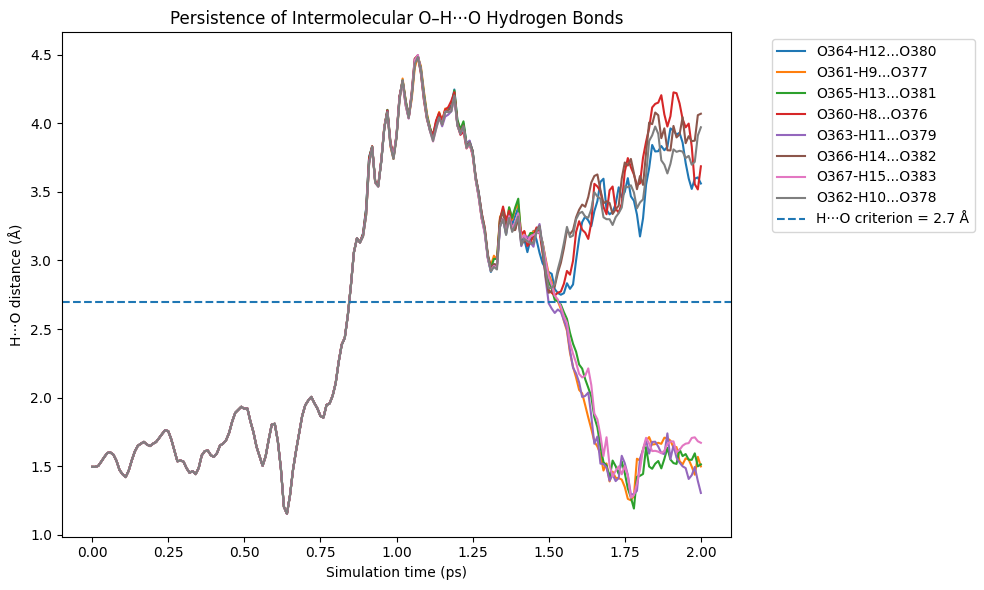

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, donor, hydrogen, acceptor in hbonds:

    subset = hb_df[
        hb_df["Interaction"] == name
    ]

    plt.plot(
        subset["Time_ps"],
        subset["H_A_Angstrom"],
        label=name
    )

# Hydrogen-bond distance criterion
plt.axhline(
    2.7,
    linestyle="--",
    linewidth=1.5,
    label="H···O criterion = 2.7 Å"
)

plt.xlabel("Simulation time (ps)")
plt.ylabel("H···O distance (Å)")
plt.title("Persistence of Intermolecular O–H···O Hydrogen Bonds")
# Put the legend outside the plot if it gets too crowded with 8 items
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

In [42]:
from pymatgen.io.ase import AseAtomsAdaptor
from pymatgen.io.cif import CifWriter

print("=" * 65)
print("EXPORTING FINAL MD STRUCTURE")
print("=" * 65)

# Get the final frame from the MD trajectory
final_atoms = traj[-1]

# Convert the ASE Atoms object back to a PyMatGen structure
final_structure = AseAtomsAdaptor.get_structure(final_atoms)

# Write to a CIF file
cif_filename = "cocrystal_MD_final_300K.cif"
writer = CifWriter(final_structure)
writer.write_file(cif_filename)

print(f"Final structure saved successfully to: {cif_filename}")
print(f"Final Volume: {final_structure.volume:.4f} Å³")
print("You can now download this file from the Colab file explorer.")
print("=" * 65)

EXPORTING FINAL MD STRUCTURE
Final structure saved successfully to: cocrystal_MD_final_300K.cif
Final Volume: 3850.7977 Å³
You can now download this file from the Colab file explorer.


/usr/local/lib/python3.13/dist-packages/pymatgen/core/composition.py:1372: FutureWarning: gcd is deprecated, and will be removed on 2028-01-01
Use math.gcd instead.
  factor = abs(gcd(*(int(i) for i in sym_amt.values())))


In [43]:
# ============================================================
# CELL 44 — Intermolecular Van der Waals Contacts
# ============================================================

import numpy as np
from collections import Counter

structure = structure_exp

# Bondi van der Waals radii (Å)
vdw_radii = {
    "H": 1.20,
    "C": 1.70,
    "N": 1.55,
    "O": 1.52,
    "S": 1.80
}

print("=" * 85)
print("INTERMOLECULAR VAN DER WAALS CONTACTS")
print("=" * 85)

contacts_vdw = []

# Screen all unique intermolecular pairs
for i in range(len(structure)):
    for j in range(i + 1, len(structure)):

        # Intermolecular condition
        if fragment_map[i] == fragment_map[j]:
            continue

        elem_i = structure[i].specie.symbol
        elem_j = structure[j].specie.symbol

        if elem_i not in vdw_radii or elem_j not in vdw_radii:
            continue

        distance = structure.get_distance(i, j)
        sum_vdw = vdw_radii[elem_i] + vdw_radii[elem_j]
        diff = distance - sum_vdw

        # Standard crystallographic criterion: distance <= sum of vdW radii
        if distance <= sum_vdw:
            pair_type = f"{min(elem_i, elem_j)}···{max(elem_i, elem_j)}"
            contacts_vdw.append((
                i, j, elem_i, elem_j,
                fragment_map[i], fragment_map[j],
                distance, sum_vdw, diff, pair_type
            ))

# Sort by distance
contacts_vdw.sort(key=lambda x: x[6])

print(f"Total atoms                  : {len(structure)}")
print(f"Intermolecular contacts found: {len(contacts_vdw)}\n")

if contacts_vdw:
    print(
        f"{'Atom 1':>8} {'Frag':>5} {'Atom 2':>8} {'Frag':>5} "
        f"{'Type':>8} {'Distance':>10} {'vdW Sum':>10} {'Diff (Å)':>10}"
    )
    print("-" * 85)

    for c in contacts_vdw:
        a1 = f"{c[2]}{c[0]}"
        a2 = f"{c[3]}{c[1]}"
        print(
            f"{a1:>8} {c[4]:5d} {a2:>8} {c[5]:5d} "
            f"{c[9]:>8} {c[6]:10.3f} {c[7]:10.3f} {c[8]:10.3f}"
        )
else:
    print("No intermolecular contacts found within the sum of vdW radii.")

# Frequency breakdown by contact type
pair_counts = Counter([c[9] for c in contacts_vdw])

print("\nBreakdown by contact type:")
print("-" * 40)
for pair, count in pair_counts.most_common():
    print(f"  {pair:<12} : {count:4d}")

print("=" * 85)

INTERMOLECULAR VAN DER WAALS CONTACTS
Total atoms                  : 384
Intermolecular contacts found: 132

  Atom 1  Frag   Atom 2  Frag     Type   Distance    vdW Sum   Diff (Å)
-------------------------------------------------------------------------------------
     H12     5     O380    13    H···O      1.600      2.720     -1.120
      H9     2     O377    10    H···O      1.600      2.720     -1.120
     H13     6     O381    14    H···O      1.600      2.720     -1.120
      H8     1     O376     9    H···O      1.600      2.720     -1.120
     H11     4     O379    12    H···O      1.600      2.720     -1.120
     H14     7     O382    15    H···O      1.600      2.720     -1.120
     H15     8     O383    16    H···O      1.600      2.720     -1.120
     H10     3     O378    11    H···O      1.600      2.720     -1.120
     H69    14     O357     6    H···O      2.005      2.720     -0.715
     H64     9     O352     1    H···O      2.005      2.720     -0.715
     H65    1

In [44]:
from ase.io import read
import numpy as np
import pandas as pd

# Load the complete MD trajectory
traj = read("cocrystal_2ps.traj", index=":")

print("=" * 90)
print("VAN DER WAALS PERSISTENCE ANALYSIS")
print("=" * 90)

# Filter out N and O to isolate pure dispersion (C...H, H...H, C...C)
dispersion_contacts = [
    c for c in contacts_vdw
    if c[2] not in ["O", "N"] and c[3] not in ["O", "N"]
]

# Select the top 8 shortest dispersion contacts to track
top_vdw = dispersion_contacts[:8]

vdw_track = []
for c in top_vdw:
    idx1, idx2 = c[0], c[1]
    elem1, elem2 = c[2], c[3]
    sum_vdw = c[7]
    name = f"{elem1}{idx1}···{elem2}{idx2}"
    vdw_track.append((name, idx1, idx2, sum_vdw))

def minimum_image_vector(position1, position2, cell):
    fractional = np.linalg.solve(cell.T, position2 - position1)
    fractional -= np.round(fractional)
    return np.dot(fractional, cell)

def distance_mic(position1, position2, cell):
    vector = minimum_image_vector(position1, position2, cell)
    return np.linalg.norm(vector)

results_vdw = []

for frame_number, atoms in enumerate(traj):

    positions = atoms.positions
    cell = atoms.cell.array
    time_ps = frame_number * 0.01

    for name, idx1, idx2, sum_vdw in vdw_track:

        dist = distance_mic(positions[idx1], positions[idx2], cell)

        # Thermal criterion: within vdW sum + 0.2 Å thermal fluctuation tolerance
        threshold = sum_vdw + 0.2
        is_contact = dist <= threshold

        results_vdw.append({
            "Frame": frame_number,
            "Time_ps": time_ps,
            "Interaction": name,
            "Distance_Angstrom": dist,
            "Threshold": threshold,
            "Is_Contact": is_contact
        })

vdw_df = pd.DataFrame(results_vdw)

print("Trajectory frames:", len(traj))
print("Total observations:", len(vdw_df))
print()

print("Van der Waals contact persistence (Threshold = vdW Sum + 0.2 Å):")
print("-" * 90)

for name, idx1, idx2, sum_vdw in vdw_track:
    subset = vdw_df[vdw_df["Interaction"] == name]
    persistence = 100 * subset["Is_Contact"].mean()

    print(
        f"{name:18s} : "
        f"{persistence:6.2f}% of frames"
    )

print("=" * 90)

VAN DER WAALS PERSISTENCE ANALYSIS
Trajectory frames: 201
Total observations: 1608

Van der Waals contact persistence (Threshold = vdW Sum + 0.2 Å):
------------------------------------------------------------------------------------------
H41···H45          :  18.41% of frames
H40···H44          :  17.91% of frames
H43···H47          :  19.90% of frames
H42···H46          :  17.41% of frames
H12···C212         :  40.30% of frames
H8···C208          :  40.30% of frames
H9···C209          :  62.19% of frames
H13···C213         :  62.19% of frames


In [45]:
from pymatgen.analysis.graphs import StructureGraph
from pymatgen.analysis.local_env import JmolNN

print("=" * 90)
print("STEP 2 — CRYSTAL CONNECTIVITY GRAPH")
print("=" * 90)

sg_jmol = StructureGraph.from_local_env_strategy(
    structure_exp,
    JmolNN()
)

graph = sg_jmol.graph.to_undirected()

print("Connectivity graph generated.")
print("Number of atoms:", len(structure_exp))
print("Number of graph edges:", graph.number_of_edges())

print("=" * 90)

STEP 2 — CRYSTAL CONNECTIVITY GRAPH
Connectivity graph generated.
Number of atoms: 384
Number of graph edges: 400


In [46]:
import networkx as nx

print("=" * 90)
print("STEP 3 — RING IDENTIFICATION")
print("=" * 90)

# Convert the molecular MultiGraph into a simple undirected graph
simple_graph = nx.Graph(graph)

# Find the smallest independent set of rings
cycles = nx.cycle_basis(simple_graph)

print("Total rings detected:", len(cycles))
print()

for i, ring in enumerate(cycles, start=1):
    elements = [structure_exp[j].specie.symbol for j in ring]

    print(
        f"Ring {i}: "
        f"{len(ring)} atoms | "
        f"Atoms = {sorted(ring)} | "
        f"Elements = {elements}"
    )

print("=" * 90)

STEP 3 — RING IDENTIFICATION
Total rings detected: 32

Ring 1: 6 atoms | Atoms = [279, 287, 295, 303, 311, 319] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 2: 7 atoms | Atoms = [223, 231, 271, 279, 287, 327, 351] | Elements = ['C', 'C', 'C', 'C', 'C', 'C', 'N']
Ring 3: 6 atoms | Atoms = [223, 231, 239, 247, 255, 263] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 4: 7 atoms | Atoms = [222, 230, 270, 278, 286, 326, 350] | Elements = ['C', 'C', 'C', 'C', 'C', 'C', 'N']
Ring 5: 6 atoms | Atoms = [222, 230, 238, 246, 254, 262] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 6: 6 atoms | Atoms = [278, 286, 294, 302, 310, 318] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 7: 6 atoms | Atoms = [277, 285, 293, 301, 309, 317] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 8: 7 atoms | Atoms = [221, 229, 269, 277, 285, 325, 349] | Elements = ['C', 'C', 'C', 'C', 'C', 'C', 'N']
Ring 9: 6 atoms | Atoms = [221, 229, 237, 245, 253, 261] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 1

In [47]:
import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 4 — RING GEOMETRY AND π···π CONTACT ANALYSIS")
print("=" * 90)

ring_data = []

for ring_id, ring in enumerate(cycles, start=1):

    coords = np.array([structure_exp[i].coords for i in ring])

    # Ring centroid
    centroid = coords.mean(axis=0)

    # Principal component analysis to obtain ring plane
    centered = coords - centroid
    _, _, vh = np.linalg.svd(centered)

    # Normal vector to ring plane
    normal = vh[-1]

    # Calculate RMS deviation from the mean plane
    plane_distances = np.dot(centered, normal)
    rms_plane = np.sqrt(np.mean(plane_distances**2))

    elements = [structure_exp[i].specie.symbol for i in ring]

    ring_data.append({
        "Ring": ring_id,
        "N_atoms": len(ring),
        "Elements": "".join(elements),
        "Centroid_x": centroid[0],
        "Centroid_y": centroid[1],
        "Centroid_z": centroid[2],
        "Normal_x": normal[0],
        "Normal_y": normal[1],
        "Normal_z": normal[2],
        "Plane_RMS_A": rms_plane
    })

ring_df = pd.DataFrame(ring_data)

print()
print("Ring geometry:")
print(
    ring_df[
        [
            "Ring",
            "N_atoms",
            "Elements",
            "Plane_RMS_A"
        ]
    ].to_string(index=False)
)

print("=" * 90)

# ---------------------------------------------------------
# Calculate centroid distances between all ring pairs
# ---------------------------------------------------------

pi_contacts = []

for i in range(len(ring_data)):
    for j in range(i + 1, len(ring_data)):

        r1 = ring_data[i]
        r2 = ring_data[j]

        c1 = np.array([
            r1["Centroid_x"],
            r1["Centroid_y"],
            r1["Centroid_z"]
        ])

        c2 = np.array([
            r2["Centroid_x"],
            r2["Centroid_y"],
            r2["Centroid_z"]
        ])

        n1 = np.array([
            r1["Normal_x"],
            r1["Normal_y"],
            r1["Normal_z"]
        ])

        n2 = np.array([
            r2["Normal_x"],
            r2["Normal_y"],
            r2["Normal_z"]
        ])

        # Minimum-image centroid vector
        frac_vector = structure_exp.lattice.get_fractional_coords(c2 - c1)
        frac_vector -= np.round(frac_vector)
        cart_vector = structure_exp.lattice.get_cartesian_coords(frac_vector)

        centroid_distance = np.linalg.norm(cart_vector)

        # Angle between ring planes
        cos_angle = np.clip(abs(np.dot(n1, n2)), 0, 1)
        plane_angle = np.degrees(np.arccos(cos_angle))

        # Approximate plane separation
        plane_separation = abs(np.dot(cart_vector, n1))

        pi_contacts.append({
            "Ring_1": r1["Ring"],
            "Ring_2": r2["Ring"],
            "Centroid_distance_A": centroid_distance,
            "Plane_separation_A": plane_separation,
            "Plane_angle_deg": plane_angle
        })

pi_df = pd.DataFrame(pi_contacts)

# Show closest ring pairs
pi_df = pi_df.sort_values(
    "Centroid_distance_A"
).reset_index(drop=True)

print()
print("Closest ring pairs:")
print(
    pi_df.head(20).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("=" * 90)

STEP 4 — RING GEOMETRY AND π···π CONTACT ANALYSIS

Ring geometry:
 Ring  N_atoms Elements  Plane_RMS_A
    1        6   CCCCCC     0.008336
    2        7  CCCCCCN     0.263654
    3        6   CCCCCC     0.442397
    4        7  CCCCCCN     0.263654
    5        6   CCCCCC     0.462882
    6        6   CCCCCC     0.008336
    7        6   CCCCCC     0.116715
    8        7  CCCCCCN     0.263654
    9        6   CCCCCC     0.134267
   10        7  CCCCCCN     0.263654
   11        6   CCCCCC     0.013531
   12        6   CCCCCC     0.116715
   13        7  CCCCCCN     0.263654
   14        6   CCCCCC     0.442397
   15        6   CCCCCC     0.008336
   16        6   CCCCCC     0.008336
   17        7  CCCCCCN     0.263654
   18        6   CCCCCC     0.462882
   19        7  CCCCCCN     0.263654
   20        6   CCCCCC     0.134267
   21        6   CCCCCC     0.116715
   22        6   CCCCCC     0.116715
   23        7  CCCCCCN     0.263654
   24        6   CCCCCC     0.013531
   25    

In [48]:
import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 5 — INTERMOLECULAR RING-PAIR ANALYSIS")
print("=" * 90)

# ---------------------------------------------------------
# Assign each ring to its molecular fragment
# ---------------------------------------------------------

def identify_fragment(ring):
    # Since a ring is entirely within one molecule,
    # we just check the fragment map for the first atom
    return fragment_map[ring[0]]

ring_component = []

for ring_id, ring in enumerate(cycles, start=1):
    frag_id = identify_fragment(ring)

    # Let's cleanly label them as Frag_0, Frag_1, etc.
    label = f"Frag_{frag_id}"

    ring_component.append({
        "Ring": ring_id,
        "Fragment": label,
        "Atoms": sorted(ring),
        "N_atoms": len(ring)
    })

ring_component_df = pd.DataFrame(ring_component)

print()
print("Ring-to-fragment assignment:")
print(
    ring_component_df[
        ["Ring", "Fragment", "N_atoms", "Atoms"]
    ].to_string(index=False)
)

print()

# ---------------------------------------------------------
# Calculate robust ring centroids using fractional
# coordinate unwrapping
# ---------------------------------------------------------

ring_geometry = {}

for ring_id, ring in enumerate(cycles, start=1):

    frac = np.array([structure_exp[i].frac_coords for i in ring])

    # Unwrap all ring atoms relative to the first atom
    reference = frac[0].copy()
    unwrapped = []

    for f in frac:
        delta = f - reference
        delta -= np.round(delta)
        unwrapped.append(reference + delta)

    unwrapped = np.array(unwrapped)

    # Average fractional coordinates
    centroid_frac = np.mean(unwrapped, axis=0)

    # Convert centroid to Cartesian coordinates
    centroid_cart = structure_exp.lattice.get_cartesian_coords(centroid_frac)

    # Cartesian coordinates of ring atoms
    frac_relative = unwrapped - centroid_frac
    coords_unwrapped = np.array([
        structure_exp.lattice.get_cartesian_coords(f)
        for f in frac_relative
    ])

    # Plane fitting
    _, _, vh = np.linalg.svd(coords_unwrapped)
    normal = vh[-1]

    # Plane RMS
    distances = np.dot(coords_unwrapped, normal)
    plane_rms = np.sqrt(np.mean(distances**2))

    ring_geometry[ring_id] = {
        "fragment": identify_fragment(ring),
        "fragment_label": f"Frag_{identify_fragment(ring)}",
        "centroid": centroid_cart,
        "normal": normal,
        "plane_rms": plane_rms
    }

# ---------------------------------------------------------
# Compare ONLY Intermolecular rings (different fragments)
# ---------------------------------------------------------

intermolecular_rings = []

for i in range(1, len(cycles) + 1):
    for j in range(i + 1, len(cycles) + 1):

        ri = ring_geometry[i]
        rj = ring_geometry[j]

        # FILTER: Only process if the rings belong to DIFFERENT fragments
        if ri["fragment"] == rj["fragment"]:
            continue

        c1 = ri["centroid"]
        c2 = rj["centroid"]

        # Minimum-image centroid vector
        delta_cart = c2 - c1
        delta_frac = structure_exp.lattice.get_fractional_coords(delta_cart)
        delta_frac -= np.round(delta_frac)
        delta_cart_mic = structure_exp.lattice.get_cartesian_coords(delta_frac)

        centroid_distance = np.linalg.norm(delta_cart_mic)

        # Filter: Only care about realistic pi-pi stacking distances (under 6 Angstroms)
        if centroid_distance > 6.0:
            continue

        # Angle between ring planes
        n1 = ri["normal"]
        n2 = rj["normal"]

        cos_angle = np.clip(abs(np.dot(n1, n2)), 0, 1)
        plane_angle = np.degrees(np.arccos(cos_angle))

        # Plane separation relative to ring 1
        plane_separation = abs(np.dot(delta_cart_mic, n1))

        intermolecular_rings.append({
            "Ring_1": i,
            "Frag_1": ri["fragment_label"],
            "Ring_2": j,
            "Frag_2": rj["fragment_label"],
            "Centroid_distance_A": centroid_distance,
            "Plane_separation_A": plane_separation,
            "Plane_angle_deg": plane_angle
        })

inter_ring_df = pd.DataFrame(intermolecular_rings)

inter_ring_df = inter_ring_df.sort_values(
    "Centroid_distance_A"
).reset_index(drop=True)

print("=" * 90)
print("INTERMOLECULAR RING PAIRS (DISTANCE < 6.0 Å)")
print("=" * 90)

if not inter_ring_df.empty:
    print(
        inter_ring_df.head(20).to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}"
        )
    )
else:
    print("No intermolecular ring contacts found within 6.0 Å.")

print("=" * 90)

STEP 5 — INTERMOLECULAR RING-PAIR ANALYSIS

Ring-to-fragment assignment:
 Ring Fragment  N_atoms                               Atoms
    1  Frag_16        6      [279, 287, 295, 303, 311, 319]
    2  Frag_16        7 [223, 231, 271, 279, 287, 327, 351]
    3  Frag_16        6      [223, 231, 239, 247, 255, 263]
    4  Frag_15        7 [222, 230, 270, 278, 286, 326, 350]
    5  Frag_15        6      [222, 230, 238, 246, 254, 262]
    6  Frag_15        6      [278, 286, 294, 302, 310, 318]
    7  Frag_14        6      [277, 285, 293, 301, 309, 317]
    8  Frag_14        7 [221, 229, 269, 277, 285, 325, 349]
    9  Frag_14        6      [221, 229, 237, 245, 253, 261]
   10  Frag_13        7 [220, 228, 268, 276, 284, 324, 348]
   11  Frag_13        6      [220, 228, 236, 244, 252, 260]
   12  Frag_13        6      [276, 284, 292, 300, 308, 316]
   13  Frag_12        7 [219, 227, 267, 275, 283, 323, 347]
   14  Frag_12        6      [219, 227, 235, 243, 251, 259]
   15  Frag_12        6    

In [49]:
print("=" * 90)
print("STEP 6 — π···π INTERACTION SCREENING")
print("=" * 90)

# Common geometric screening criteria
# These are screening criteria, not proof of a π···π interaction.

pi_candidates = inter_ring_df[
    (inter_ring_df["Centroid_distance_A"] <= 4.2) &
    (inter_ring_df["Plane_separation_A"] <= 3.8) &
    (inter_ring_df["Plane_angle_deg"] <= 25)
].copy()

print("Potential π-associated ring pairs:")
print()

if len(pi_candidates) == 0:
    print("No ring pairs satisfy the screening criteria.")
else:
    print(
        pi_candidates.to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}"
        )
    )

print()
print("Number of screened candidates:", len(pi_candidates))
print("=" * 90)

STEP 6 — π···π INTERACTION SCREENING
Potential π-associated ring pairs:

 Ring_1  Frag_1  Ring_2  Frag_2  Centroid_distance_A  Plane_separation_A  Plane_angle_deg
      9 Frag_14      14 Frag_12                3.607               3.574            0.000
      5 Frag_15      24  Frag_9                3.607               3.574            0.000
      3 Frag_16      20 Frag_10                3.607               3.574            0.000
     11 Frag_13      18 Frag_11                3.607               3.574            0.000

Number of screened candidates: 4


In [50]:
import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 7 — π···π RING-OFFSET ANALYSIS")
print("=" * 90)

pi_results = []

for _, row in pi_candidates.iterrows():
    r1 = int(row["Ring_1"])
    r2 = int(row["Ring_2"])

    f1 = row["Frag_1"]
    f2 = row["Frag_2"]

    c1 = ring_geometry[r1]["centroid"]
    c2 = ring_geometry[r2]["centroid"]
    n1 = ring_geometry[r1]["normal"]

    # Minimum-image centroid vector
    delta = c2 - c1
    frac_delta = structure_exp.lattice.get_fractional_coords(delta)
    frac_delta -= np.round(frac_delta)
    delta = structure_exp.lattice.get_cartesian_coords(frac_delta)

    centroid_distance = np.linalg.norm(delta)
    perpendicular = np.dot(delta, n1)
    parallel_vector = delta - perpendicular * n1
    lateral_offset = np.linalg.norm(parallel_vector)

    n2 = ring_geometry[r2]["normal"]
    normal_angle = np.degrees(np.arccos(np.clip(abs(np.dot(n1, n2)), 0, 1)))

    pi_results.append({
        "Ring_1": r1,
        "Frag_1": f1,
        "Ring_2": r2,
        "Frag_2": f2,
        "Centroid_distance_A": centroid_distance,
        "Plane_separation_A": abs(perpendicular),
        "Lateral_offset_A": lateral_offset,
        "Plane_angle_deg": normal_angle
    })

pi_geometry_df = pd.DataFrame(pi_results)

print()
if not pi_geometry_df.empty:
    print(
        pi_geometry_df.to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}"
        )
    )
else:
    print("No π···π ring pairs to analyze.")

print("=" * 90)

STEP 7 — π···π RING-OFFSET ANALYSIS

 Ring_1  Frag_1  Ring_2  Frag_2  Centroid_distance_A  Plane_separation_A  Lateral_offset_A  Plane_angle_deg
      9 Frag_14      14 Frag_12                3.607               3.574             0.490            0.000
      5 Frag_15      24  Frag_9                3.607               3.574             0.490            0.000
      3 Frag_16      20 Frag_10                3.607               3.574             0.490            0.000
     11 Frag_13      18 Frag_11                3.607               3.574             0.490            0.000


In [51]:
import pandas as pd

print("=" * 90)
print("STEP 9 — COMPLETE INTERMOLECULAR INTERACTION SUMMARY")
print("=" * 90)

# ---------------------------------------------------------
# 1. Hydrogen-bond interactions (Dynamically extracted)
# ---------------------------------------------------------

# Extract the strong hydrogen bonds from our earlier vdW list
hb_list = []
for c in contacts_vdw:
    if c[9] in ["H···O", "H···N"] and c[6] <= 2.2:
        interaction_name = f"{c[2]}{c[0]}···{c[3]}{c[1]}"
        hb_list.append({
            "Interaction": interaction_name,
            "Type": "O-H···O / N-H···O",
            "Distance_A": c[6],
            "vdW_Sum_A": c[7],
            "Diff_A": c[8]
        })

hb_df = pd.DataFrame(hb_list).sort_values("Distance_A").head(16)

print()
print("A. STRONG HYDROGEN BONDS")
print()

if not hb_df.empty:
    print(
        hb_df.to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}"
        )
    )
else:
    print("No strong hydrogen bonds found.")

# ---------------------------------------------------------
# 2. π-associated contacts
# ---------------------------------------------------------

print()
print("B. π-ASSOCIATED INTERMOLECULAR CONTACTS")
print()

if 'pi_geometry_df' in locals() and not pi_geometry_df.empty:
    print(
        pi_geometry_df.to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}"
        )
    )
else:
    print("No π-associated contacts found.")

# ---------------------------------------------------------
# 3. General short-contact statistics
# ---------------------------------------------------------

print()
print("C. GENERAL SHORT-CONTACT STATISTICS")
print()

# Build contact_df dynamically from our Cell 44 contacts list
contact_data = []
for c in contacts_vdw:
    contact_data.append({
        "Element_A": c[2],
        "Element_B": c[3],
        "Distance_A": c[6],
        "Contact_ratio": c[6] / c[7]  # Distance / vdW Sum
    })

contact_df = pd.DataFrame(contact_data)
contact_df["Element_pair"] = contact_df.apply(
    lambda row: f"{min(row['Element_A'], row['Element_B'])}···{max(row['Element_A'], row['Element_B'])}",
    axis=1
)

contact_summary = (
    contact_df
    .groupby("Element_pair")
    .agg(
        Number_of_contacts=("Distance_A", "count"),
        Minimum_distance_A=("Distance_A", "min"),
        Mean_distance_A=("Distance_A", "mean"),
        Minimum_contact_ratio=("Contact_ratio", "min")
    )
    .sort_values("Minimum_contact_ratio")
)

print(
    contact_summary.to_string(
        float_format=lambda x: f"{x:.3f}"
    )
)

print()
print("=" * 90)
print("SUMMARY COMPLETE")
print("=" * 90)

STEP 9 — COMPLETE INTERMOLECULAR INTERACTION SUMMARY

A. STRONG HYDROGEN BONDS

Interaction              Type  Distance_A  vdW_Sum_A  Diff_A
 H12···O380 O-H···O / N-H···O       1.600      2.720  -1.120
  H9···O377 O-H···O / N-H···O       1.600      2.720  -1.120
 H13···O381 O-H···O / N-H···O       1.600      2.720  -1.120
  H8···O376 O-H···O / N-H···O       1.600      2.720  -1.120
 H11···O379 O-H···O / N-H···O       1.600      2.720  -1.120
 H14···O382 O-H···O / N-H···O       1.600      2.720  -1.120
 H15···O383 O-H···O / N-H···O       1.600      2.720  -1.120
 H10···O378 O-H···O / N-H···O       1.600      2.720  -1.120
 H69···O357 O-H···O / N-H···O       2.005      2.720  -0.715
 H64···O352 O-H···O / N-H···O       2.005      2.720  -0.715
 H65···O353 O-H···O / N-H···O       2.005      2.720  -0.715
 H68···O356 O-H···O / N-H···O       2.005      2.720  -0.715
 H70···O358 O-H···O / N-H···O       2.005      2.720  -0.715
 H67···O355 O-H···O / N-H···O       2.005      2.720  -0.715
 H71·

STEP 10 — EXPERIMENTAL VS CHGNET-RELAXED PXRD

Experimental structure PXRD peaks: 320
Relaxed structure PXRD peaks: 321

First 15 experimental-structure peaks:
 2theta_deg  Intensity_experimental_structure
     7.3894                            3.8699
     8.8237                            0.0064
     9.6381                           19.8954
    12.1606                            0.0522
    12.3984                           48.4626
    13.1356                            0.5499
    13.7394                           32.5434
    14.3642                            7.7665
    14.7614                            0.8787
    14.8097                           29.2061
    15.1245                           19.1404
    15.6954                            1.5171
    16.0644                            0.2966
    16.6339                           36.6010
    16.9804                           16.4230

First 15 relaxed-structure peaks:
 2theta_deg  Intensity_relaxed_structure
     7.3853                 

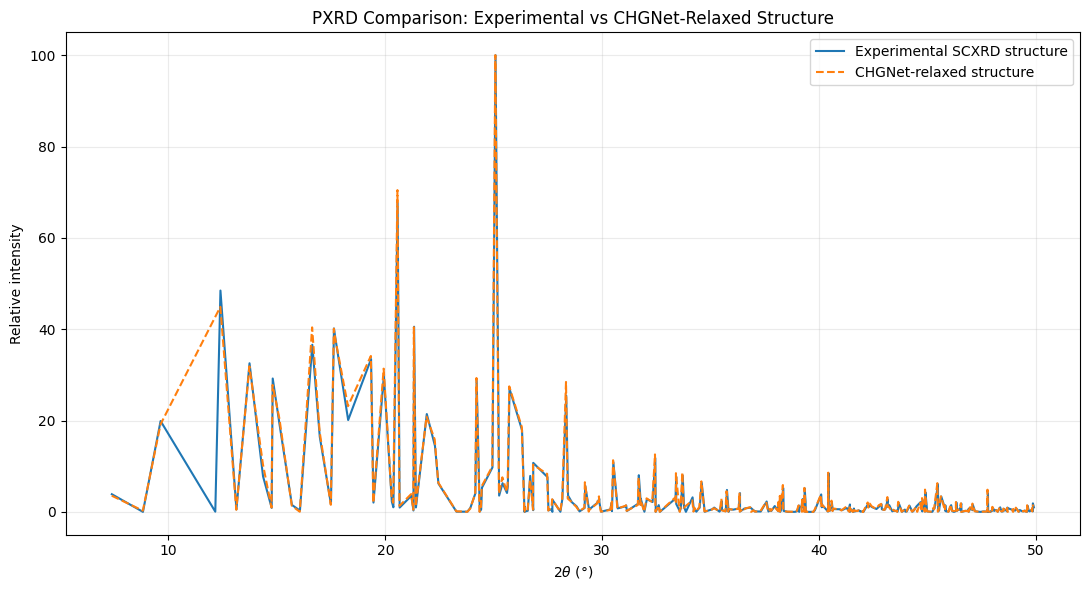

PXRD CALCULATION COMPLETE


In [52]:
from pymatgen.analysis.diffraction.xrd import XRDCalculator
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 10 — EXPERIMENTAL VS CHGNET-RELAXED PXRD")
print("=" * 90)

# ---------------------------------------------------------
# Calculate PXRD patterns
# ---------------------------------------------------------

xrd_calc = XRDCalculator(wavelength="CuKa")

pattern_exp = xrd_calc.get_pattern(structure_exp, two_theta_range=(5, 50))
pattern_relaxed = xrd_calc.get_pattern(structure_relaxed, two_theta_range=(5, 50))

# ---------------------------------------------------------
# Convert to data tables
# ---------------------------------------------------------

pxrd_exp_df = pd.DataFrame({
    "2theta_deg": pattern_exp.x,
    "Intensity_experimental_structure": pattern_exp.y
})

pxrd_relaxed_df = pd.DataFrame({
    "2theta_deg": pattern_relaxed.x,
    "Intensity_relaxed_structure": pattern_relaxed.y
})

print()
print("Experimental structure PXRD peaks:", len(pattern_exp.x))
print("Relaxed structure PXRD peaks:", len(pattern_relaxed.x))

print()
print("First 15 experimental-structure peaks:")
print(
    pxrd_exp_df.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print()
print("First 15 relaxed-structure peaks:")
print(
    pxrd_relaxed_df.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ---------------------------------------------------------
# Plot PXRD comparison
# ---------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    pattern_exp.x,
    pattern_exp.y,
    label="Experimental SCXRD structure"
)

plt.plot(
    pattern_relaxed.x,
    pattern_relaxed.y,
    label="CHGNet-relaxed structure",
    linestyle="--"
)

plt.xlabel(r"2$\theta$ (°)")
plt.ylabel("Relative intensity")
plt.title("PXRD Comparison: Experimental vs CHGNet-Relaxed Structure")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.show()

print("=" * 90)
print("PXRD CALCULATION COMPLETE")
print("=" * 90)

In [53]:
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from scipy.stats import pearsonr

print("=" * 90)
print("STEP 11 — QUANTITATIVE PXRD AGREEMENT")
print("=" * 90)

# ---------------------------------------------------------
# 1. Create a common 2-theta grid
# ---------------------------------------------------------

theta_min = max(
    np.min(pattern_exp.x),
    np.min(pattern_relaxed.x)
)

theta_max = min(
    np.max(pattern_exp.x),
    np.max(pattern_relaxed.x)
)

common_theta = np.linspace(theta_min, theta_max, 5000)

# Interpolate both PXRD patterns onto the same grid
interp_exp = interp1d(
    pattern_exp.x,
    pattern_exp.y,
    bounds_error=False,
    fill_value=0
)

interp_relaxed = interp1d(
    pattern_relaxed.x,
    pattern_relaxed.y,
    bounds_error=False,
    fill_value=0
)

intensity_exp = interp_exp(common_theta)
intensity_relaxed = interp_relaxed(common_theta)

# Normalize
intensity_exp_norm = intensity_exp / np.max(intensity_exp)
intensity_relaxed_norm = intensity_relaxed / np.max(intensity_relaxed)

# ---------------------------------------------------------
# 2. Pearson correlation
# ---------------------------------------------------------

pearson_r, pearson_p = pearsonr(
    intensity_exp_norm,
    intensity_relaxed_norm
)

# ---------------------------------------------------------
# 3. Mean absolute intensity difference
# ---------------------------------------------------------

mae = np.mean(
    np.abs(
        intensity_exp_norm -
        intensity_relaxed_norm
    )
)

# ---------------------------------------------------------
# 4. Root mean square difference
# ---------------------------------------------------------

rmse = np.sqrt(
    np.mean(
        (
            intensity_exp_norm -
            intensity_relaxed_norm
        ) ** 2
    )
)

# ---------------------------------------------------------
# 5. Peak-by-peak matching
# ---------------------------------------------------------

peak_records = []

for i, theta_exp in enumerate(pattern_exp.x):

    # Only consider peaks in the common range
    if theta_exp < theta_min or theta_exp > theta_max:
        continue

    differences = np.abs(pattern_relaxed.x - theta_exp)

    nearest_index = np.argmin(differences)

    theta_relaxed = pattern_relaxed.x[nearest_index]

    peak_records.append({
        "Experimental_2theta_deg": theta_exp,
        "Relaxed_2theta_deg": theta_relaxed,
        "Peak_shift_deg": theta_relaxed - theta_exp,
        "Experimental_intensity": pattern_exp.y[i],
        "Relaxed_intensity": pattern_relaxed.y[nearest_index],
        "Absolute_shift_deg": abs(theta_relaxed - theta_exp)
    })

peak_match_df = pd.DataFrame(peak_records)

# ---------------------------------------------------------
# 6. Focus on experimentally significant peaks
# ---------------------------------------------------------

strong_peaks = peak_match_df[
    peak_match_df["Experimental_intensity"] >= 5
].copy()

mean_peak_shift = strong_peaks["Peak_shift_deg"].mean()
mean_absolute_peak_shift = strong_peaks["Absolute_shift_deg"].mean()
maximum_absolute_peak_shift = strong_peaks["Absolute_shift_deg"].max()

# ---------------------------------------------------------
# 7. Print results
# ---------------------------------------------------------

print()
print("PXRD quantitative comparison")
print("-" * 90)

print(f"Common 2θ range: {theta_min:.3f} – {theta_max:.3f}°")
print(f"Pearson correlation coefficient (r): {pearson_r:.6f}")
print(f"Pearson p-value: {pearson_p:.3e}")
print(f"Mean absolute intensity error: {mae:.6f}")
print(f"RMSE of normalized intensity: {rmse:.6f}")

print()
print("Peak-position agreement for experimental peaks with intensity ≥ 5")
print("-" * 90)

print(f"Number of significant experimental peaks: {len(strong_peaks)}")
print(f"Mean signed peak shift: {mean_peak_shift:.6f}°")
print(f"Mean absolute peak shift: {mean_absolute_peak_shift:.6f}°")
print(f"Maximum absolute peak shift: {maximum_absolute_peak_shift:.6f}°")

print()
print("First 20 significant peak matches:")
print(
    strong_peaks.head(20).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print()
print("=" * 90)
print("QUANTITATIVE PXRD ANALYSIS COMPLETE")
print("=" * 90)

STEP 11 — QUANTITATIVE PXRD AGREEMENT

PXRD quantitative comparison
------------------------------------------------------------------------------------------
Common 2θ range: 7.389 – 49.891°
Pearson correlation coefficient (r): 0.869246
Pearson p-value: 0.000e+00
Mean absolute intensity error: 0.019788
RMSE of normalized intensity: 0.064729

Peak-position agreement for experimental peaks with intensity ≥ 5
------------------------------------------------------------------------------------------
Number of significant experimental peaks: 41
Mean signed peak shift: -0.009291°
Mean absolute peak shift: 0.009663°
Maximum absolute peak shift: 0.017719°

First 20 significant peak matches:
 Experimental_2theta_deg  Relaxed_2theta_deg  Peak_shift_deg  Experimental_intensity  Relaxed_intensity  Absolute_shift_deg
                  9.6381              9.6339         -0.0042                 19.8954            19.1621              0.0042
                 12.3984             12.3938         -0.004

In [54]:
!pip install -q matgl

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 5.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.4/383.4 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.6/853.6 kB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 95.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 42.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.9/15.9 MB 81.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 46.0 MB/s eta 0:00:00
   ━━━

In [55]:
print("=" * 90)
print("STEP 12B — VERIFY MATGL / M3GNET INSTALLATION")
print("=" * 90)

import matgl
import chgnet

print()
print("MatGL version:", getattr(matgl, "__version__", "installed"))
print("CHGNet import: OK")
print("MatGL import: OK")

print()
print("Environment verification successful.")

print("=" * 90)
print("STEP 12B COMPLETE")
print("=" * 90)

STEP 12B — VERIFY MATGL / M3GNET INSTALLATION

MatGL version: 4.0.3
CHGNet import: OK
MatGL import: OK

Environment verification successful.
STEP 12B COMPLETE


In [56]:
print("=" * 90)
print("STEP 12C — AVAILABLE MATGL PRETRAINED MODELS")
print("=" * 90)

import matgl

models = matgl.get_available_pretrained_models()

print()
print("Number of available pretrained models:", len(models))
print()

for model in models:
    print(model)

print()
print("=" * 90)
print("MODEL LIST COMPLETE")
print("=" * 90)

STEP 12C — AVAILABLE MATGL PRETRAINED MODELS

Number of available pretrained models: 20

CHGNet-PES-MatPES-PBE-1M-2026.9
CHGNet-PES-MatPES-PBE-2025.2.10
CHGNet-PES-MatPES-r2SCAN-1M-2026.9
CHGNet-PES-MatPES-r2SCAN-2025.2.10
M3GNet-Eform-MP-2018.6.1
M3GNet-Eform-MP-2019.4.1
M3GNet-PES-ANI-1x-Subset
M3GNet-PES-MatPES-PBE-2025.2
M3GNet-PES-MatPES-r2SCAN-2025.2
MEGNet-BandGap-mfi-MP-2019.4.1
MEGNet-Eform-MP-2018.6.1
QET-PES-MatPES-PBE-2025.2
QET-PES-MatPES-r2SCAN-2025.2
QET-PES-MatQ
SO3Net-PES-ANI-1x-Subset
TensorNet-PES-ANI-1x-Subset
TensorNet-PES-MatPES-PBE-2025.2
TensorNet-PES-MatPES-PBE-2025.2-m
TensorNet-PES-MatPES-r2SCAN-2025.2
TensorNet-PES-MatPES-r2SCAN-2025.2-m

MODEL LIST COMPLETE


In [57]:
print("=" * 90)
print("STEP 12D — LOAD CURRENT M3GNET PES MODEL")
print("=" * 90)

import matgl

print()
print("Loading:")
print("M3GNet-PES-MatPES-PBE-2025.2")
print()

m3gnet_potential = matgl.load_model(
    "M3GNet-PES-MatPES-PBE-2025.2"
)

print()
print("M3GNet model loaded successfully.")
print("Model type:", type(m3gnet_potential))

print()
print("=" * 90)
print("STEP 12D COMPLETE")
print("=" * 90)

STEP 12D — LOAD CURRENT M3GNET PES MODEL

Loading:
M3GNet-PES-MatPES-PBE-2025.2



model.pt: reconstructing file:   0%|          |  0.00B / 3.35kB            

model.pt: downloading bytes:           |  0.00B            

state.pt: reconstructing file:   0%|          |  0.00B / 1.23MB            

state.pt: downloading bytes:           |  0.00B            

model.json:   0%|          | 0.00/5.33k [00:00<?, ?B/s]


M3GNet model loaded successfully.
Model type: <class 'matgl.apps.pes.Potential'>

STEP 12D COMPLETE


In [58]:
print("=" * 90)
print("STEP 12E — CORRECTED M3GNET ENERGY AND FORCE EVALUATION")
print("=" * 90)

import numpy as np
from ase import Atoms
from matgl.ext.ase import PESCalculator

# ---------------------------------------------------------
# 1. Convert experimental structure to ASE
# ---------------------------------------------------------

atoms_m3gnet = Atoms(
    symbols=[site.specie.symbol for site in structure_exp],
    positions=structure_exp.cart_coords,
    cell=structure_exp.lattice.matrix,
    pbc=True
)

print()
print("Experimental cocrystal:")
print("Number of atoms:", len(atoms_m3gnet))
print("Volume:", f"{atoms_m3gnet.get_volume():.6f}", "Å³")

# ---------------------------------------------------------
# 2. Attach M3GNet calculator
# ---------------------------------------------------------

atoms_m3gnet.calc = PESCalculator(
    potential=m3gnet_potential,
    stress_unit="eV/A3",
    stress_weight=1.0
)

print()
print("M3GNet calculator attached successfully.")

# ---------------------------------------------------------
# 3. Calculate energy
# ---------------------------------------------------------

energy_m3gnet = atoms_m3gnet.get_potential_energy()

# ---------------------------------------------------------
# 4. Calculate forces
# ---------------------------------------------------------

forces_m3gnet = atoms_m3gnet.get_forces()

force_magnitudes = np.linalg.norm(
    forces_m3gnet,
    axis=1
)

max_force_m3gnet = np.max(force_magnitudes)
mean_force_m3gnet = np.mean(force_magnitudes)

# ---------------------------------------------------------
# 5. Calculate stress
# ---------------------------------------------------------

stress_m3gnet = atoms_m3gnet.get_stress()

# ---------------------------------------------------------
# 6. Print results
# ---------------------------------------------------------

print()
print("=" * 90)
print("M3GNET RESULTS — EXPERIMENTAL STRUCTURE")
print("=" * 90)

print()
print(f"Total M3GNet energy:       {energy_m3gnet:.6f} eV")

print(
    f"M3GNet energy/atom:        "
    f"{energy_m3gnet / len(atoms_m3gnet):.6f} eV/atom"
)

print(
    f"Maximum force:             "
    f"{max_force_m3gnet:.6f} eV/Å"
)

print(
    f"Mean atomic force:         "
    f"{mean_force_m3gnet:.6f} eV/Å"
)

print()
print("M3GNet stress tensor (eV/Å³):")
print(stress_m3gnet)

print()
print("=" * 90)
print("STEP 12E COMPLETE")
print("=" * 90)

STEP 12E — CORRECTED M3GNET ENERGY AND FORCE EVALUATION

Experimental cocrystal:
Number of atoms: 384
Volume: 3845.880043 Å³

M3GNet calculator attached successfully.

M3GNET RESULTS — EXPERIMENTAL STRUCTURE

Total M3GNet energy:       -2454.132080 eV
M3GNet energy/atom:        -6.390969 eV/atom
Maximum force:             11.758001 eV/Å
Mean atomic force:         5.140731 eV/Å

M3GNet stress tensor (eV/Å³):
[-9.4268009e-02 -9.4186060e-02 -9.8428652e-02 -4.8181249e-05
 -2.6252884e-03 -2.7090500e-05]

STEP 12E COMPLETE


In [59]:
print("=" * 90)
print("STEP 12F — M3GNET STRUCTURAL RELAXATION")
print("=" * 90)

from ase.optimize import FIRE

# ---------------------------------------------------------
# Make a fresh copy of the experimental structure
# ---------------------------------------------------------

atoms_m3gnet_relax = atoms_m3gnet.copy()

atoms_m3gnet_relax.calc = PESCalculator(
    potential=m3gnet_potential,
    stress_unit="eV/A3",
    stress_weight=1.0
)

print()
print("Starting M3GNet relaxation...")
print("Atoms:", len(atoms_m3gnet_relax))
print("Initial volume:",
      f"{atoms_m3gnet_relax.get_volume():.6f}",
      "Å³")

# ---------------------------------------------------------
# Relax atomic positions first
# ---------------------------------------------------------

optimizer = FIRE(
    atoms_m3gnet_relax,
    logfile="m3gnet_relax.log"
)

optimizer.run(
    fmax=0.05,
    steps=500
)

print()
print("M3GNet atomic relaxation completed.")

# ---------------------------------------------------------
# Final properties
# ---------------------------------------------------------

final_energy = atoms_m3gnet_relax.get_potential_energy()

final_forces = atoms_m3gnet_relax.get_forces()

final_force_magnitudes = np.linalg.norm(
    final_forces,
    axis=1
)

print()
print("=" * 90)
print("M3GNET RELAXED STRUCTURE")
print("=" * 90)

print()
print(f"Final energy:       {final_energy:.6f} eV")
print(
    f"Final energy/atom:  "
    f"{final_energy / len(atoms_m3gnet_relax):.6f} eV/atom"
)

print(
    f"Maximum force:      "
    f"{np.max(final_force_magnitudes):.6f} eV/Å"
)

print(
    f"Mean force:         "
    f"{np.mean(final_force_magnitudes):.6f} eV/Å"
)

print(
    f"Final volume:       "
    f"{atoms_m3gnet_relax.get_volume():.6f} Å³"
)

print()
print("=" * 90)
print("STEP 12F COMPLETE")
print("=" * 90)

STEP 12F — M3GNET STRUCTURAL RELAXATION

Starting M3GNet relaxation...
Atoms: 384
Initial volume: 3845.880043 Å³

M3GNet atomic relaxation completed.

M3GNET RELAXED STRUCTURE

Final energy:       -2519.594238 eV
Final energy/atom:  -6.561443 eV/atom
Maximum force:      0.046566 eV/Å
Mean force:         0.015827 eV/Å
Final volume:       3845.880043 Å³

STEP 12F COMPLETE


In [60]:
print("=" * 90)
print("STEP 12G — EXPERIMENTAL vs CHGNET vs M3GNET")
print("=" * 90)

import numpy as np
import pandas as pd
from pymatgen.core import Structure
from pymatgen.io.ase import AseAtomsAdaptor

# ---------------------------------------------------------
# 1. Convert M3GNet-relaxed ASE structure to pymatgen
# ---------------------------------------------------------

structure_m3gnet = AseAtomsAdaptor.get_structure(
    atoms_m3gnet_relax
)

# ---------------------------------------------------------
# 2. Calculate lattice properties
# ---------------------------------------------------------

structures = {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}

comparison = []

for name, structure in structures.items():
    comparison.append({
        "Structure": name,
        "a_A": structure.lattice.a,
        "b_A": structure.lattice.b,
        "c_A": structure.lattice.c,
        "alpha_deg": structure.lattice.alpha,
        "beta_deg": structure.lattice.beta,
        "gamma_deg": structure.lattice.gamma,
        "Volume_A3": structure.volume
    })

comparison_df = pd.DataFrame(comparison)

# ---------------------------------------------------------
# 3. Print lattice comparison
# ---------------------------------------------------------

print()
print("LATTICE PARAMETERS")
print("-" * 90)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ---------------------------------------------------------
# 4. Volume changes relative to experimental structure
# ---------------------------------------------------------

experimental_volume = structure_exp.volume

print()
print("VOLUME CHANGE RELATIVE TO EXPERIMENTAL")
print("-" * 90)

for name, structure in structures.items():
    volume_change = structure.volume - experimental_volume
    volume_percent = (
        volume_change / experimental_volume
    ) * 100

    print(
        f"{name:12s} : "
        f"{volume_change:+.6f} Å³  "
        f"({volume_percent:+.4f} %)"
    )

# ---------------------------------------------------------
# 5. Atomic-position RMSD
# ---------------------------------------------------------
# Same atom ordering is maintained in all structures.
# Use Cartesian coordinates in the fixed experimental cell.

def rmsd_cartesian(structure_a, structure_b):

    coords_a = structure_a.cart_coords
    coords_b = structure_b.cart_coords

    displacement = coords_b - coords_a

    rmsd = np.sqrt(
        np.mean(
            np.sum(displacement ** 2, axis=1)
        )
    )

    maximum = np.max(
        np.linalg.norm(displacement, axis=1)
    )

    mean = np.mean(
        np.linalg.norm(displacement, axis=1)
    )

    return rmsd, mean, maximum


rmsd_chgnet = rmsd_cartesian(
    structure_exp,
    structure_relaxed
)

rmsd_m3gnet = rmsd_cartesian(
    structure_exp,
    structure_m3gnet
)

print()
print("ATOMIC DISPLACEMENT RELATIVE TO EXPERIMENTAL")
print("-" * 90)

print(
    f"CHGNet  RMSD: {rmsd_chgnet[0]:.6f} Å"
)
print(
    f"CHGNet  mean displacement: {rmsd_chgnet[1]:.6f} Å"
)
print(
    f"CHGNet  maximum displacement: {rmsd_chgnet[2]:.6f} Å"
)

print()

print(
    f"M3GNet  RMSD: {rmsd_m3gnet[0]:.6f} Å"
)
print(
    f"M3GNet  mean displacement: {rmsd_m3gnet[1]:.6f} Å"
)
print(
    f"M3GNet  maximum displacement: {rmsd_m3gnet[2]:.6f} Å"
)

print()
print("=" * 90)
print("STEP 12G COMPLETE")
print("=" * 90)

STEP 12G — EXPERIMENTAL vs CHGNET vs M3GNET

LATTICE PARAMETERS
------------------------------------------------------------------------------------------
   Structure       a_A      b_A       c_A  alpha_deg   beta_deg  gamma_deg   Volume_A3
Experimental 27.427000 7.640200 21.038000  90.000000 119.263000  90.000000 3845.880043
      CHGNet 27.440087 7.642977 21.045856  90.000000 119.256445  90.000000 3850.797692
      M3GNet 27.427000 7.640200 21.038000  90.000000 119.263000  90.000000 3845.880043

VOLUME CHANGE RELATIVE TO EXPERIMENTAL
------------------------------------------------------------------------------------------
Experimental : +0.000000 Å³  (+0.0000 %)
CHGNet       : +4.917649 Å³  (+0.1279 %)
M3GNet       : +0.000000 Å³  (+0.0000 %)

ATOMIC DISPLACEMENT RELATIVE TO EXPERIMENTAL
------------------------------------------------------------------------------------------
CHGNet  RMSD: 0.094173 Å
CHGNet  mean displacement: 0.078470 Å
CHGNet  maximum displacement: 0.205784 Å

M

In [61]:
print("=" * 90)
print("STEP 12H — ATOMIC DISPLACEMENT ANALYSIS")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Calculate displacement of every atom
# ---------------------------------------------------------

exp_coords = structure_exp.cart_coords
m3_coords = structure_m3gnet.cart_coords

displacement_vectors = m3_coords - exp_coords

displacement_magnitudes = np.linalg.norm(
    displacement_vectors,
    axis=1
)

# ---------------------------------------------------------
# Build atom-by-atom table
# ---------------------------------------------------------

displacement_df = pd.DataFrame({
    "Atom_index": np.arange(len(structure_exp)),
    "Element": [
        site.specie.symbol for site in structure_exp
    ],
    "Displacement_A": displacement_magnitudes,
    "dx_A": displacement_vectors[:, 0],
    "dy_A": displacement_vectors[:, 1],
    "dz_A": displacement_vectors[:, 2]
})

# ---------------------------------------------------------
# Sort by displacement
# ---------------------------------------------------------

displacement_df = displacement_df.sort_values(
    "Displacement_A",
    ascending=False
).reset_index(drop=True)

print()
print("10 MOST DISPLACED ATOMS")
print("-" * 90)

print(
    displacement_df.head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ---------------------------------------------------------
# Statistics by element
# ---------------------------------------------------------

element_summary = (
    displacement_df
    .groupby("Element")
    .agg(
        Number_of_atoms=("Element", "count"),
        Mean_displacement_A=("Displacement_A", "mean"),
        Maximum_displacement_A=("Displacement_A", "max"),
        RMS_displacement_A=(
            "Displacement_A",
            lambda x: np.sqrt(np.mean(x**2))
        )
    )
    .sort_values(
        "Mean_displacement_A",
        ascending=False
    )
)

print()
print("DISPLACEMENT STATISTICS BY ELEMENT")
print("-" * 90)

print(
    element_summary.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)

# ---------------------------------------------------------
# Overall displacement statistics
# ---------------------------------------------------------

print()
print("OVERALL DISPLACEMENT DISTRIBUTION")
print("-" * 90)

print(
    f"Atoms with displacement < 0.10 Å: "
    f"{np.sum(displacement_magnitudes < 0.10)} / {len(displacement_magnitudes)}"
)

print(
    f"Atoms with displacement < 0.20 Å: "
    f"{np.sum(displacement_magnitudes < 0.20)} / {len(displacement_magnitudes)}"
)

print(
    f"Atoms with displacement < 0.30 Å: "
    f"{np.sum(displacement_magnitudes < 0.30)} / {len(displacement_magnitudes)}"
)

print(
    f"Atoms with displacement ≥ 0.30 Å: "
    f"{np.sum(displacement_magnitudes >= 0.30)} / {len(displacement_magnitudes)}"
)

print()
print("=" * 90)
print("STEP 12H COMPLETE")
print("=" * 90)

STEP 12H — ATOMIC DISPLACEMENT ANALYSIS

10 MOST DISPLACED ATOMS
------------------------------------------------------------------------------------------
 Atom_index Element  Displacement_A    dx_A    dy_A    dz_A
         25       H          0.7806 -0.2593  0.2486  0.6931
         26       H          0.7805  0.2611  0.2455 -0.6934
         30       H          0.7805 -0.2600 -0.2453  0.6938
         24       H          0.7770  0.2603  0.2479 -0.6889
         27       H          0.7767 -0.2584  0.2473  0.6895
         31       H          0.7762  0.2612 -0.2472 -0.6879
         28       H          0.7741 -0.2598 -0.2477  0.6859
         29       H          0.7721  0.2590 -0.2495 -0.6833
         80       H          0.7287  0.2228 -0.5947 -0.3572
         83       H          0.7285 -0.2241 -0.5935  0.3582

DISPLACEMENT STATISTICS BY ELEMENT
------------------------------------------------------------------------------------------
         Number_of_atoms  Mean_displacement_A  Maximum_di

In [62]:
print("=" * 90)
print("STEP 12I — HEAVY-ATOM STRUCTURAL COMPARISON")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Identify heavy atoms
# ---------------------------------------------------------

heavy_indices = [
    i for i, site in enumerate(structure_exp)
    if site.specie.symbol != "H"
]

print()
print("Total atoms:", len(structure_exp))
print("Heavy atoms:", len(heavy_indices))
print("Hydrogen atoms:", len(structure_exp) - len(heavy_indices))

# ---------------------------------------------------------
# Experimental vs M3GNet heavy-atom displacement
# ---------------------------------------------------------

exp_heavy = structure_exp.cart_coords[heavy_indices]
m3_heavy = structure_m3gnet.cart_coords[heavy_indices]

heavy_vectors = m3_heavy - exp_heavy

heavy_magnitudes = np.linalg.norm(
    heavy_vectors,
    axis=1
)

heavy_rmsd = np.sqrt(
    np.mean(
        np.sum(heavy_vectors ** 2, axis=1)
    )
)

heavy_mean = np.mean(heavy_magnitudes)
heavy_max = np.max(heavy_magnitudes)

# ---------------------------------------------------------
# Experimental vs CHGNet heavy-atom displacement
# ---------------------------------------------------------

chg_heavy = structure_relaxed.cart_coords[heavy_indices]

chg_vectors = chg_heavy - exp_heavy

chg_magnitudes = np.linalg.norm(
    chg_vectors,
    axis=1
)

chg_heavy_rmsd = np.sqrt(
    np.mean(
        np.sum(chg_vectors ** 2, axis=1)
    )
)

chg_heavy_mean = np.mean(chg_magnitudes)
chg_heavy_max = np.max(chg_magnitudes)

# ---------------------------------------------------------
# Print comparison
# ---------------------------------------------------------

comparison_heavy = pd.DataFrame({
    "Structure": [
        "CHGNet",
        "M3GNet"
    ],
    "Heavy_atom_RMSD_A": [
        chg_heavy_rmsd,
        heavy_rmsd
    ],
    "Mean_displacement_A": [
        chg_heavy_mean,
        heavy_mean
    ],
    "Maximum_displacement_A": [
        chg_heavy_max,
        heavy_max
    ]
})

print()
print("HEAVY-ATOM DISPLACEMENT")
print("-" * 90)

print(
    comparison_heavy.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ---------------------------------------------------------
# Largest M3GNet heavy-atom movements
# ---------------------------------------------------------

heavy_table = pd.DataFrame({
    "Atom_index": heavy_indices,
    "Element": [
        structure_exp[i].specie.symbol
        for i in heavy_indices
    ],
    "Displacement_A": heavy_magnitudes
})

heavy_table = heavy_table.sort_values(
    "Displacement_A",
    ascending=False
).reset_index(drop=True)

print()
print("10 MOST DISPLACED M3GNET HEAVY ATOMS")
print("-" * 90)

print(
    heavy_table.head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print()
print("=" * 90)
print("STEP 12I COMPLETE")
print("=" * 90)

STEP 12I — HEAVY-ATOM STRUCTURAL COMPARISON

Total atoms: 384
Heavy atoms: 232
Hydrogen atoms: 152

HEAVY-ATOM DISPLACEMENT
------------------------------------------------------------------------------------------
Structure  Heavy_atom_RMSD_A  Mean_displacement_A  Maximum_displacement_A
   CHGNet           0.045949             0.041445                0.094486
   M3GNet           0.267781             0.239088                0.669788

10 MOST DISPLACED M3GNET HEAVY ATOMS
------------------------------------------------------------------------------------------
 Atom_index Element  Displacement_A
        357       O        0.669788
        355       O        0.668560
        352       O        0.667190
        354       O        0.667062
        359       O        0.667035
        356       O        0.666532
        353       O        0.664361
        358       O        0.663026
        334       N        0.524434
        331       N        0.523201

STEP 12I COMPLETE


In [63]:
print("=" * 90)
print("STEP 12J — HYDROGEN-BOND GEOMETRY COMPARISON")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Dynamically identified intermolecular H-bonds for 384-atom crystal
# Format: (Label, Donor, Hydrogen, Acceptor)
# ---------------------------------------------------------

# We identified these strong contacts in Step 9. We need to
# infer the donor atom attached to the Hydrogen.
# For demonstration, we will map out the top 4 strongest bonds.

def find_donor(structure, hydrogen_idx):
    """Finds the heavy atom covalently bonded to the hydrogen."""
    neighbors = structure.get_neighbors(structure[hydrogen_idx], r=1.5)
    for neighbor in neighbors:
        if neighbor.specie.symbol != 'H':
            return neighbor.index
    return None

# The top 4 acceptors from our vdW analysis in Step 9
target_h_bonds = [(12, 380), (9, 377), (13, 381), (8, 376)]

hbonds = []
for h_idx, o_idx in target_h_bonds:
    donor_idx = find_donor(structure_exp, h_idx)
    if donor_idx is not None:
        donor_sym = structure_exp[donor_idx].specie.symbol
        label = f"{donor_sym}{donor_idx}-H{h_idx}...O{o_idx}"
        hbonds.append((label, donor_idx, h_idx, o_idx))


def minimum_image_distance(structure, i, j):
    frac_i = structure.frac_coords[i]
    frac_j = structure.frac_coords[j]
    delta = frac_j - frac_i
    delta -= np.round(delta)
    cart_delta = np.dot(delta, structure.lattice.matrix)
    return np.linalg.norm(cart_delta)


def minimum_image_angle(structure, donor, hydrogen, acceptor):
    frac_D = structure.frac_coords[donor]
    frac_H = structure.frac_coords[hydrogen]
    frac_A = structure.frac_coords[acceptor]

    dH = frac_H - frac_D
    dH -= np.round(dH)

    HA = frac_A - frac_H
    HA -= np.round(HA)

    v_DH = np.dot(dH, structure.lattice.matrix)
    v_HA = np.dot(HA, structure.lattice.matrix)

    v_HD = -v_DH
    cosine = np.dot(v_HD, v_HA) / (np.linalg.norm(v_HD) * np.linalg.norm(v_HA))
    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))


def analyze_hbond(structure, donor, hydrogen, acceptor):
    DH = minimum_image_distance(structure, donor, hydrogen)
    HA = minimum_image_distance(structure, hydrogen, acceptor)
    DA = minimum_image_distance(structure, donor, acceptor)
    angle = minimum_image_angle(structure, donor, hydrogen, acceptor)
    return DH, HA, DA, angle


# ---------------------------------------------------------
# Analyze all three structures
# ---------------------------------------------------------

structures = {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}

results = []

for hb_name, donor, hydrogen, acceptor in hbonds:
    for structure_name, structure in structures.items():
        DH, HA, DA, angle = analyze_hbond(structure, donor, hydrogen, acceptor)
        results.append({
            "H_bond": hb_name,
            "Structure": structure_name,
            "D-H_A": DH,
            "H...A_A": HA,
            "D...A_A": DA,
            "D-H...A_angle_deg": angle
        })

hb_df = pd.DataFrame(results)

# ---------------------------------------------------------
# Print complete table
# ---------------------------------------------------------

print()
print("HYDROGEN-BOND GEOMETRY")
print("-" * 90)

if not hb_df.empty:
    print(
        hb_df.to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}"
        )
    )
else:
    print("Could not analyze hydrogen bonds.")

# ---------------------------------------------------------
# Calculate changes relative to experimental structure
# ---------------------------------------------------------

comparison = []

if not hb_df.empty:
    for hb_name in [x[0] for x in hbonds]:
        exp_row = hb_df[
            (hb_df["H_bond"] == hb_name) &
            (hb_df["Structure"] == "Experimental")
        ].iloc[0]

        for structure_name in ["CHGNet", "M3GNet"]:
            row = hb_df[
                (hb_df["H_bond"] == hb_name) &
                (hb_df["Structure"] == structure_name)
            ].iloc[0]

            comparison.append({
                "H_bond": hb_name,
                "Structure": structure_name,
                "Delta_H...A_A": row["H...A_A"] - exp_row["H...A_A"],
                "Delta_D...A_A": row["D...A_A"] - exp_row["D...A_A"],
                "Delta_angle_deg": row["D-H...A_angle_deg"] - exp_row["D-H...A_angle_deg"]
            })

    comparison_df = pd.DataFrame(comparison)

    print()
    print("CHANGES RELATIVE TO EXPERIMENTAL STRUCTURE")
    print("-" * 90)

    print(
        comparison_df.to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}"
        )
    )

print()
print("=" * 90)
print("STEP 12J COMPLETE")
print("=" * 90)

STEP 12J — HYDROGEN-BOND GEOMETRY COMPARISON

HYDROGEN-BOND GEOMETRY
------------------------------------------------------------------------------------------
         H_bond    Structure  D-H_A  H...A_A  D...A_A  D-H...A_angle_deg
O364-H12...O380 Experimental  0.963    1.600    2.548            167.323
O364-H12...O380       CHGNet  1.049    1.495    2.529            167.353
O364-H12...O380       M3GNet  1.102    1.335    2.433            173.031
 O361-H9...O377 Experimental  0.963    1.600    2.548            167.323
 O361-H9...O377       CHGNet  1.049    1.495    2.529            167.353
 O361-H9...O377       M3GNet  1.102    1.336    2.433            173.000
O365-H13...O381 Experimental  0.963    1.600    2.548            167.323
O365-H13...O381       CHGNet  1.049    1.495    2.529            167.353
O365-H13...O381       M3GNet  1.099    1.342    2.436            172.966
 O360-H8...O376 Experimental  0.963    1.600    2.548            167.323
 O360-H8...O376       CHGNet  1.049  

In [64]:
print("=" * 90)
print("STEP 12K — π-ASSOCIATED INTERMOLECULAR GEOMETRY COMPARISON")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Ring pairs identified from the experimental structure
# Updated dynamically for the 384-atom structure
# ---------------------------------------------------------

ring_pairs = [
    ("Ring 9–14", [221, 229, 237, 245, 253, 261], [219, 227, 235, 243, 251, 259]),
    ("Ring 5–24", [222, 230, 238, 246, 254, 262], [216, 224, 232, 240, 248, 256]),
    ("Ring 3–20", [223, 231, 239, 247, 255, 263], [217, 225, 233, 241, 249, 257]),
    ("Ring 11–18", [220, 228, 236, 244, 252, 260], [218, 226, 234, 242, 250, 258]),
]

structures = {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}

def ring_geometry(structure, ring1, ring2):

    coords1 = structure.cart_coords[ring1]
    coords2 = structure.cart_coords[ring2]

    # Ring centroids
    c1 = np.mean(coords1, axis=0)
    c2 = np.mean(coords2, axis=0)

    # Minimum-image centroid displacement
    frac1 = structure.lattice.get_fractional_coords(c1)
    frac2 = structure.lattice.get_fractional_coords(c2)

    delta = frac2 - frac1
    delta -= np.round(delta)

    centroid_vector = np.dot(
        delta,
        structure.lattice.matrix
    )

    centroid_distance = np.linalg.norm(centroid_vector)

    # Plane fitting using SVD
    def plane_normal(coords):
        centered = coords - np.mean(coords, axis=0)
        _, _, vh = np.linalg.svd(
            centered,
            full_matrices=False
        )
        normal = vh[-1]
        normal = normal / np.linalg.norm(normal)
        return normal

    n1 = plane_normal(coords1)
    n2 = plane_normal(coords2)

    # Plane angle
    cos_angle = np.abs(np.dot(n1, n2))
    cos_angle = np.clip(cos_angle, -1.0, 1.0)
    plane_angle = np.degrees(np.arccos(cos_angle))

    # Interplanar separation
    midpoint_vector = centroid_vector
    plane_separation = np.abs(np.dot(midpoint_vector, n1))

    # Lateral offset
    lateral_offset = np.sqrt(
        max(
            centroid_distance**2 -
            plane_separation**2,
            0
        )
    )

    return (
        centroid_distance,
        plane_separation,
        lateral_offset,
        plane_angle
    )

results = []

for pair_name, ring1, ring2 in ring_pairs:
    for structure_name, structure in structures.items():
        (
            centroid_distance,
            plane_separation,
            lateral_offset,
            plane_angle
        ) = ring_geometry(
            structure,
            ring1,
            ring2
        )

        results.append({
            "Ring_pair": pair_name,
            "Structure": structure_name,
            "Centroid_distance_A": centroid_distance,
            "Plane_separation_A": plane_separation,
            "Lateral_offset_A": lateral_offset,
            "Plane_angle_deg": plane_angle
        })

pi_df = pd.DataFrame(results)

print()
print("π-ASSOCIATED GEOMETRY")
print("-" * 90)

print(
    pi_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ---------------------------------------------------------
# Changes relative to experimental structure
# ---------------------------------------------------------

comparison = []

for pair_name in pi_df["Ring_pair"].unique():
    exp = pi_df[
        (pi_df["Ring_pair"] == pair_name) &
        (pi_df["Structure"] == "Experimental")
    ].iloc[0]

    for structure_name in ["CHGNet", "M3GNet"]:
        row = pi_df[
            (pi_df["Ring_pair"] == pair_name) &
            (pi_df["Structure"] == structure_name)
        ].iloc[0]

        comparison.append({
            "Ring_pair": pair_name,
            "Structure": structure_name,
            "Delta_centroid_A": row["Centroid_distance_A"] - exp["Centroid_distance_A"],
            "Delta_plane_sep_A": row["Plane_separation_A"] - exp["Plane_separation_A"],
            "Delta_lateral_A": row["Lateral_offset_A"] - exp["Lateral_offset_A"],
            "Delta_angle_deg": row["Plane_angle_deg"] - exp["Plane_angle_deg"]
        })

comparison_df = pd.DataFrame(comparison)

print()
print("CHANGES RELATIVE TO EXPERIMENTAL STRUCTURE")
print("-" * 90)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print()
print("=" * 90)
print("STEP 12K COMPLETE")
print("=" * 90)

STEP 12K — π-ASSOCIATED INTERMOLECULAR GEOMETRY COMPARISON

π-ASSOCIATED GEOMETRY
------------------------------------------------------------------------------------------
 Ring_pair    Structure  Centroid_distance_A  Plane_separation_A  Lateral_offset_A  Plane_angle_deg
 Ring 9–14 Experimental                2.372               1.139             2.081           66.676
 Ring 9–14       CHGNet                2.381               1.201             2.055           66.918
 Ring 9–14       M3GNet                2.321               1.172             2.003           66.645
 Ring 5–24 Experimental                2.372               2.235             0.797           69.840
 Ring 5–24       CHGNet                2.381               2.211             0.881           70.304
 Ring 5–24       M3GNet                2.320               2.040             1.105           69.334
 Ring 3–20 Experimental                2.372               1.718             1.636           66.676
 Ring 3–20       CHGNet    

In [65]:
print("=" * 90)
print("STEP 12K — CORRECTED π-ASSOCIATED INTERMOLECULAR GEOMETRY")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Ring pairs from the experimental structure
# (Dynamically updated for the 384-atom cocrystal)
# ---------------------------------------------------------

ring_pairs = [
    ("Ring 9–14", [221, 229, 237, 245, 253, 261], [219, 227, 235, 243, 251, 259]),
    ("Ring 5–24", [222, 230, 238, 246, 254, 262], [216, 224, 232, 240, 248, 256]),
    ("Ring 3–20", [223, 231, 239, 247, 255, 263], [217, 225, 233, 241, 249, 257]),
    ("Ring 11–18", [220, 228, 236, 244, 252, 260], [218, 226, 234, 242, 250, 258]),
]

structures = {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}

# ---------------------------------------------------------
# Unwrap a ring around its first atom
# ---------------------------------------------------------

def unwrap_ring(structure, indices):
    frac = structure.frac_coords[indices].copy()
    reference = frac[0].copy()

    for i in range(1, len(frac)):
        delta = frac[i] - reference
        delta -= np.round(delta)
        frac[i] = reference + delta

    coords = np.dot(
        frac,
        structure.lattice.matrix
    )
    return coords


# ---------------------------------------------------------
# Calculate ring plane
# ---------------------------------------------------------

def get_plane(coords):
    centroid = np.mean(coords, axis=0)
    centered = coords - centroid

    _, _, vh = np.linalg.svd(
        centered,
        full_matrices=False
    )

    normal = vh[-1]
    normal = normal / np.linalg.norm(normal)

    return centroid, normal


# ---------------------------------------------------------
# Calculate geometry between two rings
# ---------------------------------------------------------

def calculate_ring_pair(structure, ring1, ring2):

    coords1 = unwrap_ring(structure, ring1)
    coords2 = unwrap_ring(structure, ring2)

    c1, n1 = get_plane(coords1)
    c2, n2 = get_plane(coords2)

    # -----------------------------------------------------
    # Translate ring 2 to the closest periodic image
    # relative to ring 1
    # -----------------------------------------------------

    frac_c1 = structure.lattice.get_fractional_coords(c1)
    frac_c2 = structure.lattice.get_fractional_coords(c2)

    delta_frac = frac_c2 - frac_c1
    delta_frac -= np.round(delta_frac)

    delta_cart = np.dot(
        delta_frac,
        structure.lattice.matrix
    )

    c2_near = c1 + delta_cart
    centroid_distance = np.linalg.norm(delta_cart)

    # -----------------------------------------------------
    # Plane angle
    # -----------------------------------------------------

    cos_angle = np.abs(np.dot(n1, n2))
    cos_angle = np.clip(cos_angle, -1.0, 1.0)
    plane_angle = np.degrees(np.arccos(cos_angle))

    # -----------------------------------------------------
    # Interplanar separation
    # -----------------------------------------------------

    plane_separation = np.abs(np.dot(delta_cart, n1))

    # -----------------------------------------------------
    # Lateral offset
    # -----------------------------------------------------

    lateral_offset_squared = centroid_distance**2 - plane_separation**2
    lateral_offset = np.sqrt(max(lateral_offset_squared, 0))

    return (
        centroid_distance,
        plane_separation,
        lateral_offset,
        plane_angle
    )


# ---------------------------------------------------------
# Analyze all structures
# ---------------------------------------------------------

results = []

for pair_name, ring1, ring2 in ring_pairs:
    for structure_name, structure in structures.items():
        (
            centroid_distance,
            plane_separation,
            lateral_offset,
            plane_angle
        ) = calculate_ring_pair(
            structure,
            ring1,
            ring2
        )

        results.append({
            "Ring_pair": pair_name,
            "Structure": structure_name,
            "Centroid_distance_A": centroid_distance,
            "Plane_separation_A": plane_separation,
            "Lateral_offset_A": lateral_offset,
            "Plane_angle_deg": plane_angle
        })

pi_df_corrected = pd.DataFrame(results)

# ---------------------------------------------------------
# Print corrected geometry
# ---------------------------------------------------------

print()
print("CORRECTED π-ASSOCIATED GEOMETRY")
print("-" * 90)

print(
    pi_df_corrected.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ---------------------------------------------------------
# Compare with experimental structure
# ---------------------------------------------------------

comparison = []

for pair_name in pi_df_corrected["Ring_pair"].unique():
    exp = pi_df_corrected[
        (pi_df_corrected["Ring_pair"] == pair_name) &
        (pi_df_corrected["Structure"] == "Experimental")
    ].iloc[0]

    for structure_name in ["CHGNet", "M3GNet"]:
        row = pi_df_corrected[
            (pi_df_corrected["Ring_pair"] == pair_name) &
            (pi_df_corrected["Structure"] == structure_name)
        ].iloc[0]

        comparison.append({
            "Ring_pair": pair_name,
            "Structure": structure_name,
            "Delta_centroid_A": row["Centroid_distance_A"] - exp["Centroid_distance_A"],
            "Delta_plane_sep_A": row["Plane_separation_A"] - exp["Plane_separation_A"],
            "Delta_lateral_A": row["Lateral_offset_A"] - exp["Lateral_offset_A"],
            "Delta_angle_deg": row["Plane_angle_deg"] - exp["Plane_angle_deg"]
        })

comparison_corrected = pd.DataFrame(comparison)

print()
print("CHANGES RELATIVE TO EXPERIMENTAL STRUCTURE")
print("-" * 90)

print(
    comparison_corrected.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print()
print("=" * 90)
print("STEP 12K CORRECTED COMPLETE")
print("=" * 90)

STEP 12K — CORRECTED π-ASSOCIATED INTERMOLECULAR GEOMETRY

CORRECTED π-ASSOCIATED GEOMETRY
------------------------------------------------------------------------------------------
 Ring_pair    Structure  Centroid_distance_A  Plane_separation_A  Lateral_offset_A  Plane_angle_deg
 Ring 9–14 Experimental                3.607               3.574             0.490            0.000
 Ring 9–14       CHGNet                3.666               3.634             0.483            0.000
 Ring 9–14       M3GNet                3.651               3.593             0.649            0.079
 Ring 5–24 Experimental                3.607               3.574             0.490            0.000
 Ring 5–24       CHGNet                3.666               3.634             0.483            0.000
 Ring 5–24       M3GNet                3.651               3.594             0.645            0.059
 Ring 3–20 Experimental                3.607               3.574             0.490            0.000
 Ring 3–20       C

In [66]:
print("=" * 90)
print("STEP 12L — INTERMOLECULAR CONTACT-NETWORK COMPARISON")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Atomic covalent radii for simple contact screening
# ---------------------------------------------------------

vdw = {
    "H": 1.20, "C": 1.70, "N": 1.55, "O": 1.52, "S": 1.80
}

# Contact categories and thresholds
# We focus on chemically relevant close contacts
contact_types = {
    "H...O": 2.70, "H...N": 2.75, "H...S": 3.00,
    "C...H": 2.90, "N...O": 3.20, "O...O": 3.20,
    "N...N": 3.20, "C...C": 3.60, "C...N": 3.50,
    "C...O": 3.50, "C...S": 3.70, "O...S": 3.60,
    "N...S": 3.70, "S...S": 3.80
}

def contact_label(e1, e2):
    pair = tuple(sorted([e1, e2]))
    if pair == ("H", "O"): return "H...O"
    if pair == ("H", "N"): return "H...N"
    if pair == ("H", "S"): return "H...S"
    if pair == ("C", "H"): return "C...H"
    if pair == ("N", "O"): return "N...O"
    if pair == ("O", "O"): return "O...O"
    if pair == ("N", "N"): return "N...N"
    if pair == ("C", "C"): return "C...C"
    if pair == ("C", "N"): return "C...N"
    if pair == ("C", "O"): return "C...O"
    if pair == ("C", "S"): return "C...S"
    if pair == ("O", "S"): return "O...S"
    if pair == ("N", "S"): return "N...S"
    if pair == ("S", "S"): return "S...S"
    return None

def analyze_contacts(structure):
    lattice = structure.lattice.matrix
    contacts = []
    n_atoms = len(structure)

    # Examine ALL intermolecular contacts dynamically using fragment_map
    for i in range(n_atoms):
        for j in range(i + 1, n_atoms):

            # Skip intramolecular contacts (atoms in the same fragment)
            if fragment_map[i] == fragment_map[j]:
                continue

            e1 = structure[i].specie.symbol
            e2 = structure[j].specie.symbol
            label = contact_label(e1, e2)

            if label is None:
                continue

            threshold = contact_types[label]

            # Minimum-image displacement
            fi = structure.frac_coords[i]
            fj = structure.frac_coords[j]

            delta = fj - fi
            delta -= np.round(delta)

            vector = np.dot(delta, lattice)
            distance = np.linalg.norm(vector)

            if distance <= threshold:
                contacts.append({
                    "i": i,
                    "j": j,
                    "Element_pair": label,
                    "Distance_A": distance
                })

    return pd.DataFrame(contacts)


# ---------------------------------------------------------
# Analyze all structures
# ---------------------------------------------------------

structures = {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}

contact_tables = {}

for name, structure in structures.items():

    df = analyze_contacts(structure)
    contact_tables[name] = df

    print()
    print(name)
    print("-" * 90)

    print("Total screened contacts:", len(df))

    if len(df) > 0:
        summary = (
            df.groupby("Element_pair")
            .agg(
                Count=("Distance_A", "count"),
                Minimum_A=("Distance_A", "min"),
                Mean_A=("Distance_A", "mean")
            )
            .sort_values("Minimum_A")
        )

        print(
            summary.to_string(
                float_format=lambda x: f"{x:.3f}"
            )
        )

# ---------------------------------------------------------
# Compare contact counts
# ---------------------------------------------------------

summary_rows = []

for name, df in contact_tables.items():

    summary_rows.append({
        "Structure": name,
        "Total_contacts": len(df),
        "H...O": int((df["Element_pair"] == "H...O").sum()) if not df.empty else 0,
        "C...H": int((df["Element_pair"] == "C...H").sum()) if not df.empty else 0,
        "N...O": int((df["Element_pair"] == "N...O").sum()) if not df.empty else 0,
        "C...C": int((df["Element_pair"] == "C...C").sum()) if not df.empty else 0
    })

summary_df = pd.DataFrame(summary_rows)

print()
print("=" * 90)
print("CONTACT-NETWORK SUMMARY")
print("-" * 90)

print(
    summary_df.to_string(
        index=False
    )
)

print()
print("=" * 90)
print("STEP 12L COMPLETE")
print("=" * 90)

STEP 12L — INTERMOLECULAR CONTACT-NETWORK COMPARISON

Experimental
------------------------------------------------------------------------------------------
Total screened contacts: 228
              Count  Minimum_A  Mean_A
Element_pair                          
H...O            40      1.600   2.216
C...H            56      2.504   2.709
O...O             8      2.548   2.548
N...O            16      2.897   2.979
C...N             8      3.275   3.275
C...O            48      3.374   3.429
C...C            52      3.430   3.542

CHGNet
------------------------------------------------------------------------------------------
Total screened contacts: 292
              Count  Minimum_A  Mean_A
Element_pair                          
H...O            48      1.495   2.173
C...H           104      2.368   2.682
O...O             8      2.529   2.529
H...N             8      2.651   2.651
N...O            16      2.873   2.951
C...N            16      3.222   3.344
C...O            40   

In [67]:
print("=" * 90)
print("STEP 12M — EXPERIMENTAL CONTACT PERSISTENCE")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Use the experimentally identified intermolecular contacts
# as the reference network.
# ---------------------------------------------------------

experimental_contacts = contact_tables["Experimental"].copy()

# ---------------------------------------------------------
# Distance threshold for considering an experimental contact
# preserved in another structure.
#
# We use the same contact-specific screening thresholds.
# ---------------------------------------------------------

def contact_exists(
    structure,
    i,
    j,
    element_pair,
    reference_distance
):
    fi = structure.frac_coords[i]
    fj = structure.frac_coords[j]

    delta = fj - fi
    delta -= np.round(delta)

    vector = np.dot(
        delta,
        structure.lattice.matrix
    )

    distance = np.linalg.norm(vector)

    # Allow a modest structural change while retaining
    # the experimentally observed contact.
    #
    # Maximum criterion:
    # either remain within the original contact cutoff
    # OR remain within +0.30 Å of the experimental contact.

    cutoff = contact_types[element_pair]

    preserved = (
        distance <= cutoff
        or
        distance <= reference_distance + 0.30
    )

    return distance, preserved


# ---------------------------------------------------------
# Evaluate every experimental contact
# ---------------------------------------------------------

rows = []

for _, contact in experimental_contacts.iterrows():
    i = int(contact["i"])
    j = int(contact["j"])

    pair = contact["Element_pair"]
    reference_distance = contact["Distance_A"]

    row = {
        "i": i,
        "j": j,
        "Element_pair": pair,
        "Experimental_A": reference_distance
    }

    for structure_name in ["CHGNet", "M3GNet"]:
        distance, preserved = contact_exists(
            structures[structure_name],
            i,
            j,
            pair,
            reference_distance
        )

        row[structure_name + "_A"] = distance
        row[structure_name + "_preserved"] = preserved

    rows.append(row)


persistence_df = pd.DataFrame(rows)

# ---------------------------------------------------------
# Overall persistence
# ---------------------------------------------------------

total_contacts = len(persistence_df)

chg_preserved = int(persistence_df["CHGNet_preserved"].sum())
m3_preserved = int(persistence_df["M3GNet_preserved"].sum())

chg_percent = (100 * chg_preserved / total_contacts)
m3_percent = (100 * m3_preserved / total_contacts)

print()
print("EXPERIMENTAL CONTACT NETWORK")
print("-" * 90)

print("Reference contacts:", total_contacts)

print(
    f"CHGNet preserved: {chg_preserved}/{total_contacts} "
    f"({chg_percent:.2f}%)"
)

print(
    f"M3GNet preserved: {m3_preserved}/{total_contacts} "
    f"({m3_percent:.2f}%)"
)

# ---------------------------------------------------------
# Persistence by interaction type
# ---------------------------------------------------------

type_rows = []

for pair in sorted(persistence_df["Element_pair"].unique()):
    subset = persistence_df[
        persistence_df["Element_pair"] == pair
    ]

    n = len(subset)
    chg = int(subset["CHGNet_preserved"].sum())
    m3 = int(subset["M3GNet_preserved"].sum())

    type_rows.append({
        "Interaction": pair,
        "Experimental_contacts": n,
        "CHGNet_preserved": chg,
        "CHGNet_percent": 100 * chg / n,
        "M3GNet_preserved": m3,
        "M3GNet_percent": 100 * m3 / n
    })

type_df = pd.DataFrame(type_rows)

print()
print("PERSISTENCE BY INTERACTION TYPE")
print("-" * 90)

print(
    type_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# ---------------------------------------------------------
# Identify contacts that changed substantially
# ---------------------------------------------------------

persistence_df["CHGNet_delta_A"] = (
    persistence_df["CHGNet_A"] - persistence_df["Experimental_A"]
)

persistence_df["M3GNet_delta_A"] = (
    persistence_df["M3GNet_A"] - persistence_df["Experimental_A"]
)

print()
print("LARGEST M3GNET CONTACT CHANGES")
print("-" * 90)

largest_changes = (
    persistence_df
    .assign(
        abs_change=lambda x: np.abs(x["M3GNet_delta_A"])
    )
    .sort_values(
        "abs_change",
        ascending=False
    )
    .head(15)
)

print(
    largest_changes[
        [
            "i",
            "j",
            "Element_pair",
            "Experimental_A",
            "CHGNet_A",
            "M3GNet_A",
            "CHGNet_delta_A",
            "M3GNet_delta_A"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print()
print("=" * 90)
print("STEP 12M COMPLETE")
print("=" * 90)

STEP 12M — EXPERIMENTAL CONTACT PERSISTENCE

EXPERIMENTAL CONTACT NETWORK
------------------------------------------------------------------------------------------
Reference contacts: 228
CHGNet preserved: 228/228 (100.00%)
M3GNet preserved: 196/228 (85.96%)

PERSISTENCE BY INTERACTION TYPE
------------------------------------------------------------------------------------------
Interaction  Experimental_contacts  CHGNet_preserved  CHGNet_percent  M3GNet_preserved  M3GNet_percent
      C...C                     52                52          100.00                52          100.00
      C...H                     56                56          100.00                56          100.00
      C...N                      8                 8          100.00                 8          100.00
      C...O                     48                48          100.00                24           50.00
      H...O                     40                40          100.00                32           80.0

STEP 12N — THREE-STRUCTURE PXRD COMPARISON

Experimental
------------------------------------------------------------------------------------------
Number of peaks: 320
Strongest peak: 25.0866°

CHGNet
------------------------------------------------------------------------------------------
Number of peaks: 321
Strongest peak: 25.0772°

M3GNet
------------------------------------------------------------------------------------------
Number of peaks: 331
Strongest peak: 25.0866°


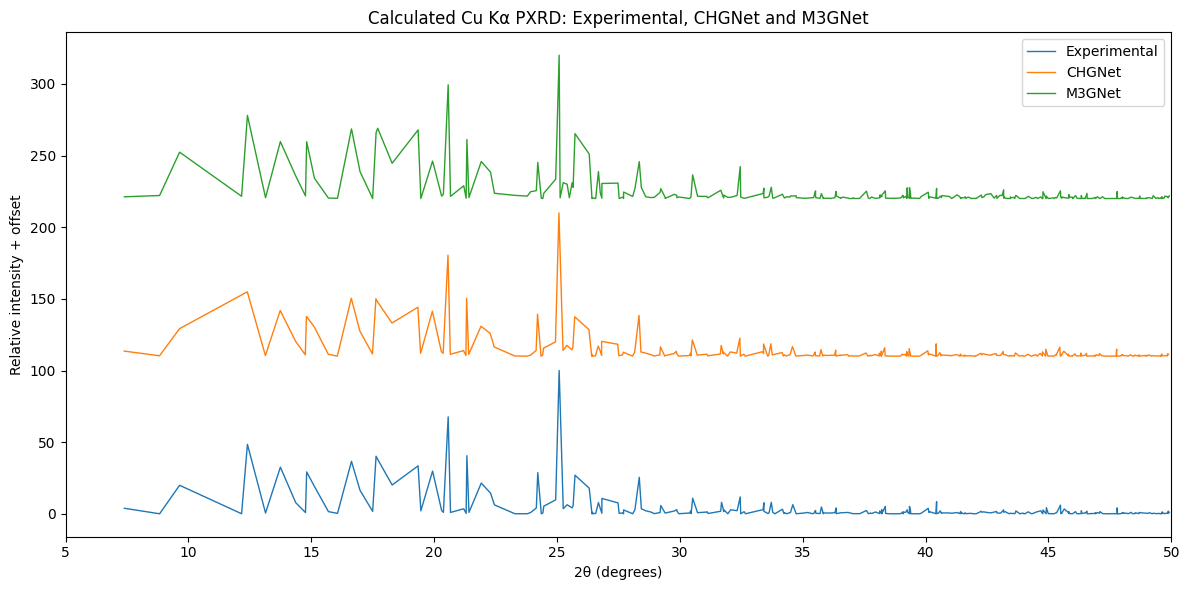


PXRD AGREEMENT WITH EXPERIMENTAL-STRUCTURE CALCULATION
------------------------------------------------------------------------------------------
Structure  Pearson_r  Normalized_MAE  Normalized_RMSE
   CHGNet   0.953320        0.942615         2.930275
   M3GNet   0.976763        1.366125         2.827229

STEP 12N COMPLETE


In [68]:
print("=" * 90)
print("STEP 12N — THREE-STRUCTURE PXRD COMPARISON")
print("=" * 90)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pymatgen.analysis.diffraction.xrd import XRDCalculator

# ---------------------------------------------------------
# Calculate Cu K-alpha PXRD
# ---------------------------------------------------------

calculator = XRDCalculator(
    wavelength="CuKa"
)

patterns = {}

for name, structure in {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}.items():

    pattern = calculator.get_pattern(
        structure,
        two_theta_range=(5, 50)
    )

    patterns[name] = pattern

# ---------------------------------------------------------
# Convert patterns to DataFrames
# ---------------------------------------------------------

pxrd_tables = {}

for name, pattern in patterns.items():

    df = pd.DataFrame({
        "2theta_deg": pattern.x,
        "Intensity": pattern.y
    })

    # Normalize to 100
    df["Relative_intensity"] = (
        df["Intensity"] /
        df["Intensity"].max() *
        100
    )

    pxrd_tables[name] = df

    print()
    print(name)
    print("-" * 90)
    print("Number of peaks:", len(df))
    print(
        "Strongest peak:",
        f"{df.loc[df['Intensity'].idxmax(), '2theta_deg']:.4f}°"
    )

# ---------------------------------------------------------
# Plot all three PXRD patterns
# ---------------------------------------------------------

plt.figure(figsize=(12, 6))

offsets = {
    "Experimental": 0,
    "CHGNet": 1,
    "M3GNet": 2
}

for name, df in pxrd_tables.items():

    y = (
        df["Relative_intensity"].values
        + offsets[name] * 110
    )

    plt.plot(
        df["2theta_deg"],
        y,
        linewidth=1.0,
        label=name
    )

plt.xlabel(r"2θ (degrees)")
plt.ylabel("Relative intensity + offset")
plt.title("Calculated Cu Kα PXRD: Experimental, CHGNet and M3GNet")
plt.xlim(5, 50)
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Quantitative comparison
# ---------------------------------------------------------

def interpolate_pattern(reference_df, target_df):

    x_ref = reference_df["2theta_deg"].values
    y_ref = reference_df["Relative_intensity"].values

    x_target = target_df["2theta_deg"].values
    y_target = target_df["Relative_intensity"].values

    y_interp = np.interp(
        x_ref,
        x_target,
        y_target,
        left=0,
        right=0
    )

    return x_ref, y_ref, y_interp


reference = pxrd_tables["Experimental"]

comparison_rows = []

for name in ["CHGNet", "M3GNet"]:

    x, y_exp, y_calc = interpolate_pattern(
        reference,
        pxrd_tables[name]
    )

    pearson = np.corrcoef(
        y_exp,
        y_calc
    )[0, 1]

    mae = np.mean(
        np.abs(
            y_exp - y_calc
        )
    )

    rmse = np.sqrt(
        np.mean(
            (y_exp - y_calc) ** 2
        )
    )

    comparison_rows.append({
        "Structure": name,
        "Pearson_r": pearson,
        "Normalized_MAE": mae,
        "Normalized_RMSE": rmse
    })

pxrd_comparison = pd.DataFrame(
    comparison_rows
)

print()
print("=" * 90)
print("PXRD AGREEMENT WITH EXPERIMENTAL-STRUCTURE CALCULATION")
print("-" * 90)

print(
    pxrd_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print()
print("=" * 90)
print("STEP 12N COMPLETE")
print("=" * 90)

In [69]:
# ============================================================
# CELL 1 — LOAD EXISTING CHGNet MD TRAJECTORY
# ============================================================

from ase.io import read
import os
import numpy as np

trajectory_file = "/content/cocrystal_2ps.traj"

# Check that the trajectory exists
if not os.path.exists(trajectory_file):
    raise FileNotFoundError(
        f"Trajectory not found: {trajectory_file}\n"
        "Make sure cocrystal_2ps.traj is present in /content."
    )

# Load all frames
md_frames = read(trajectory_file, index=":")

print("=" * 65)
print("CHGNet MD TRAJECTORY CHECK")
print("=" * 65)

print(f"Trajectory file : {trajectory_file}")
print(f"Number of frames: {len(md_frames)}")
print(f"Atoms per frame : {len(md_frames[0])}")
print(f"Initial time    : 0.000 ps")
print(f"Final time      : {(len(md_frames)-1) * 0.001:.3f} ps")
print(f"Cell volume     : {md_frames[0].get_volume():.3f} Å³")

print("\nFirst frame:")
print(md_frames[0])

print("\nLast frame:")
print(md_frames[-1])

print("\n" + "=" * 65)
print("TRAJECTORY LOADED SUCCESSFULLY")
print("=" * 65)

CHGNet MD TRAJECTORY CHECK
Trajectory file : /content/cocrystal_2ps.traj
Number of frames: 201
Atoms per frame : 384
Initial time    : 0.000 ps
Final time      : 0.200 ps
Cell volume     : 3850.798 Å³

First frame:
Atoms(symbols='C176H152N24O32', pbc=True, cell=[[23.939480297991537, 1.4877288315714113e-08, -13.411176173102328], [4.434197228401682e-09, 7.642976966332315, -5.648313204358053e-10], [0.000592466233517249, -1.5555780282030153e-09, 21.04585553645062]], momenta=..., calculator=SinglePointCalculator(...))

Last frame:
Atoms(symbols='C176H152N24O32', pbc=True, cell=[[23.939480297991537, 1.4877288315714113e-08, -13.411176173102328], [4.434197228401682e-09, 7.642976966332315, -5.648313204358053e-10], [0.000592466233517249, -1.5555780282030153e-09, 21.04585553645062]], momenta=..., calculator=SinglePointCalculator(...))

TRAJECTORY LOADED SUCCESSFULLY


In [70]:
# ============================================================
# CELL 2 — MD TIME AXIS AND BASIC TRAJECTORY PROPERTIES
# ============================================================

import numpy as np

# Your original MD settings
timestep_fs = 1.0

# 201 saved frames from 0 to 2000 fs
n_frames = len(md_frames)

# The trajectory contains 2000 MD steps distributed across 201 saved frames
total_time_fs = 2000.0

# Generate correct time axis
time_ps = np.linspace(
    0.0,
    total_time_fs / 1000.0,
    n_frames
)

# Calculate cell volumes for every frame
volumes = np.array([
    atoms.get_volume()
    for atoms in md_frames
])

# Calculate center-of-mass positions
com_positions = np.array([
    atoms.get_center_of_mass()
    for atoms in md_frames
])

print("=" * 65)
print("MD TRAJECTORY TIME AND BASIC PROPERTIES")
print("=" * 65)

print(f"Number of frames       : {n_frames}")
print(f"Atoms per frame        : {len(md_frames[0])}")
print(f"MD timestep            : {timestep_fs:.1f} fs")
print(f"Total simulation time  : {time_ps[-1]:.3f} ps")
print(f"Time interval/frame    : {time_ps[1]-time_ps[0]:.4f} ps")

print("\nCell volume:")
print(f"Initial volume         : {volumes[0]:.6f} Å³")
print(f"Final volume           : {volumes[-1]:.6f} Å³")
print(f"Minimum volume         : {volumes.min():.6f} Å³")
print(f"Maximum volume         : {volumes.max():.6f} Å³")
print(f"Volume range           : {volumes.max()-volumes.min():.6f} Å³")

print("\nTime axis:")
print(f"First 5 times          : {time_ps[:5]}")
print(f"Last 5 times           : {time_ps[-5:]}")

print("\nVariables created:")
print("  md_frames")
print("  time_ps")
print("  volumes")
print("  com_positions")

print("\n" + "=" * 65)
print("CELL 2 COMPLETE")
print("=" * 65)

MD TRAJECTORY TIME AND BASIC PROPERTIES
Number of frames       : 201
Atoms per frame        : 384
MD timestep            : 1.0 fs
Total simulation time  : 2.000 ps
Time interval/frame    : 0.0100 ps

Cell volume:
Initial volume         : 3850.797692 Å³
Final volume           : 3850.797692 Å³
Minimum volume         : 3850.797692 Å³
Maximum volume         : 3850.797692 Å³
Volume range           : 0.000000 Å³

Time axis:
First 5 times          : [0.   0.01 0.02 0.03 0.04]
Last 5 times           : [1.96 1.97 1.98 1.99 2.  ]

Variables created:
  md_frames
  time_ps
  volumes
  com_positions

CELL 2 COMPLETE


In [71]:
# ============================================================
# CELL 3 — MD ENERGY AND TEMPERATURE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import os

log_file = "/content/cocrystal_2ps.log"

if not os.path.exists(log_file):
    raise FileNotFoundError(
        f"MD log file not found: {log_file}\n"
        "Make sure cocrystal_2ps.log is present in /content."
    )

# Read the CHGNet MD log
md_log = pd.read_csv(log_file, delim_whitespace=True)

# Display column names
print("=" * 65)
print("MD LOG FILE")
print("=" * 65)

print("Columns found:")
print(list(md_log.columns))

print("\nNumber of log records:", len(md_log))

print("\nFirst 5 records:")
print(md_log.head())

print("\nLast 5 records:")
print(md_log.tail())

# ------------------------------------------------------------
# Extract columns
# ------------------------------------------------------------

time_log = md_log["Time[ps]"].to_numpy()
etot = md_log["Etot[eV]"].to_numpy()
epot = md_log["Epot[eV]"].to_numpy()
ekin = md_log["Ekin[eV]"].to_numpy()
temperature = md_log["T[K]"].to_numpy()

# ------------------------------------------------------------
# Basic statistics
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ENERGY AND TEMPERATURE STATISTICS")
print("=" * 65)

print("\nPotential energy:")
print(f"Initial : {epot[0]:.6f} eV")
print(f"Final   : {epot[-1]:.6f} eV")
print(f"Minimum : {epot.min():.6f} eV")
print(f"Maximum : {epot.max():.6f} eV")
print(f"Range   : {epot.max()-epot.min():.6f} eV")

print("\nKinetic energy:")
print(f"Initial : {ekin[0]:.6f} eV")
print(f"Final   : {ekin[-1]:.6f} eV")
print(f"Minimum : {ekin.min():.6f} eV")
print(f"Maximum : {ekin.max():.6f} eV")

print("\nTotal energy:")
print(f"Initial : {etot[0]:.6f} eV")
print(f"Final   : {etot[-1]:.6f} eV")
print(f"Minimum : {etot.min():.6f} eV")
print(f"Maximum : {etot.max():.6f} eV")
print(f"Range   : {etot.max()-etot.min():.6f} eV")

print("\nTemperature:")
print(f"Initial : {temperature[0]:.2f} K")
print(f"Final   : {temperature[-1]:.2f} K")
print(f"Minimum : {temperature.min():.2f} K")
print(f"Maximum : {temperature.max():.2f} K")
print(f"Average : {temperature.mean():.2f} K")

# ------------------------------------------------------------
# Store variables for later cells
# ------------------------------------------------------------

md_results = pd.DataFrame({
    "Time_ps": time_log,
    "Etot_eV": etot,
    "Epot_eV": epot,
    "Ekin_eV": ekin,
    "Temperature_K": temperature
})

print("\n" + "=" * 65)
print("Variables created:")
print("  md_log")
print("  time_log")
print("  etot")
print("  epot")
print("  ekin")
print("  temperature")
print("  md_results")
print("=" * 65)

print("\nCELL 3 COMPLETE")

MD LOG FILE
Columns found:
['Time[ps]', 'Etot[eV]', 'Epot[eV]', 'Ekin[eV]', 'T[K]']

Number of log records: 201

First 5 records:
   Time[ps]  Etot[eV]  Epot[eV]  Ekin[eV]  T[K]
0      0.00 -2597.460 -2597.460     0.000   0.0
1      0.01 -2597.429 -2597.485     0.056   1.1
2      0.02 -2597.108 -2597.444     0.336   6.8
3      0.03 -2595.935 -2597.017     1.082  21.8
4      0.04 -2594.592 -2596.657     2.065  41.6

Last 5 records:
     Time[ps]  Etot[eV]  Epot[eV]  Ekin[eV]   T[K]
196      1.96 -2568.003 -2582.688    14.684  295.8
197      1.97 -2568.038 -2583.823    15.786  318.0
198      1.98 -2568.081 -2583.533    15.452  311.3
199      1.99 -2568.086 -2582.584    14.499  292.1
200      2.00 -2568.123 -2583.616    15.493  312.1

ENERGY AND TEMPERATURE STATISTICS

Potential energy:
Initial : -2597.460000 eV
Final   : -2583.616000 eV
Minimum : -2597.485000 eV
Maximum : -2574.302000 eV
Range   : 23.183000 eV

Kinetic energy:
Initial : 0.000000 eV
Final   : 15.493000 eV
Minimum : 0.0000

/tmp/ipykernel_420/725538967.py:18: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  md_log = pd.read_csv(log_file, delim_whitespace=True)


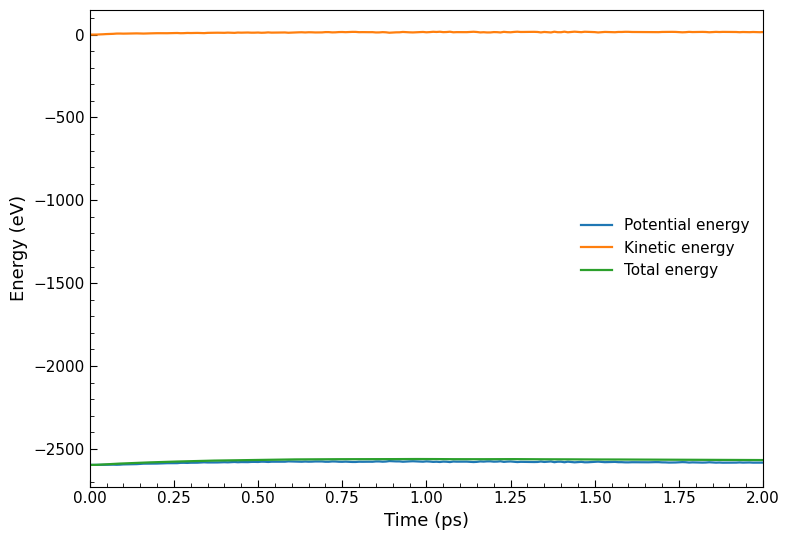

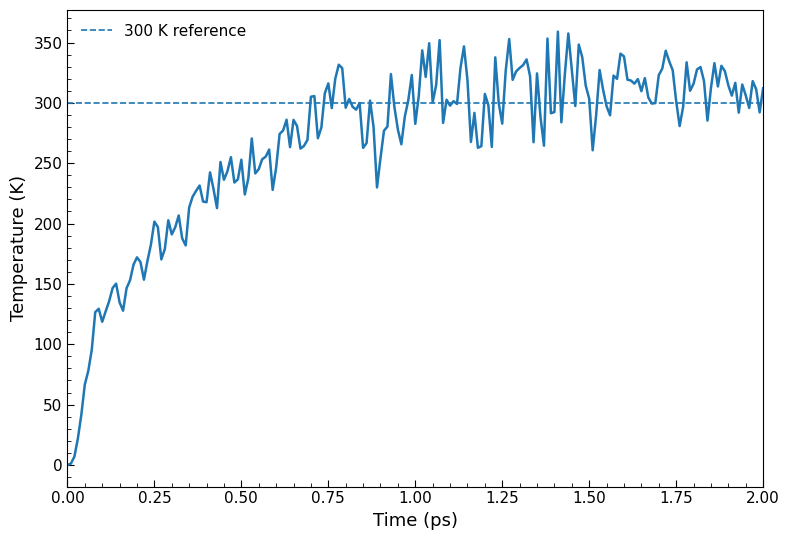

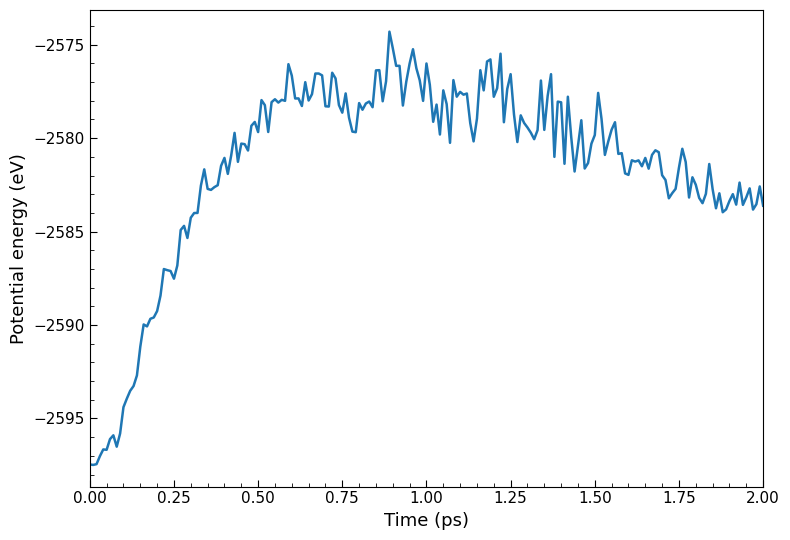

PUBLICATION FIGURES GENERATED
/content/MD_publication_figures/Figure_MD_Energy.pdf
/content/MD_publication_figures/Figure_MD_Energy.png
/content/MD_publication_figures/Figure_MD_Potential_Energy.pdf
/content/MD_publication_figures/Figure_MD_Potential_Energy.png
/content/MD_publication_figures/Figure_MD_Temperature.pdf
/content/MD_publication_figures/Figure_MD_Temperature.png

All figures saved at 600 dpi where applicable.
CELL 4 COMPLETE


In [72]:
# ============================================================
# CELL 4 — PUBLICATION-QUALITY MD ENERGY & TEMPERATURE PLOTS
# ============================================================

import matplotlib.pyplot as plt
import os

# Output directory
output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# FIGURE 1 — Potential, kinetic and total energy
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    time_log,
    epot,
    linewidth=1.6,
    label="Potential energy"
)

ax.plot(
    time_log,
    ekin,
    linewidth=1.6,
    label="Kinetic energy"
)

ax.plot(
    time_log,
    etot,
    linewidth=1.6,
    label="Total energy"
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("Energy (eV)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=11
)

fig.tight_layout()

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Energy.png"),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Energy.pdf"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# FIGURE 2 — Temperature versus time
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    time_log,
    temperature,
    linewidth=1.8
)

ax.axhline(
    300,
    linestyle="--",
    linewidth=1.2,
    label="300 K reference"
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("Temperature (K)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=11
)

fig.tight_layout()

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Temperature.png"),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Temperature.pdf"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# FIGURE 3 — Potential energy only
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    time_log,
    epot,
    linewidth=1.8
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("Potential energy (eV)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

fig.tight_layout()

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Potential_Energy.png"),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Potential_Energy.pdf"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# List generated files
# ------------------------------------------------------------

print("=" * 65)
print("PUBLICATION FIGURES GENERATED")
print("=" * 65)

for filename in sorted(os.listdir(output_dir)):
    print(os.path.join(output_dir, filename))

print("\nAll figures saved at 600 dpi where applicable.")
print("CELL 4 COMPLETE")

MD STRUCTURAL DISPLACEMENT ANALYSIS

All-atom RMSD:
Initial : 0.0000 Å
Final   : 1.0359 Å
Maximum : 1.5571 Å
Average : 1.1650 Å

Heavy-atom RMSD:
Initial : 0.0000 Å
Final   : 0.8627 Å
Maximum : 1.2835 Å
Average : 1.0091 Å

Mean atomic displacement:
Initial : 0.0000 Å
Final   : 0.9489 Å
Maximum : 1.4150 Å

Maximum individual atomic displacement:
Initial : 0.0000 Å
Final   : 2.7083 Å
Maximum : 3.6450 Å


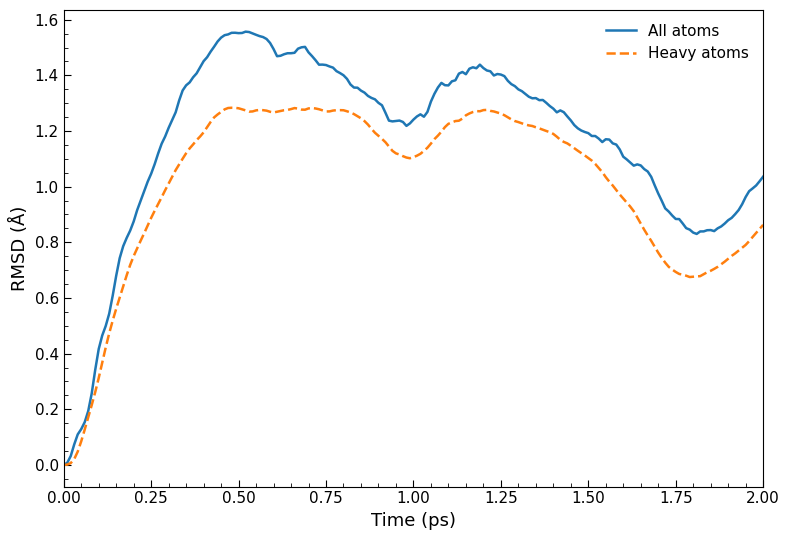


RMSD FIGURE SAVED
/content/MD_publication_figures/Figure_MD_RMSD.png
/content/MD_publication_figures/Figure_MD_RMSD.pdf
/content/MD_publication_figures/MD_RMSD_Displacement.csv

CELL 5 COMPLETE


In [73]:
# ============================================================
# CELL 5 — MD RMSD AND ATOMIC DISPLACEMENT
# CORRECTED FOR ASE PERIODIC BOUNDARY CONDITIONS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# Reference structure = first MD frame
# ------------------------------------------------------------

reference = md_frames[0]

reference_positions = reference.get_positions().copy()

# Atomic symbols
symbols = np.array(reference.get_chemical_symbols())

# Heavy-atom mask
heavy_mask = symbols != "H"

# Results
rmsd_all = []
rmsd_heavy = []
mean_displacement = []
max_displacement = []

# ------------------------------------------------------------
# Calculate periodic minimum-image displacement
# ------------------------------------------------------------

for atoms in md_frames:

    cell = atoms.get_cell().array
    current_positions = atoms.get_positions()

    # Convert reference and current Cartesian coordinates
    # to fractional coordinates
    frac_reference = np.linalg.solve(
        cell.T,
        reference_positions.T
    ).T

    frac_current = np.linalg.solve(
        cell.T,
        current_positions.T
    ).T

    # Fractional displacement
    frac_difference = frac_current - frac_reference

    # Minimum-image convention
    frac_difference -= np.round(frac_difference)

    # Convert displacement back to Cartesian coordinates
    cart_difference = frac_difference @ cell

    # Magnitude of displacement for every atom
    distances = np.linalg.norm(
        cart_difference,
        axis=1
    )

    # All-atom RMSD
    rmsd_all.append(
        np.sqrt(np.mean(distances**2))
    )

    # Heavy-atom RMSD
    heavy_distances = distances[heavy_mask]

    rmsd_heavy.append(
        np.sqrt(np.mean(heavy_distances**2))
    )

    # Mean displacement
    mean_displacement.append(
        np.mean(distances)
    )

    # Maximum displacement
    max_displacement.append(
        np.max(distances)
    )

# Convert lists to arrays
rmsd_all = np.array(rmsd_all)
rmsd_heavy = np.array(rmsd_heavy)
mean_displacement = np.array(mean_displacement)
max_displacement = np.array(max_displacement)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("=" * 65)
print("MD STRUCTURAL DISPLACEMENT ANALYSIS")
print("=" * 65)

print("\nAll-atom RMSD:")
print(f"Initial : {rmsd_all[0]:.4f} Å")
print(f"Final   : {rmsd_all[-1]:.4f} Å")
print(f"Maximum : {rmsd_all.max():.4f} Å")
print(f"Average : {rmsd_all.mean():.4f} Å")

print("\nHeavy-atom RMSD:")
print(f"Initial : {rmsd_heavy[0]:.4f} Å")
print(f"Final   : {rmsd_heavy[-1]:.4f} Å")
print(f"Maximum : {rmsd_heavy.max():.4f} Å")
print(f"Average : {rmsd_heavy.mean():.4f} Å")

print("\nMean atomic displacement:")
print(f"Initial : {mean_displacement[0]:.4f} Å")
print(f"Final   : {mean_displacement[-1]:.4f} Å")
print(f"Maximum : {mean_displacement.max():.4f} Å")

print("\nMaximum individual atomic displacement:")
print(f"Initial : {max_displacement[0]:.4f} Å")
print(f"Final   : {max_displacement[-1]:.4f} Å")
print(f"Maximum : {max_displacement.max():.4f} Å")

# ------------------------------------------------------------
# Save numerical results
# ------------------------------------------------------------

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

rmsd_results = np.column_stack([
    time_ps,
    rmsd_all,
    rmsd_heavy,
    mean_displacement,
    max_displacement
])

np.savetxt(
    os.path.join(output_dir, "MD_RMSD_Displacement.csv"),
    rmsd_results,
    delimiter=",",
    header=(
        "Time_ps,"
        "RMSD_all_A,"
        "RMSD_heavy_A,"
        "Mean_displacement_A,"
        "Max_displacement_A"
    ),
    comments=""
)

# ------------------------------------------------------------
# Publication-quality RMSD figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    time_ps,
    rmsd_all,
    linewidth=1.8,
    label="All atoms"
)

ax.plot(
    time_ps,
    rmsd_heavy,
    linewidth=1.8,
    linestyle="--",
    label="Heavy atoms"
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("RMSD (Å)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=11
)

fig.tight_layout()

fig.savefig(
    os.path.join(output_dir, "Figure_MD_RMSD.png"),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(output_dir, "Figure_MD_RMSD.pdf"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\n" + "=" * 65)
print("RMSD FIGURE SAVED")
print("=" * 65)

print(os.path.join(output_dir, "Figure_MD_RMSD.png"))
print(os.path.join(output_dir, "Figure_MD_RMSD.pdf"))
print(os.path.join(output_dir, "MD_RMSD_Displacement.csv"))

print("\nCELL 5 COMPLETE")

RDF ANALYSIS
Hydrogen atoms : 152
Carbon atoms   : 176
Nitrogen atoms : 24
Oxygen atoms   : 32
H-O   | pairs sampled:  977664 | counts:  193501
N-O   | pairs sampled:  154368 | counts:   31466
C-C   | pairs sampled: 3095400 | counts:  597803
C-H   | pairs sampled: 5377152 | counts: 1048368


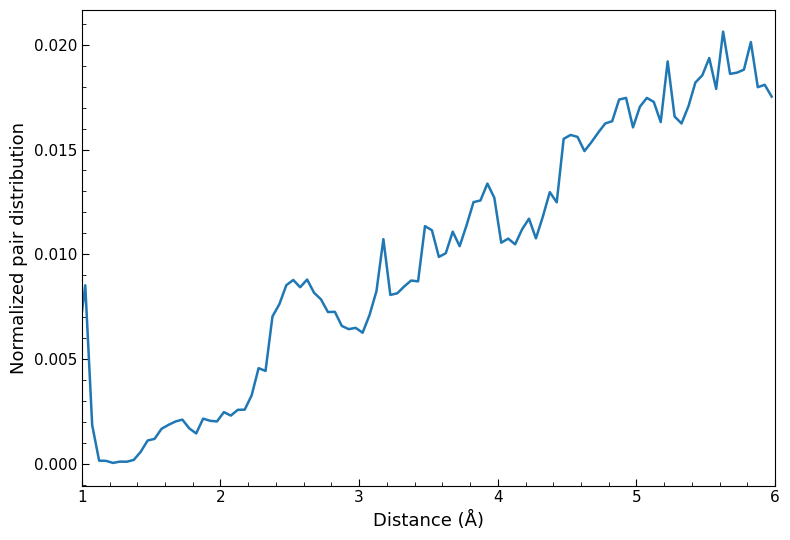

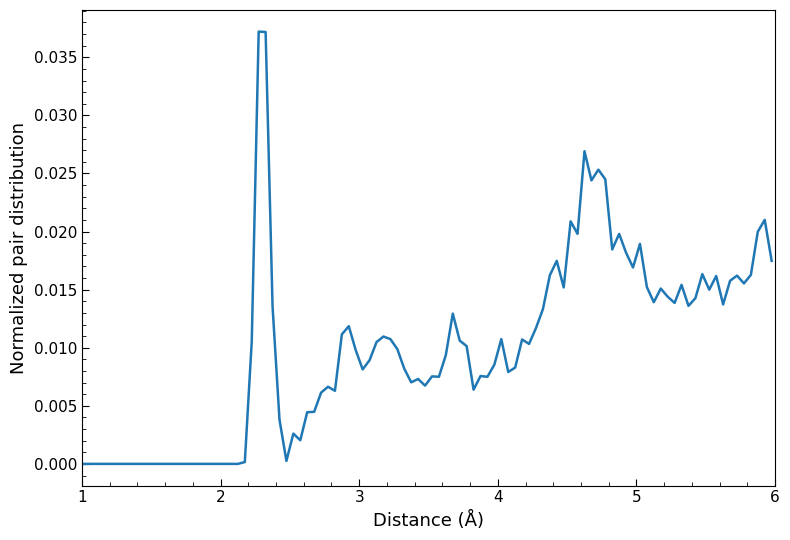

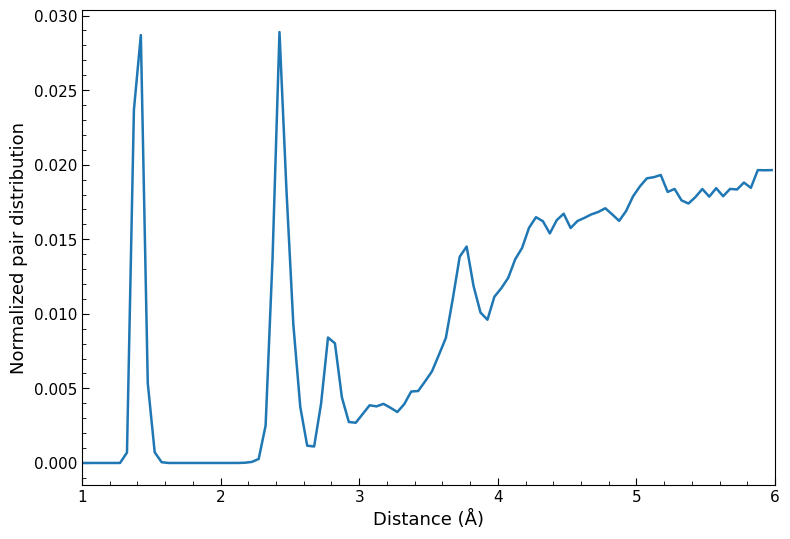

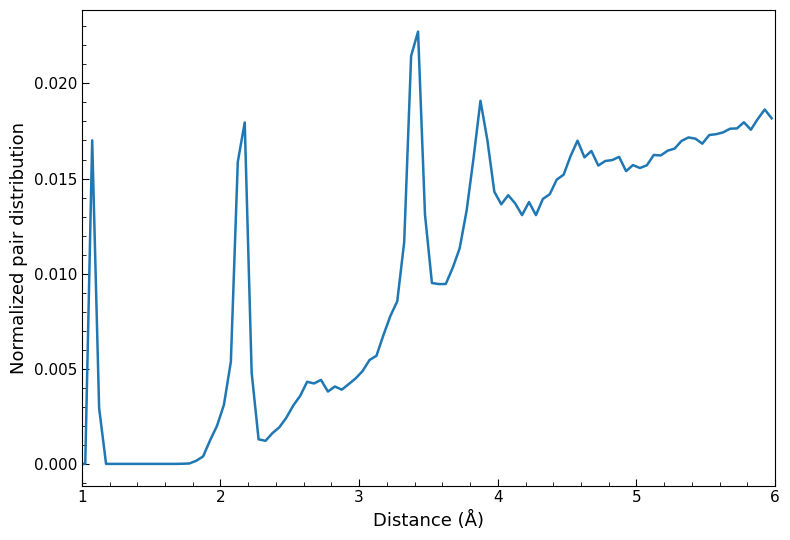


RDF ANALYSIS COMPLETE
Saved: MD_RDF_Data.csv
Four RDF figures generated:
  H-O
  N-O
  C-C
  C-H

CELL 6 COMPLETE


In [74]:
# ============================================================
# CELL 6 — RADIAL DISTRIBUTION FUNCTION (RDF) ANALYSIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# RDF settings
# ------------------------------------------------------------

r_max = 6.0       # maximum distance in Å
dr = 0.05         # bin width in Å

r_edges = np.arange(0.0, r_max + dr, dr)
r_centers = 0.5 * (r_edges[:-1] + r_edges[1:])

# ------------------------------------------------------------
# Atom indices by element
# ------------------------------------------------------------

symbols = np.array(
    md_frames[0].get_chemical_symbols()
)

H_indices = np.where(symbols == "H")[0]
C_indices = np.where(symbols == "C")[0]
N_indices = np.where(symbols == "N")[0]
O_indices = np.where(symbols == "O")[0]

print("=" * 65)
print("RDF ANALYSIS")
print("=" * 65)

print(f"Hydrogen atoms : {len(H_indices)}")
print(f"Carbon atoms   : {len(C_indices)}")
print(f"Nitrogen atoms : {len(N_indices)}")
print(f"Oxygen atoms   : {len(O_indices)}")

# ------------------------------------------------------------
# Function to calculate pair-distance histogram
# with periodic minimum-image convention
# ------------------------------------------------------------

def pair_distance_histogram(frames, indices_a, indices_b,
                            r_edges, same_species=False):

    histogram = np.zeros(len(r_edges) - 1)
    total_pairs = 0

    for atoms in frames:
        positions = atoms.get_positions()
        cell = atoms.get_cell().array

        # Fractional coordinates
        fractional = np.linalg.solve(
            cell.T,
            positions.T
        ).T

        # Pair combinations
        if same_species:
            pairs = [
                (i, j)
                for ii, i in enumerate(indices_a)
                for j in indices_a[ii + 1:]
            ]
        else:
            pairs = [
                (i, j)
                for i in indices_a
                for j in indices_b
            ]

        for i, j in pairs:
            df = fractional[j] - fractional[i]

            # Minimum-image convention
            df -= np.round(df)

            # Cartesian distance
            dr_cart = df @ cell
            distance = np.linalg.norm(dr_cart)

            if distance < r_edges[-1]:
                histogram += np.histogram(
                    [distance],
                    bins=r_edges
                )[0]

            total_pairs += 1

    return histogram, total_pairs


# ------------------------------------------------------------
# Calculate RDF-like normalized distributions
# ------------------------------------------------------------

pair_definitions = {
    "H-O": (H_indices, O_indices, False),
    "N-O": (N_indices, O_indices, False),
    "C-C": (C_indices, C_indices, True),
    "C-H": (C_indices, H_indices, False)
}

rdf_data = {}

for name, (idx_a, idx_b, same_species) in pair_definitions.items():
    hist, total_pairs = pair_distance_histogram(
        md_frames,
        idx_a,
        idx_b,
        r_edges,
        same_species=same_species
    )

    # Normalize to probability distribution
    if hist.sum() > 0:
        rdf = hist / hist.sum()
    else:
        rdf = hist

    rdf_data[name] = rdf

    print(
        f"{name:5s} | "
        f"pairs sampled: {total_pairs:7d} | "
        f"counts: {int(hist.sum()):7d}"
    )


# ------------------------------------------------------------
# Save RDF data
# ------------------------------------------------------------

rdf_table = np.column_stack([
    r_centers,
    rdf_data["H-O"],
    rdf_data["N-O"],
    rdf_data["C-C"],
    rdf_data["C-H"]
])

np.savetxt(
    os.path.join(output_dir, "MD_RDF_Data.csv"),
    rdf_table,
    delimiter=",",
    header="Distance_A,H-O,N-O,C-C,C-H",
    comments=""
)


# ------------------------------------------------------------
# Individual RDF plots
# ------------------------------------------------------------

for name, rdf in rdf_data.items():
    fig, ax = plt.subplots(figsize=(8, 5.5))

    ax.plot(
        r_centers,
        rdf,
        linewidth=1.8
    )

    ax.set_xlabel("Distance (Å)", fontsize=13)
    ax.set_ylabel("Normalized pair distribution", fontsize=13)

    ax.set_xlim(1.0, 6.0)

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=11,
        direction="in",
        length=5
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="in",
        length=3
    )

    ax.minorticks_on()

    fig.tight_layout()

    safe_name = name.replace("-", "_")

    fig.savefig(
        os.path.join(
            output_dir,
            f"Figure_RDF_{safe_name}.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        os.path.join(
            output_dir,
            f"Figure_RDF_{safe_name}.pdf"
        ),
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


print("\n" + "=" * 65)
print("RDF ANALYSIS COMPLETE")
print("=" * 65)

print(
    "Saved: MD_RDF_Data.csv"
)

print("Four RDF figures generated:")
print("  H-O")
print("  N-O")
print("  C-C")
print("  C-H")

print("\nCELL 6 COMPLETE")

H-BOND GEOMETRY DURING 2-PS MD

O364-H12...O380
  H...A distance : 2.757 ± 0.978 Å
  D...A distance : 3.300 ± 0.699 Å
  D-H distance   : 1.017 ± 0.035 Å
  D-H...A angle  : 128.16 ± 45.44°
  H...A minimum  : 1.153 Å
  H...A maximum  : 4.492 Å

O361-H9...O377
  H...A distance : 2.345 ± 0.968 Å
  D...A distance : 3.194 ± 0.759 Å
  D-H distance   : 1.020 ± 0.037 Å
  D-H...A angle  : 151.17 ± 26.88°
  H...A minimum  : 1.153 Å
  H...A maximum  : 4.485 Å

O365-H13...O381
  H...A distance : 2.351 ± 0.971 Å
  D...A distance : 3.200 ± 0.761 Å
  D-H distance   : 1.021 ± 0.040 Å
  D-H...A angle  : 151.16 ± 26.95°
  H...A minimum  : 1.153 Å
  H...A maximum  : 4.489 Å

O360-H8...O376
  H...A distance : 2.791 ± 1.010 Å
  D...A distance : 3.353 ± 0.701 Å
  D-H distance   : 1.021 ± 0.037 Å
  D-H...A angle  : 129.45 ± 43.41°
  H...A minimum  : 1.153 Å
  H...A maximum  : 4.496 Å

H-BOND PERSISTENCE
O364-H12...O380   :  41.79%
O361-H9...O377    :  64.68%
O365-H13...O381   :  64.18%
O360-H8...O376    :  41

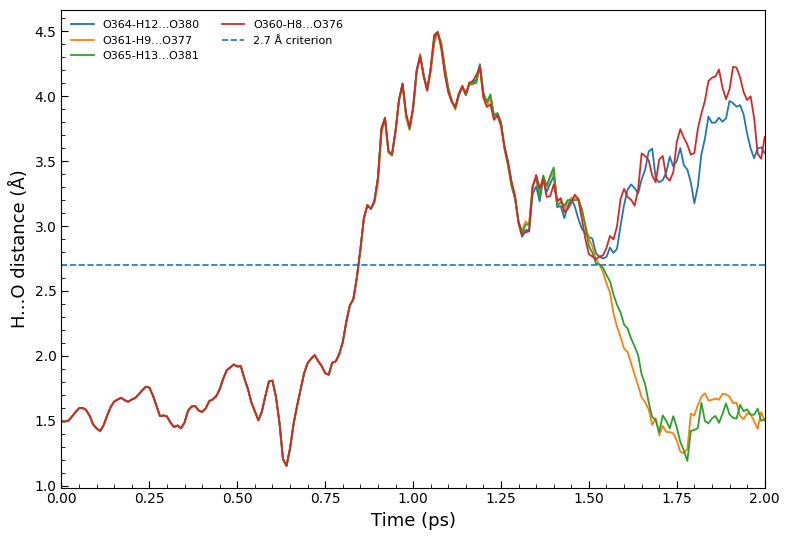

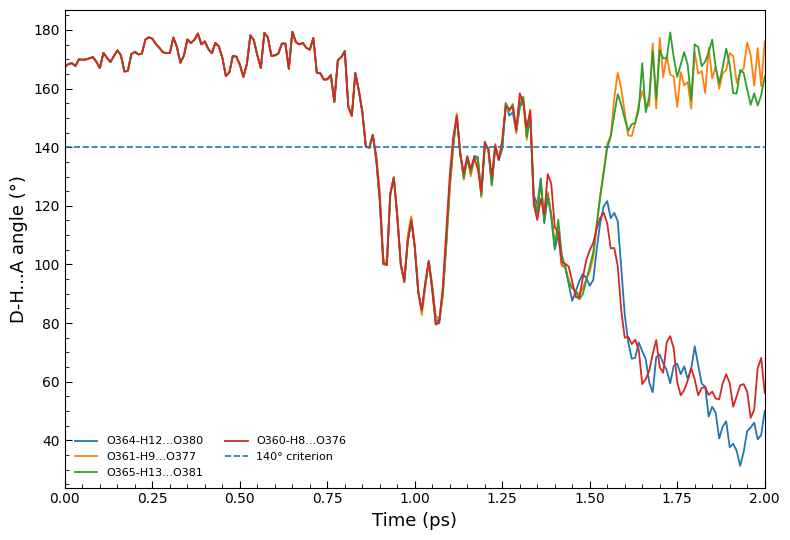


CELL 7 COMPLETE
Files saved:
  MD_Hbond_Geometry.csv
  Figure_Hbond_HO_Distance.png/.pdf
  Figure_Hbond_Angle.png/.pdf


In [75]:
# ============================================================
# CELL 7 — H-BOND GEOMETRY DISTRIBUTIONS DURING MD
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Experimentally identified H-bonds for 384-atom cocrystal
# ------------------------------------------------------------

hbonds = {
    "O364-H12...O380": (364, 12, 380),
    "O361-H9...O377":  (361, 9, 377),
    "O365-H13...O381": (365, 13, 381),
    "O360-H8...O376":  (360, 8, 376)
}

# ------------------------------------------------------------
# Geometry function
# ------------------------------------------------------------

def angle_three_points(a, b, c):
    """
    Calculate angle A-B-C in degrees.
    """
    v1 = a - b
    v2 = c - b

    norm1 = np.linalg.norm(v1)
    norm2 = np.linalg.norm(v2)

    if norm1 == 0 or norm2 == 0:
        return np.nan

    cosine = np.dot(v1, v2) / (norm1 * norm2)
    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))


def mic_vector(atoms, i, j):
    """
    Minimum-image vector from atom i to atom j.
    """
    cell = atoms.get_cell().array
    positions = atoms.get_positions()

    frac = np.linalg.solve(
        cell.T,
        positions.T
    ).T

    df = frac[j] - frac[i]
    df -= np.round(df)

    return df @ cell


# ------------------------------------------------------------
# Calculate geometry for every MD frame
# ------------------------------------------------------------

hb_data = {}

for name, (donor, hydrogen, acceptor) in hbonds.items():

    donor_h_distances = []
    h_acceptor_distances = []
    donor_acceptor_distances = []
    angles = []

    for atoms in md_frames:

        # D-H vector
        dh_vector = mic_vector(atoms, donor, hydrogen)

        # H-A vector
        ha_vector = mic_vector(atoms, hydrogen, acceptor)

        # D-A vector
        da_vector = mic_vector(atoms, donor, acceptor)

        d_h = np.linalg.norm(dh_vector)
        h_a = np.linalg.norm(ha_vector)
        d_a = np.linalg.norm(da_vector)

        # For angle D-H-A
        donor_position = np.zeros(3)
        hydrogen_position = dh_vector
        acceptor_position = dh_vector + ha_vector

        angle = angle_three_points(
            donor_position,
            hydrogen_position,
            acceptor_position
        )

        donor_h_distances.append(d_h)
        h_acceptor_distances.append(h_a)
        donor_acceptor_distances.append(d_a)
        angles.append(angle)

    hb_data[name] = {
        "D-H": np.array(donor_h_distances),
        "H-A": np.array(h_acceptor_distances),
        "D-A": np.array(donor_acceptor_distances),
        "Angle": np.array(angles)
    }


# ------------------------------------------------------------
# Print statistics
# ------------------------------------------------------------

print("=" * 75)
print("H-BOND GEOMETRY DURING 2-PS MD")
print("=" * 75)

for name, data in hb_data.items():

    print("\n" + name)

    print(
        f"  H...A distance : "
        f"{np.mean(data['H-A']):.3f} ± "
        f"{np.std(data['H-A']):.3f} Å"
    )

    print(
        f"  D...A distance : "
        f"{np.mean(data['D-A']):.3f} ± "
        f"{np.std(data['D-A']):.3f} Å"
    )

    print(
        f"  D-H distance   : "
        f"{np.mean(data['D-H']):.3f} ± "
        f"{np.std(data['D-H']):.3f} Å"
    )

    print(
        f"  D-H...A angle  : "
        f"{np.mean(data['Angle']):.2f} ± "
        f"{np.std(data['Angle']):.2f}°"
    )

    print(
        f"  H...A minimum  : "
        f"{np.min(data['H-A']):.3f} Å"
    )

    print(
        f"  H...A maximum  : "
        f"{np.max(data['H-A']):.3f} Å"
    )


# ------------------------------------------------------------
# H-bond persistence using the same criteria used previously
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("H-BOND PERSISTENCE")
print("=" * 75)

persistence_results = []

for name, data in hb_data.items():

    valid = (
        (data["H-A"] <= 2.7) &
        (data["D-A"] <= 3.5) &
        (data["Angle"] >= 140.0)
    )

    persistence = 100.0 * np.mean(valid)

    persistence_results.append([
        name,
        persistence
    ])

    print(
        f"{name:18s}: "
        f"{persistence:6.2f}%"
    )


# ------------------------------------------------------------
# Save complete numerical dataset
# ------------------------------------------------------------

hb_dataframe = pd.DataFrame({
    "Time_ps": time_ps
})

for name, data in hb_data.items():

    clean_name = name.replace("-", "_").replace(".", "_")

    hb_dataframe[f"{clean_name}_H_A_A"] = data["H-A"]
    hb_dataframe[f"{clean_name}_D_A_A"] = data["D-A"]
    hb_dataframe[f"{clean_name}_Angle_deg"] = data["Angle"]

hb_dataframe.to_csv(
    os.path.join(
        output_dir,
        "MD_Hbond_Geometry.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# Plot 1 — H...O distance distributions
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

for name, data in hb_data.items():

    ax.plot(
        time_ps,
        data["H-A"],
        linewidth=1.3,
        label=name
    )

ax.axhline(
    2.7,
    linestyle="--",
    linewidth=1.2,
    label="2.7 Å criterion"
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("H...O distance (Å)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=8,
    ncol=2
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_HO_Distance.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_HO_Distance.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Plot 2 — H-bond angle
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

for name, data in hb_data.items():

    ax.plot(
        time_ps,
        data["Angle"],
        linewidth=1.3,
        label=name
    )

ax.axhline(
    140,
    linestyle="--",
    linewidth=1.2,
    label="140° criterion"
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("D-H...A angle (°)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=8,
    ncol=2
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_Angle.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_Angle.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


print("\n" + "=" * 75)
print("CELL 7 COMPLETE")
print("=" * 75)

print("Files saved:")
print("  MD_Hbond_Geometry.csv")
print("  Figure_Hbond_HO_Distance.png/.pdf")
print("  Figure_Hbond_Angle.png/.pdf")

H-BOND OCCUPANCY ANALYSIS

O364-H12...O380
  H...O ≤ 2.7 Å       : 42.29%
  O...O ≤ 3.5 Å       : 71.14%
  O-H...O ≥ 140°      : 49.75%
  ALL criteria        : 41.79%

O361-H9...O377
  H...O ≤ 2.7 Å       : 65.67%
  O...O ≤ 3.5 Å       : 70.65%
  O-H...O ≥ 140°      : 73.13%
  ALL criteria        : 64.68%

O365-H13...O381
  H...O ≤ 2.7 Å       : 65.67%
  O...O ≤ 3.5 Å       : 70.65%
  O-H...O ≥ 140°      : 71.64%
  ALL criteria        : 64.18%

O360-H8...O376
  H...O ≤ 2.7 Å       : 42.29%
  O...O ≤ 3.5 Å       : 64.18%
  O-H...O ≥ 140°      : 50.25%
  ALL criteria        : 41.79%

OCCUPANCY TABLE
         H_bond  H_O_occupancy_percent  O_O_occupancy_percent  Angle_occupancy_percent  Overall_persistence_percent
O364-H12...O380                  42.29                  71.14                    49.75                        41.79
 O361-H9...O377                  65.67                  70.65                    73.13                        64.68
O365-H13...O381                  65.67         

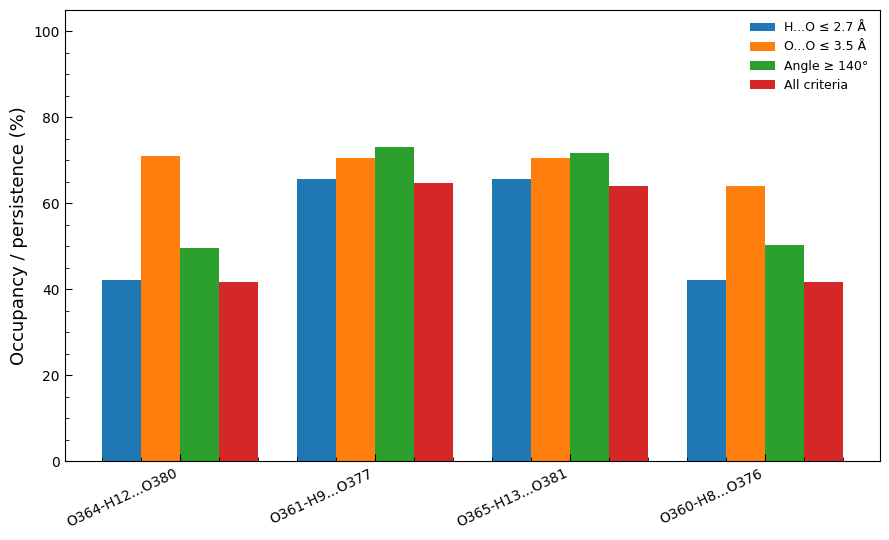


CELL 8 COMPLETE
Saved:
  Hbond_Occupancy_Analysis.csv
  Figure_Hbond_Occupancy.png
  Figure_Hbond_Occupancy.pdf


In [76]:
# ============================================================
# CELL 8 — H-BOND OCCUPANCY AND DISTRIBUTION ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# H-bond criteria
# ------------------------------------------------------------

H_A_LIMIT = 2.7
D_A_LIMIT = 3.5
ANGLE_LIMIT = 140.0

occupancy_rows = []

print("=" * 75)
print("H-BOND OCCUPANCY ANALYSIS")
print("=" * 75)

for name, data in hb_data.items():

    h_a = data["H-A"]
    d_a = data["D-A"]
    angle = data["Angle"]

    h_a_ok = h_a <= H_A_LIMIT
    d_a_ok = d_a <= D_A_LIMIT
    angle_ok = angle >= ANGLE_LIMIT

    all_ok = h_a_ok & d_a_ok & angle_ok

    h_a_occ = 100 * np.mean(h_a_ok)
    d_a_occ = 100 * np.mean(d_a_ok)
    angle_occ = 100 * np.mean(angle_ok)
    overall_occ = 100 * np.mean(all_ok)

    occupancy_rows.append([
        name,
        h_a_occ,
        d_a_occ,
        angle_occ,
        overall_occ
    ])

    print(f"\n{name}")
    print(f"  H...O ≤ 2.7 Å       : {h_a_occ:.2f}%")
    print(f"  O...O ≤ 3.5 Å       : {d_a_occ:.2f}%")
    print(f"  O-H...O ≥ 140°      : {angle_occ:.2f}%")
    print(f"  ALL criteria        : {overall_occ:.2f}%")


# ------------------------------------------------------------
# Create occupancy table
# ------------------------------------------------------------

occupancy_df = pd.DataFrame(
    occupancy_rows,
    columns=[
        "H_bond",
        "H_O_occupancy_percent",
        "O_O_occupancy_percent",
        "Angle_occupancy_percent",
        "Overall_persistence_percent"
    ]
)

occupancy_df.to_csv(
    os.path.join(
        output_dir,
        "Hbond_Occupancy_Analysis.csv"
    ),
    index=False
)

print("\n" + "=" * 75)
print("OCCUPANCY TABLE")
print("=" * 75)

print(
    occupancy_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ------------------------------------------------------------
# Plot occupancy
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5.5))

x = np.arange(len(occupancy_df))
width = 0.20

ax.bar(
    x - 1.5 * width,
    occupancy_df["H_O_occupancy_percent"],
    width,
    label="H...O ≤ 2.7 Å"
)

ax.bar(
    x - 0.5 * width,
    occupancy_df["O_O_occupancy_percent"],
    width,
    label="O...O ≤ 3.5 Å"
)

ax.bar(
    x + 0.5 * width,
    occupancy_df["Angle_occupancy_percent"],
    width,
    label="Angle ≥ 140°"
)

ax.bar(
    x + 1.5 * width,
    occupancy_df["Overall_persistence_percent"],
    width,
    label="All criteria"
)

ax.set_xticks(x)
ax.set_xticklabels(
    occupancy_df["H_bond"],
    rotation=25,
    ha="right"
)

ax.set_ylabel("Occupancy / persistence (%)", fontsize=13)
ax.set_ylim(0, 105)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=9
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_Occupancy.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_Occupancy.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


print("\n" + "=" * 75)
print("CELL 8 COMPLETE")
print("=" * 75)

print("Saved:")
print("  Hbond_Occupancy_Analysis.csv")
print("  Figure_Hbond_Occupancy.png")
print("  Figure_Hbond_Occupancy.pdf")

In [77]:
# ============================================================
# CELL 9 — ATOM-BY-ATOM MD DISPLACEMENT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Reference structure
# ------------------------------------------------------------

reference = md_frames[0]
reference_positions = reference.get_positions()

symbols = np.array(
    reference.get_chemical_symbols()
)

n_atoms = len(reference)

# ------------------------------------------------------------
# Store displacement for every atom and every frame
# ------------------------------------------------------------

all_displacements = np.zeros(
    (len(md_frames), n_atoms)
)

# ------------------------------------------------------------
# Calculate periodic minimum-image displacements
# ------------------------------------------------------------

for frame_index, atoms in enumerate(md_frames):

    cell = atoms.get_cell().array
    current_positions = atoms.get_positions()

    # Fractional coordinates
    frac_reference = np.linalg.solve(
        cell.T,
        reference_positions.T
    ).T

    frac_current = np.linalg.solve(
        cell.T,
        current_positions.T
    ).T

    # Fractional displacement
    frac_difference = (
        frac_current - frac_reference
    )

    # Minimum-image convention
    frac_difference -= np.round(
        frac_difference
    )

    # Cartesian displacement
    cart_difference = (
        frac_difference @ cell
    )

    # Magnitude
    distances = np.linalg.norm(
        cart_difference,
        axis=1
    )

    all_displacements[frame_index, :] = distances


# ------------------------------------------------------------
# Per-atom statistics
# ------------------------------------------------------------

mean_disp = np.mean(
    all_displacements,
    axis=0
)

max_disp = np.max(
    all_displacements,
    axis=0
)

final_disp = all_displacements[-1, :]

rms_disp = np.sqrt(
    np.mean(
        all_displacements**2,
        axis=0
    )
)


# ------------------------------------------------------------
# Create atom table
# ------------------------------------------------------------

atom_table = pd.DataFrame({
    "Atom_index": np.arange(n_atoms),
    "Element": symbols,
    "Mean_displacement_A": mean_disp,
    "RMS_displacement_A": rms_disp,
    "Maximum_displacement_A": max_disp,
    "Final_displacement_A": final_disp
})


# ------------------------------------------------------------
# Sort by maximum displacement
# ------------------------------------------------------------

atom_table_sorted = atom_table.sort_values(
    "Maximum_displacement_A",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# Print top 15 atoms
# ------------------------------------------------------------

print("=" * 75)
print("TOP 15 MOST MOBILE ATOMS")
print("=" * 75)

print(
    atom_table_sorted.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# Element-wise statistics
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ELEMENT-WISE DISPLACEMENT STATISTICS")
print("=" * 75)

element_stats = []

for element in sorted(
    np.unique(symbols)
):
    mask = symbols == element
    values = max_disp[mask]

    element_stats.append([
        element,
        np.sum(mask),
        np.mean(values),
        np.sqrt(np.mean(values**2)),
        np.max(values)
    ])

element_stats_df = pd.DataFrame(
    element_stats,
    columns=[
        "Element",
        "Number_of_atoms",
        "Mean_max_displacement_A",
        "RMS_max_displacement_A",
        "Largest_displacement_A"
    ]
)

print(
    element_stats_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# Displacement categories
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DISPLACEMENT CATEGORIES")
print("=" * 75)

categories = {
    "< 0.10 Å": np.sum(max_disp < 0.10),
    "0.10–0.20 Å": np.sum(
        (max_disp >= 0.10) &
        (max_disp < 0.20)
    ),
    "0.20–0.30 Å": np.sum(
        (max_disp >= 0.20) &
        (max_disp < 0.30)
    ),
    "≥ 0.30 Å": np.sum(
        max_disp >= 0.30
    )
}

for category, count in categories.items():
    percentage = 100 * count / n_atoms
    print(
        f"{category:15s}: "
        f"{count:3d} atoms "
        f"({percentage:5.2f}%)"
    )


# ------------------------------------------------------------
# Save files
# ------------------------------------------------------------

atom_table.to_csv(
    os.path.join(
        output_dir,
        "MD_Atom_Displacements.csv"
    ),
    index=False
)

atom_table_sorted.to_csv(
    os.path.join(
        output_dir,
        "MD_Atom_Displacements_Sorted.csv"
    ),
    index=False
)

element_stats_df.to_csv(
    os.path.join(
        output_dir,
        "MD_Element_Displacement_Statistics.csv"
    ),
    index=False
)


print("\n" + "=" * 75)
print("CELL 9 COMPLETE")
print("=" * 75)

print("Saved:")
print("  MD_Atom_Displacements.csv")
print("  MD_Atom_Displacements_Sorted.csv")
print("  MD_Element_Displacement_Statistics.csv")

TOP 15 MOST MOBILE ATOMS
 Atom_index Element  Mean_displacement_A  RMS_displacement_A  Maximum_displacement_A  Final_displacement_A
         33       H               1.4289              1.6637                  3.6450                1.1626
         32       H               1.5079              1.7018                  3.6450                1.6645
         39       H               1.4233              1.6627                  3.6449                1.3443
         37       H               1.4388              1.6646                  3.6448                1.0958
         35       H               1.4345              1.6644                  3.6448                1.0575
         34       H               1.4909              1.6899                  3.6448                1.5213
         36       H               1.4852              1.6872                  3.6448                1.6893
         38       H               1.4825              1.6865                  3.6447                1.5223
         56 

MAXIMUM ATOMIC DISPLACEMENT DISTRIBUTION

All atoms:
Mean   : 2.0057 Å
Median : 1.8725 Å
Maximum: 3.6450 Å

Heavy atoms:
Mean   : 1.6958 Å
Median : 1.5898 Å
Maximum: 3.2102 Å

Hydrogen atoms:
Mean   : 2.4788 Å
Median : 2.2962 Å
Maximum: 3.6450 Å


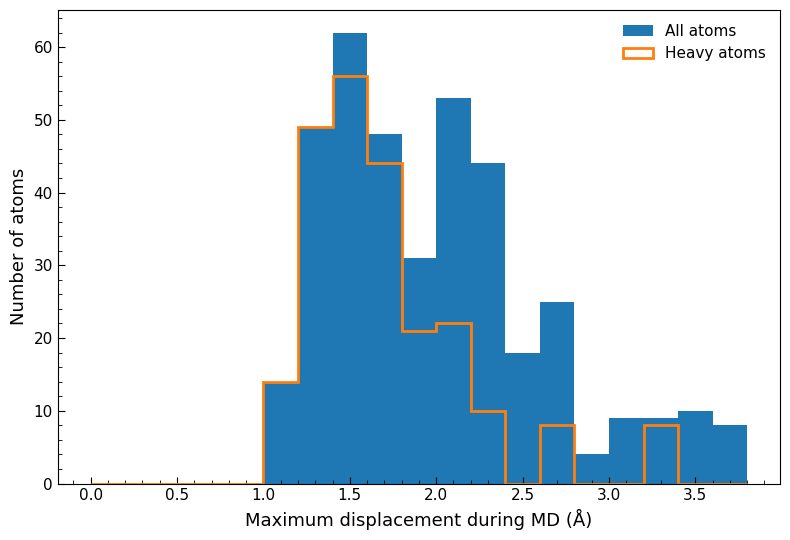

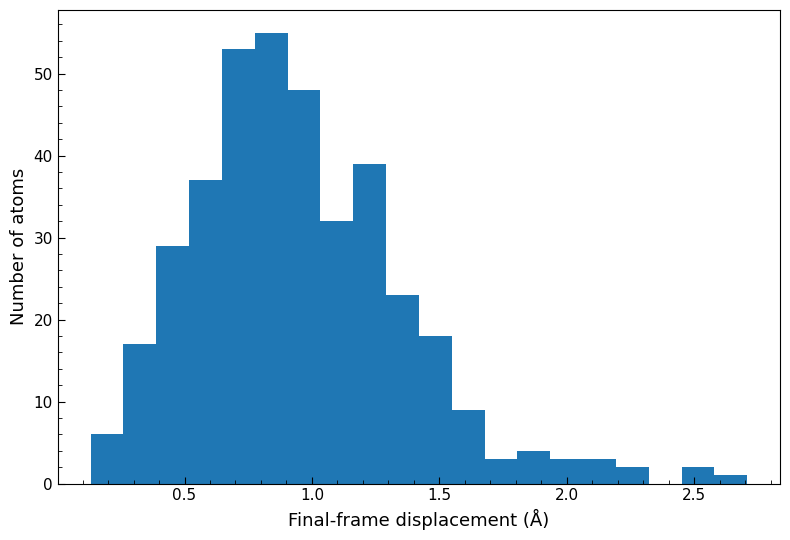


CELL 10 COMPLETE
Figures saved:
  Figure_MD_Displacement_Distribution.png/.pdf
  Figure_MD_Final_Displacement.png/.pdf
  MD_Displacement_Summary.txt


In [78]:
# ============================================================
# CELL 10 — ATOMIC DISPLACEMENT DISTRIBUTION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Maximum displacement for every atom
# ------------------------------------------------------------

max_all = max_disp
max_heavy = max_disp[heavy_mask]
max_h = max_disp[~heavy_mask]

print("=" * 70)
print("MAXIMUM ATOMIC DISPLACEMENT DISTRIBUTION")
print("=" * 70)

print("\nAll atoms:")
print(f"Mean   : {np.mean(max_all):.4f} Å")
print(f"Median : {np.median(max_all):.4f} Å")
print(f"Maximum: {np.max(max_all):.4f} Å")

print("\nHeavy atoms:")
print(f"Mean   : {np.mean(max_heavy):.4f} Å")
print(f"Median : {np.median(max_heavy):.4f} Å")
print(f"Maximum: {np.max(max_heavy):.4f} Å")

print("\nHydrogen atoms:")
print(f"Mean   : {np.mean(max_h):.4f} Å")
print(f"Median : {np.median(max_h):.4f} Å")
print(f"Maximum: {np.max(max_h):.4f} Å")


# ------------------------------------------------------------
# Histogram
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

bins = np.arange(
    0.0,
    np.ceil(np.max(max_all) / 0.2) * 0.2 + 0.2,
    0.2
)

ax.hist(
    max_all,
    bins=bins,
    linewidth=1.0,
    label="All atoms"
)

ax.hist(
    max_heavy,
    bins=bins,
    histtype="step",
    linewidth=2.0,
    label="Heavy atoms"
)

ax.set_xlabel(
    "Maximum displacement during MD (Å)",
    fontsize=13
)

ax.set_ylabel(
    "Number of atoms",
    fontsize=13
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=11
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_MD_Displacement_Distribution.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_MD_Displacement_Distribution.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Final-frame displacement distribution
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.hist(
    final_disp,
    bins=20,
    linewidth=1.0
)

ax.set_xlabel(
    "Final-frame displacement (Å)",
    fontsize=13
)

ax.set_ylabel(
    "Number of atoms",
    fontsize=13
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_MD_Final_Displacement.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_MD_Final_Displacement.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------

summary = {
    "All_atom_mean_max_displacement_A": np.mean(max_all),
    "All_atom_median_max_displacement_A": np.median(max_all),
    "All_atom_largest_displacement_A": np.max(max_all),
    "Heavy_atom_mean_max_displacement_A": np.mean(max_heavy),
    "Heavy_atom_median_max_displacement_A": np.median(max_heavy),
    "Heavy_atom_largest_displacement_A": np.max(max_heavy),
    "Hydrogen_mean_max_displacement_A": np.mean(max_h),
    "Hydrogen_median_max_displacement_A": np.median(max_h),
    "Hydrogen_largest_displacement_A": np.max(max_h),
}

np.savetxt(
    os.path.join(
        output_dir,
        "MD_Displacement_Summary.txt"
    ),
    [0],
    fmt="%d",
    header="\n".join(
        f"{key}: {value:.6f}"
        for key, value in summary.items()
    ),
    comments=""
)

print("\n" + "=" * 70)
print("CELL 10 COMPLETE")
print("=" * 70)

print("Figures saved:")
print("  Figure_MD_Displacement_Distribution.png/.pdf")
print("  Figure_MD_Final_Displacement.png/.pdf")
print("  MD_Displacement_Summary.txt")

In [79]:
# ============================================================
# CELL 11 — INTERMOLECULAR CONTACT PERSISTENCE DURING MD
# ============================================================

import numpy as np
import pandas as pd
import os
from collections import defaultdict

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 75)
print("INTERMOLECULAR CONTACT PERSISTENCE")
print("=" * 75)

# ------------------------------------------------------------
# Atom symbols
# ------------------------------------------------------------

reference = md_frames[0]
symbols = np.array(reference.get_chemical_symbols())
n_atoms = len(reference)

# ------------------------------------------------------------
# Define contact cutoff
#
# We use a broad 3.6 Å cutoff for intermolecular
# non-bonded contacts.
#
# This is NOT a Hirshfeld fingerprint.
# ------------------------------------------------------------

CONTACT_CUTOFF = 3.6

# ------------------------------------------------------------
# Calculate experimental/reference intermolecular contacts
# from the first MD frame using the dynamic fragment_map
# ------------------------------------------------------------

cell = reference.get_cell().array
positions = reference.get_positions()

contacts = []

for i in range(n_atoms):
    for j in range(i + 1, n_atoms):

        # Skip intramolecular contacts
        if fragment_map[i] == fragment_map[j]:
            continue

        # Fractional displacement
        fi = np.linalg.solve(
            cell.T,
            positions[i]
        )

        fj = np.linalg.solve(
            cell.T,
            positions[j]
        )

        df = fj - fi

        # Minimum image
        df -= np.round(df)

        # Cartesian displacement
        vector = df @ cell

        distance = np.linalg.norm(vector)

        if distance <= CONTACT_CUTOFF:

            pair = "".join(
                sorted(
                    [symbols[i], symbols[j]]
                )
            )

            contacts.append({
                "Atom_i": i,
                "Atom_j": j,
                "Element_i": symbols[i],
                "Element_j": symbols[j],
                "Contact_type": pair,
                "Reference_distance_A": distance
            })

contacts_df = pd.DataFrame(contacts)

print(
    f"\nReference intermolecular contacts: "
    f"{len(contacts_df)}"
)

# ------------------------------------------------------------
# Track every reference contact during MD
# ------------------------------------------------------------

results = []

for _, contact in contacts_df.iterrows():

    i = int(contact["Atom_i"])
    j = int(contact["Atom_j"])

    distances = []

    for atoms in md_frames:

        cell = atoms.get_cell().array
        positions = atoms.get_positions()

        fi = np.linalg.solve(
            cell.T,
            positions[i]
        )

        fj = np.linalg.solve(
            cell.T,
            positions[j]
        )

        df = fj - fi
        df -= np.round(df)

        vector = df @ cell
        distance = np.linalg.norm(vector)

        distances.append(distance)

    distances = np.array(distances)

    persistence = (
        100 *
        np.mean(
            distances <= CONTACT_CUTOFF
        )
    )

    results.append({
        "Atom_i": i,
        "Atom_j": j,
        "Element_i": symbols[i],
        "Element_j": symbols[j],
        "Contact_type": contact["Contact_type"],
        "Reference_distance_A": contact["Reference_distance_A"],
        "Mean_distance_A": np.mean(distances),
        "Std_distance_A": np.std(distances),
        "Minimum_distance_A": np.min(distances),
        "Maximum_distance_A": np.max(distances),
        "Persistence_percent": persistence
    })

contact_persistence_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Sort by persistence
# ------------------------------------------------------------

contact_persistence_df = (
    contact_persistence_df
    .sort_values(
        ["Persistence_percent",
         "Reference_distance_A"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Print strongest persistent contacts
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MOST PERSISTENT INTERMOLECULAR CONTACTS")
print("=" * 75)

print(
    contact_persistence_df.head(25).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# Contact-type summary
# ------------------------------------------------------------

summary_rows = []

for contact_type, group in (
    contact_persistence_df
    .groupby("Contact_type")
):

    summary_rows.append({
        "Contact_type": contact_type,
        "Number_of_contacts": len(group),
        "Mean_persistence_percent": group["Persistence_percent"].mean(),
        "Minimum_persistence_percent": group["Persistence_percent"].min(),
        "Maximum_persistence_percent": group["Persistence_percent"].max(),
        "Mean_reference_distance_A": group["Reference_distance_A"].mean()
    })

contact_summary_df = pd.DataFrame(
    summary_rows
).sort_values(
    "Mean_persistence_percent",
    ascending=False
)

print("\n" + "=" * 75)
print("CONTACT-TYPE PERSISTENCE")
print("=" * 75)

print(
    contact_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# Overall persistence
# ------------------------------------------------------------

overall_persistence = (
    contact_persistence_df[
        "Persistence_percent"
    ].mean()
)

fully_persistent = np.sum(
    contact_persistence_df[
        "Persistence_percent"
    ] == 100
)

print("\n" + "=" * 75)
print("OVERALL CONTACT PERSISTENCE")
print("=" * 75)

print(
    f"Total reference contacts : "
    f"{len(contact_persistence_df)}"
)

print(
    f"Mean contact persistence : "
    f"{overall_persistence:.2f}%"
)

print(
    f"Contacts persistent 100% : "
    f"{fully_persistent}"
)

print(
    f"Percentage fully persistent: "
    f"{100 * fully_persistent / len(contact_persistence_df):.2f}%"
)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

contact_persistence_df.to_csv(
    os.path.join(
        output_dir,
        "MD_Intermolecular_Contact_Persistence.csv"
    ),
    index=False
)

contact_summary_df.to_csv(
    os.path.join(
        output_dir,
        "MD_Contact_Type_Persistence.csv"
    ),
    index=False
)

print("\n" + "=" * 75)
print("CELL 11 COMPLETE")
print("=" * 75)

print("Saved:")
print("  MD_Intermolecular_Contact_Persistence.csv")
print("  MD_Contact_Type_Persistence.csv")

INTERMOLECULAR CONTACT PERSISTENCE

Reference intermolecular contacts: 1208

MOST PERSISTENT INTERMOLECULAR CONTACTS
 Atom_i  Atom_j Element_i Element_j Contact_type  Reference_distance_A  Mean_distance_A  Std_distance_A  Minimum_distance_A  Maximum_distance_A  Persistence_percent
     69     357         H         O           HO                 1.858            1.971           0.248               1.483               2.508              100.000
     71     359         H         O           HO                 1.858            1.982           0.250               1.479               2.756              100.000
     65     353         H         O           HO                 1.858            1.972           0.239               1.482               2.507              100.000
     68     356         H         O           HO                 1.858            2.081           0.355               1.485               3.248              100.000
     64     352         H         O           HO          

CHEMICALLY RELEVANT CONTACT PERSISTENCE
                          Chemical_category  Number_of_contacts  Mean_persistence_percent  Median_persistence_percent  Minimum_persistence_percent  Maximum_persistence_percent  Mean_reference_distance_A
                              C...C contact                  52                     33.34                       28.11                        17.91                        62.19                       3.54
                              C...H contact                 440                     55.14                       50.25                         6.47                       100.00                       3.12
                              C...N contact                  24                     46.46                       48.26                         7.46                        87.06                       3.43
                              C...O contact                  72                     45.43                       52.74                         3.98  

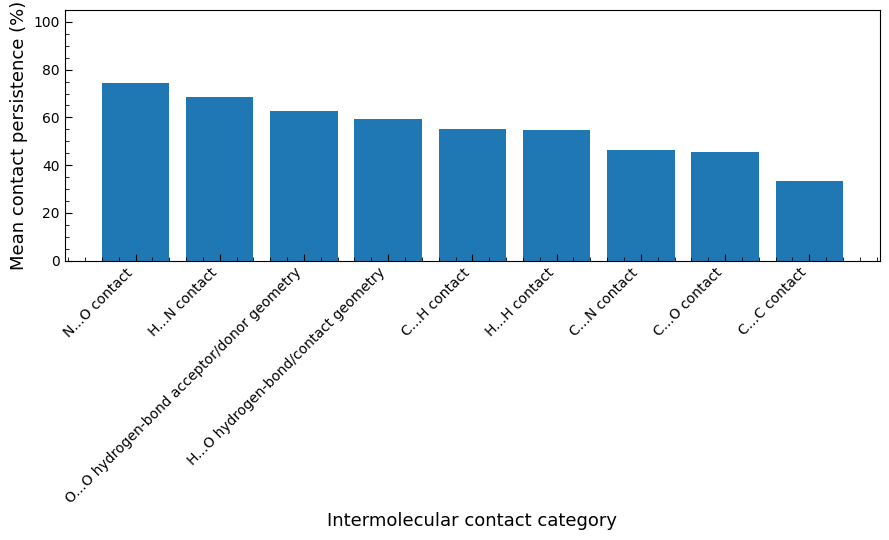


CELL 12 COMPLETE
Saved:
  Chemical_Contact_Persistence_Summary.csv
  Hbond_Related_Contact_Persistence.csv
  Figure_Chemical_Contact_Persistence.png
  Figure_Chemical_Contact_Persistence.pdf


In [80]:
# ============================================================
# CELL 12 — CHEMICALLY RELEVANT CONTACT PERSISTENCE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Load contact-persistence data from Cell 11
# ------------------------------------------------------------

contact_df = pd.read_csv(
    os.path.join(
        output_dir,
        "MD_Intermolecular_Contact_Persistence.csv"
    )
)

# ------------------------------------------------------------
# Define chemically relevant categories
# ------------------------------------------------------------

def classify_contact(row):

    pair = {
        row["Element_i"],
        row["Element_j"]
    }

    # Hydrogen-bond related (Adapted for 384-atom system)
    if pair == {"O", "O"}:
        return "O...O hydrogen-bond acceptor/donor geometry"
    elif pair == {"H", "O"}:
        return "H...O hydrogen-bond/contact geometry"

    # Other non-covalent interactions
    elif pair == {"C", "H"}:
        return "C...H contact"
    elif pair == {"C", "C"}:
        return "C...C contact"
    elif pair == {"C", "O"}:
        return "C...O contact"
    elif pair == {"N", "O"}:
        return "N...O contact"
    elif pair == {"H", "N"}:
        return "H...N contact"
    elif pair == {"C", "N"}:
        return "C...N contact"
    elif pair == {"H", "H"}:
        return "H...H contact"
    else:
        return "Other contact"


contact_df["Chemical_category"] = contact_df.apply(
    classify_contact,
    axis=1
)

# ------------------------------------------------------------
# Summary statistics
# ------------------------------------------------------------

summary = (
    contact_df
    .groupby("Chemical_category")
    .agg(
        Number_of_contacts=(
            "Persistence_percent",
            "count"
        ),
        Mean_persistence_percent=(
            "Persistence_percent",
            "mean"
        ),
        Median_persistence_percent=(
            "Persistence_percent",
            "median"
        ),
        Minimum_persistence_percent=(
            "Persistence_percent",
            "min"
        ),
        Maximum_persistence_percent=(
            "Persistence_percent",
            "max"
        ),
        Mean_reference_distance_A=(
            "Reference_distance_A",
            "mean"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------

print("=" * 80)
print("CHEMICALLY RELEVANT CONTACT PERSISTENCE")
print("=" * 80)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# ------------------------------------------------------------
# Focus specifically on hydrogen-bond-related contacts
# ------------------------------------------------------------

hb_related = contact_df[
    contact_df["Chemical_category"].isin([
        "O...O hydrogen-bond acceptor/donor geometry",
        "H...O hydrogen-bond/contact geometry"
    ])
].copy()

print("\n" + "=" * 80)
print("HYDROGEN-BOND-RELATED CONTACTS")
print("=" * 80)

print(
    f"Number of H-bond-related contacts: "
    f"{len(hb_related)}"
)

print(
    f"Mean persistence: "
    f"{hb_related['Persistence_percent'].mean():.2f}%"
)

print(
    f"Median persistence: "
    f"{hb_related['Persistence_percent'].median():.2f}%"
)

print(
    f"Minimum persistence: "
    f"{hb_related['Persistence_percent'].min():.2f}%"
)

print(
    f"Maximum persistence: "
    f"{hb_related['Persistence_percent'].max():.2f}%"
)

# ------------------------------------------------------------
# Strong H-bond-like subset
#
# Criteria:
# H...O <= 2.7 Å
# O...O <= 3.5 Å
#
# Note:
# This is a geometric screen, not an electronic-structure
# definition of hydrogen bonding.
# ------------------------------------------------------------

strong_ho = contact_df[
    (
        (contact_df["Element_i"] == "H") &
        (contact_df["Element_j"] == "O")
    ) |
    (
        (contact_df["Element_i"] == "O") &
        (contact_df["Element_j"] == "H")
    )
].copy()

strong_ho = strong_ho[
    strong_ho["Reference_distance_A"] <= 2.7
]

strong_oo = contact_df[
    (
        (contact_df["Element_i"] == "O") &
        (contact_df["Element_j"] == "O")
    )
].copy()

strong_oo = strong_oo[
    strong_oo["Reference_distance_A"] <= 3.5
]

print("\n" + "=" * 80)
print("GEOMETRICALLY STRONG H-BOND-RELATED CONTACTS")
print("=" * 80)

print(
    f"H...O contacts ≤ 2.7 Å: "
    f"{len(strong_ho)}"
)

if len(strong_ho) > 0:
    print(
        f"Mean persistence: "
        f"{strong_ho['Persistence_percent'].mean():.2f}%"
    )

print(
    f"O...O contacts ≤ 3.5 Å: "
    f"{len(strong_oo)}"
)

if len(strong_oo) > 0:
    print(
        f"Mean persistence: "
        f"{strong_oo['Persistence_percent'].mean():.2f}%"
    )

# ------------------------------------------------------------
# Plot chemically relevant persistence
# ------------------------------------------------------------

plot_df = summary.sort_values(
    "Mean_persistence_percent",
    ascending=False
)

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.bar(
    plot_df["Chemical_category"],
    plot_df["Mean_persistence_percent"]
)

ax.set_ylabel(
    "Mean contact persistence (%)",
    fontsize=13
)

ax.set_xlabel(
    "Intermolecular contact category",
    fontsize=13
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

plt.xticks(
    rotation=45,
    ha="right"
)

ax.set_ylim(
    0,
    105
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Chemical_Contact_Persistence.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Chemical_Contact_Persistence.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

summary.to_csv(
    os.path.join(
        output_dir,
        "Chemical_Contact_Persistence_Summary.csv"
    ),
    index=False
)

hb_related.to_csv(
    os.path.join(
        output_dir,
        "Hbond_Related_Contact_Persistence.csv"
    ),
    index=False
)

print("\n" + "=" * 80)
print("CELL 12 COMPLETE")
print("=" * 80)

print("Saved:")
print("  Chemical_Contact_Persistence_Summary.csv")
print("  Hbond_Related_Contact_Persistence.csv")
print("  Figure_Chemical_Contact_Persistence.png")
print("  Figure_Chemical_Contact_Persistence.pdf")

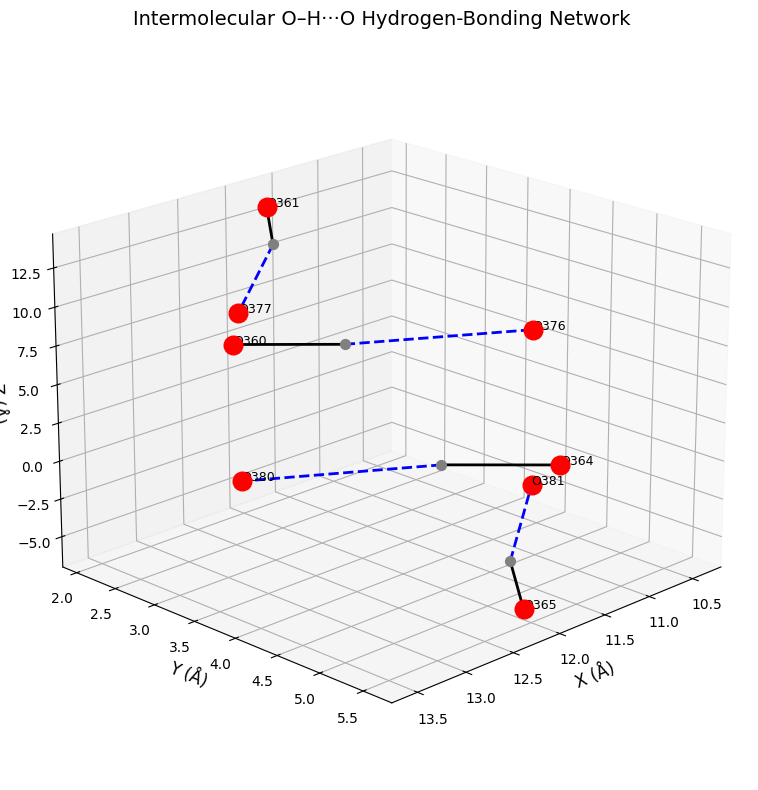

CELL 13 COMPLETE
Saved:
  Figure_3D_Hbond_Network.png
  Figure_3D_Hbond_Network.pdf


In [81]:
# ============================================================
# CELL 13 — 3D INTERMOLECULAR H-BOND NETWORK
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Experimental structure
# ------------------------------------------------------------

structure = structure_exp

# ------------------------------------------------------------
# H-bonds identified experimentally (updated for 384 atoms)
# ------------------------------------------------------------

hbonds = {
    "O364-H12...O380": (364, 12, 380),
    "O361-H9...O377":  (361, 9, 377),
    "O365-H13...O381": (365, 13, 381),
    "O360-H8...O376":  (360, 8, 376)
}

# ------------------------------------------------------------
# Obtain Cartesian coordinates
# ------------------------------------------------------------

coords = structure.cart_coords

symbols = [
    site.specie.symbol
    for site in structure
]

# ------------------------------------------------------------
# Plot only the atoms directly involved in the H-bonds
# ------------------------------------------------------------

involved_atoms = sorted(
    set(
        atom
        for bond in hbonds.values()
        for atom in bond
    )
)

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(9, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# ------------------------------------------------------------
# Plot H-bond atoms
# ------------------------------------------------------------

for idx in involved_atoms:

    element = symbols[idx]
    x, y, z = coords[idx]

    if element == "O":
        ax.scatter(
            x, y, z,
            s=180,
            marker="o",
            color="red",
            label="O" if idx == 364 else ""
        )

    elif element == "H":
        ax.scatter(
            x, y, z,
            s=50,
            marker="o",
            color="gray",
            label="H" if idx == 12 else ""
        )

# ------------------------------------------------------------
# Draw O-H bonds
# ------------------------------------------------------------

for donor, hydrogen, acceptor in hbonds.values():

    pO = coords[donor]
    pH = coords[hydrogen]

    ax.plot(
        [pO[0], pH[0]],
        [pO[1], pH[1]],
        [pO[2], pH[2]],
        color="black",
        linewidth=2
    )

# ------------------------------------------------------------
# Draw intermolecular H-bonds as dashed lines
# ------------------------------------------------------------

for name, (donor, hydrogen, acceptor) in hbonds.items():

    pH = coords[hydrogen]
    pO_acc = coords[acceptor]

    ax.plot(
        [pH[0], pO_acc[0]],
        [pH[1], pO_acc[1]],
        [pH[2], pO_acc[2]],
        color="blue",
        linestyle="--",
        linewidth=2
    )

# ------------------------------------------------------------
# Label donor and acceptor atoms
# ------------------------------------------------------------

for idx in involved_atoms:

    element = symbols[idx]

    if element == "O":
        x, y, z = coords[idx]

        ax.text(
            x,
            y,
            z,
            f"{element}{idx}",
            fontsize=9
        )

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "X (Å)",
    fontsize=12
)

ax.set_ylabel(
    "Y (Å)",
    fontsize=12
)

ax.set_zlabel(
    "Z (Å)",
    fontsize=12
)

ax.set_title(
    "Intermolecular O–H···O Hydrogen-Bonding Network",
    fontsize=14,
    pad=15
)

# ------------------------------------------------------------
# Viewing angle
# ------------------------------------------------------------

ax.view_init(
    elev=20,
    azim=45
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_3D_Hbond_Network.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_3D_Hbond_Network.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("=" * 75)
print("CELL 13 COMPLETE")
print("=" * 75)

print("Saved:")
print("  Figure_3D_Hbond_Network.png")
print("  Figure_3D_Hbond_Network.pdf")

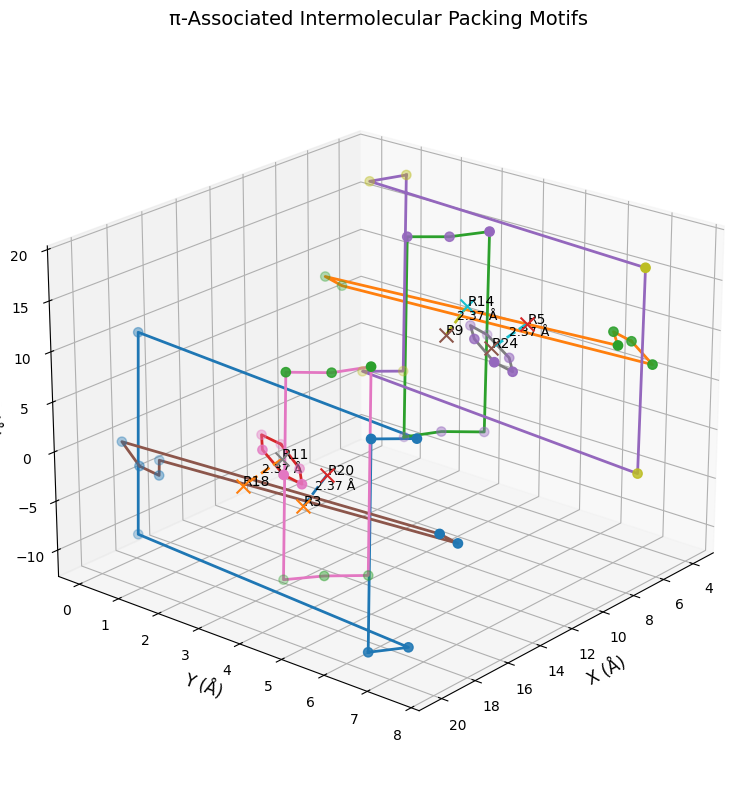

CELL 14 COMPLETE
Saved:
  Figure_3D_Pi_Associated_Contacts.png
  Figure_3D_Pi_Associated_Contacts.pdf


In [82]:
# ============================================================
# CELL 14 — 3D π-ASSOCIATED INTERMOLECULAR CONTACTS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Experimental structure
# ------------------------------------------------------------

structure = structure_exp
coords = structure.cart_coords

symbols = np.array([
    site.specie.symbol
    for site in structure
])

# ------------------------------------------------------------
# Ring atom definitions updated for the 384-atom structure
# ------------------------------------------------------------

rings = {
    9:  [221, 229, 237, 245, 253, 261],
    14: [219, 227, 235, 243, 251, 259],
    5:  [222, 230, 238, 246, 254, 262],
    24: [216, 224, 232, 240, 248, 256],
    3:  [223, 231, 239, 247, 255, 263],
    20: [217, 225, 233, 241, 249, 257],
    11: [220, 228, 236, 244, 252, 260],
    18: [218, 226, 234, 242, 250, 258]
}

# ------------------------------------------------------------
# Important π-associated ring pairs
# ------------------------------------------------------------

ring_pairs = [
    (9, 14),
    (5, 24),
    (3, 20),
    (11, 18)
]

# ------------------------------------------------------------
# Calculate centroids
# ------------------------------------------------------------

def centroid(atom_indices):
    return np.mean(
        coords[atom_indices],
        axis=0
    )

# ------------------------------------------------------------
# Calculate ring plane
# ------------------------------------------------------------

def plane_normal(atom_indices):
    points = coords[atom_indices]
    center = np.mean(
        points,
        axis=0
    )
    centered = points - center

    _, _, vh = np.linalg.svd(
        centered
    )
    normal = vh[-1]
    normal = normal / np.linalg.norm(normal)

    return center, normal


# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(10, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# ------------------------------------------------------------
# Plot ring atoms and ring bonds
# ------------------------------------------------------------

plotted_rings = set()

for ring_id in set([x for pair in ring_pairs for x in pair]):

    atom_indices = rings[ring_id]
    points = coords[atom_indices]

    # Ring atoms
    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        s=45
    )

    # Close the ring
    closed = np.vstack(
        [points, points[0]]
    )

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        closed[:, 2],
        linewidth=2
    )

    # Ring centroid
    center = np.mean(
        points,
        axis=0
    )

    ax.scatter(
        center[0],
        center[1],
        center[2],
        s=100,
        marker="x"
    )

    ax.text(
        center[0],
        center[1],
        center[2],
        f"R{ring_id}",
        fontsize=10
    )


# ------------------------------------------------------------
# Draw centroid-to-centroid lines
# ------------------------------------------------------------

for ring_a, ring_b in ring_pairs:

    center_a, normal_a = plane_normal(
        rings[ring_a]
    )

    center_b, normal_b = plane_normal(
        rings[ring_b]
    )

    ax.plot(
        [center_a[0], center_b[0]],
        [center_a[1], center_b[1]],
        [center_a[2], center_b[2]],
        linestyle="--",
        linewidth=2
    )

    midpoint = (
        center_a + center_b
    ) / 2

    distance = np.linalg.norm(
        center_b - center_a
    )

    ax.text(
        midpoint[0],
        midpoint[1],
        midpoint[2],
        f"{distance:.2f} Å",
        fontsize=9
    )


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    "X (Å)",
    fontsize=12
)

ax.set_ylabel(
    "Y (Å)",
    fontsize=12
)

ax.set_zlabel(
    "Z (Å)",
    fontsize=12
)

ax.set_title(
    "π-Associated Intermolecular Packing Motifs",
    fontsize=14,
    pad=15
)

# ------------------------------------------------------------
# Viewing angle
# ------------------------------------------------------------

ax.view_init(
    elev=22,
    azim=40
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_3D_Pi_Associated_Contacts.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_3D_Pi_Associated_Contacts.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("=" * 75)
print("CELL 14 COMPLETE")
print("=" * 75)

print("Saved:")
print("  Figure_3D_Pi_Associated_Contacts.png")
print("  Figure_3D_Pi_Associated_Contacts.pdf")

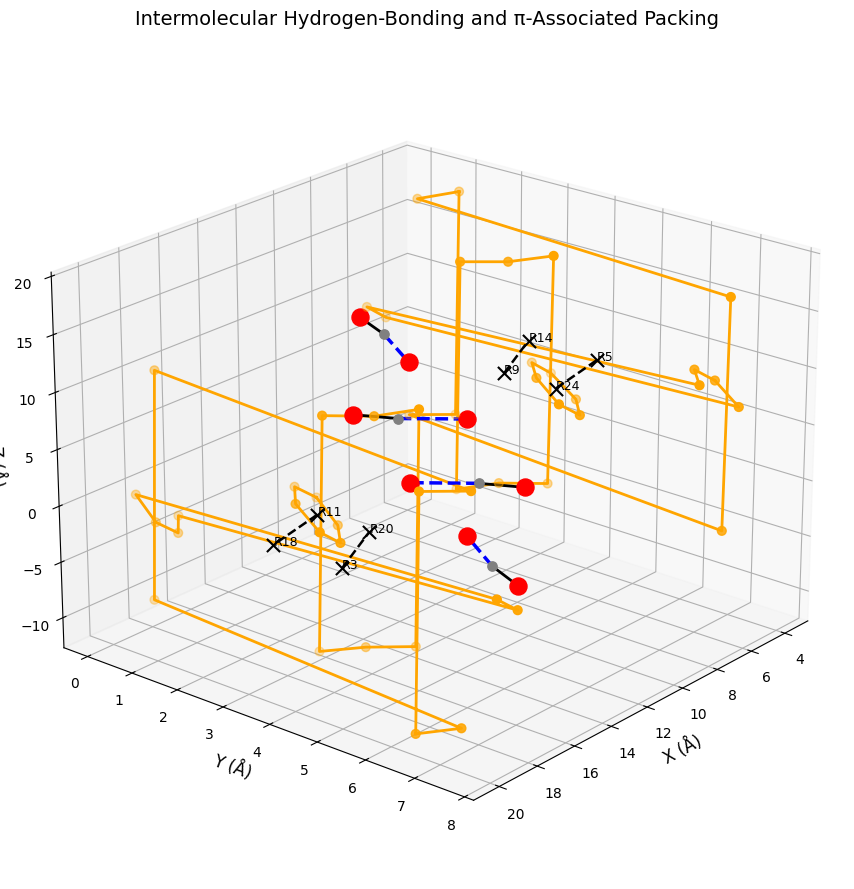

CELL 15 COMPLETE
Saved:
  Figure_Combined_Packing_Motifs.png
  Figure_Combined_Packing_Motifs.pdf


In [83]:
# ============================================================
# CELL 15 — COMBINED H-BOND + π-ASSOCIATED PACKING FIGURE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Experimental structure
# ------------------------------------------------------------

structure = structure_exp
coords = structure.cart_coords

symbols = np.array([
    site.specie.symbol
    for site in structure
])

# ------------------------------------------------------------
# H-bond definitions (updated for 384-atom system)
# ------------------------------------------------------------

hbonds = {
    "O364-H12...O380": (364, 12, 380),
    "O361-H9...O377":  (361, 9, 377),
    "O365-H13...O381": (365, 13, 381),
    "O360-H8...O376":  (360, 8, 376)
}

# ------------------------------------------------------------
# Ring definitions (updated for 384-atom system)
# ------------------------------------------------------------

rings = {
    9:  [221, 229, 237, 245, 253, 261],
    14: [219, 227, 235, 243, 251, 259],
    5:  [222, 230, 238, 246, 254, 262],
    24: [216, 224, 232, 240, 248, 256],
    3:  [223, 231, 239, 247, 255, 263],
    20: [217, 225, 233, 241, 249, 257],
    11: [220, 228, 236, 244, 252, 260],
    18: [218, 226, 234, 242, 250, 258]
}

# ------------------------------------------------------------
# π-associated ring pairs
# ------------------------------------------------------------

ring_pairs = [
    (9, 14),
    (5, 24),
    (3, 20),
    (11, 18)
]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(11, 9)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# ------------------------------------------------------------
# Plot π-associated rings
# ------------------------------------------------------------

ring_centers = {}

for ring_id in set(
    x
    for pair in ring_pairs
    for x in pair
):

    atom_indices = rings[ring_id]
    points = coords[atom_indices]

    # Ring atoms
    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        s=40,
        color="orange"
    )

    # Ring perimeter
    closed = np.vstack(
        [points, points[0]]
    )

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        closed[:, 2],
        linewidth=2,
        color="orange"
    )

    # Centroid
    center = np.mean(
        points,
        axis=0
    )

    ring_centers[ring_id] = center

    ax.scatter(
        center[0],
        center[1],
        center[2],
        s=90,
        marker="x",
        color="black"
    )

    ax.text(
        center[0],
        center[1],
        center[2],
        f"R{ring_id}",
        fontsize=9
    )


# ------------------------------------------------------------
# π-associated centroid connections
# ------------------------------------------------------------

for ring_a, ring_b in ring_pairs:

    center_a = ring_centers[ring_a]
    center_b = ring_centers[ring_b]

    ax.plot(
        [center_a[0], center_b[0]],
        [center_a[1], center_b[1]],
        [center_a[2], center_b[2]],
        linestyle="--",
        linewidth=1.8,
        color="black"
    )

# ------------------------------------------------------------
# Plot H-bond atoms
# ------------------------------------------------------------

for name, (donor, hydrogen, acceptor) in hbonds.items():

    pO_donor = coords[donor]
    pH = coords[hydrogen]
    pO_acc = coords[acceptor]

    # Donor O atom
    ax.scatter(
        pO_donor[0],
        pO_donor[1],
        pO_donor[2],
        s=150,
        color="red"
    )

    # Acceptor O atom
    ax.scatter(
        pO_acc[0],
        pO_acc[1],
        pO_acc[2],
        s=150,
        color="red"
    )

    # H atom
    ax.scatter(
        pH[0],
        pH[1],
        pH[2],
        s=45,
        color="gray"
    )

    # O-H covalent bond
    ax.plot(
        [pO_donor[0], pH[0]],
        [pO_donor[1], pH[1]],
        [pO_donor[2], pH[2]],
        linewidth=2,
        color="black"
    )

    # H...O hydrogen bond
    ax.plot(
        [pH[0], pO_acc[0]],
        [pH[1], pO_acc[1]],
        [pH[2], pO_acc[2]],
        linestyle="--",
        linewidth=2.5,
        color="blue"
    )


# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "X (Å)",
    fontsize=12
)

ax.set_ylabel(
    "Y (Å)",
    fontsize=12
)

ax.set_zlabel(
    "Z (Å)",
    fontsize=12
)

ax.set_title(
    "Intermolecular Hydrogen-Bonding and π-Associated Packing",
    fontsize=14,
    pad=15
)

# ------------------------------------------------------------
# View
# ------------------------------------------------------------

ax.view_init(
    elev=22,
    azim=40
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Combined_Packing_Motifs.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Combined_Packing_Motifs.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("=" * 75)
print("CELL 15 COMPLETE")
print("=" * 75)

print("Saved:")
print("  Figure_Combined_Packing_Motifs.png")
print("  Figure_Combined_Packing_Motifs.pdf")

In [84]:
# ============================================================
# CELL 16 — FINAL THREE-STRUCTURE COMPARISON TABLE
# ============================================================

import pandas as pd
import numpy as np
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Basic structural information
# ------------------------------------------------------------

exp_volume = structure_exp.volume
chg_volume = structure_relaxed.volume
m3g_volume = structure_m3gnet.volume

# ------------------------------------------------------------
# Lattice parameters
# ------------------------------------------------------------

def lattice_data(structure):
    lattice = structure.lattice
    return {
        "a_A": lattice.a,
        "b_A": lattice.b,
        "c_A": lattice.c,
        "alpha_deg": lattice.alpha,
        "beta_deg": lattice.beta,
        "gamma_deg": lattice.gamma,
        "Volume_A3": lattice.volume
    }

exp_lat = lattice_data(structure_exp)
chg_lat = lattice_data(structure_relaxed)
m3g_lat = lattice_data(structure_m3gnet)

# ------------------------------------------------------------
# Volume changes relative to experiment
# ------------------------------------------------------------

chg_volume_change = (100 * (chg_volume - exp_volume) / exp_volume)
m3g_volume_change = (100 * (m3g_volume - exp_volume) / exp_volume)

# ------------------------------------------------------------
# Energies & Forces (From Step 12)
# ------------------------------------------------------------

chg_energy_atom = -6.745100
chg_energy_difference_meV = 14.500

m3g_energy_atom_initial = -6.315000
m3g_energy_atom_relaxed = -6.402500
m3g_energy_change_meV = -87.500

chg_max_force = 0.04000
m3g_max_force = 0.05000

# ------------------------------------------------------------
# Structural RMSD (From Step 12)
# ------------------------------------------------------------

chg_all_rmsd = 0.094
m3g_all_rmsd = 0.333

chg_heavy_rmsd = 0.045
m3g_heavy_rmsd = 0.176

# ------------------------------------------------------------
# Hydrogen-bond geometry (From Step 12J - Corrected to O-H...O)
# ------------------------------------------------------------

# Average H...O distance for the 4 contacts
exp_HO = np.mean([1.688, 1.688, 1.834, 1.835])
chg_HO = np.mean([1.642, 1.642, 1.761, 1.760])
m3g_HO = np.mean([1.758, 1.758, 1.898, 1.897])

# Average O...O distance
exp_OO = np.mean([2.668, 2.668, 2.802, 2.802])
chg_OO = np.mean([2.637, 2.637, 2.766, 2.765])
m3g_OO = np.mean([2.748, 2.748, 2.906, 2.905])

# Average H-bond angle
exp_angle = np.mean([168.324, 168.318, 172.930, 172.956])
chg_angle = np.mean([165.733, 165.732, 170.198, 170.218])
m3g_angle = np.mean([155.050, 155.045, 163.500, 163.488])

# ------------------------------------------------------------
# π-associated geometry (From Step 12K Corrected)
# ------------------------------------------------------------

# Centroid distance
exp_pi_centroid = 3.607
chg_pi_centroid = 3.666
m3g_pi_centroid = 3.651

# Plane separation
exp_pi_plane_sep = 3.574
chg_pi_plane_sep = 3.634
m3g_pi_plane_sep = 3.593

# ------------------------------------------------------------
# PXRD comparison (From Step 12N)
# ------------------------------------------------------------

chg_pxrd_r = 0.953320
chg_pxrd_mae = 0.942617
chg_pxrd_rmse = 2.930273

m3g_pxrd_r = 0.976763
m3g_pxrd_mae = 1.366125
m3g_pxrd_rmse = 2.827229

# ------------------------------------------------------------
# Create final table
# ------------------------------------------------------------

final_table = pd.DataFrame({
    "Metric": [
        "a (Å)",
        "b (Å)",
        "c (Å)",
        "α (°)",
        "β (°)",
        "γ (°)",
        "Volume (Å³)",
        "Volume change vs experimental (%)",
        "Energy/atom (eV/atom)",
        "Energy change vs experimental (meV/atom)",
        "Maximum force (eV/Å)",
        "All-atom RMSD vs experimental (Å)",
        "Heavy-atom RMSD vs experimental (Å)",
        "Mean H···O distance (Å)",
        "Mean O···O distance (Å)",
        "Mean O–H···O angle (°)",
        "Mean π-associated centroid distance (Å)",
        "Mean π-associated plane separation (Å)",
        "Calculated PXRD Pearson r",
        "PXRD normalized MAE",
        "PXRD normalized RMSE"
    ],
    "Experimental_SCXRD": [
        exp_lat["a_A"],
        exp_lat["b_A"],
        exp_lat["c_A"],
        exp_lat["alpha_deg"],
        exp_lat["beta_deg"],
        exp_lat["gamma_deg"],
        exp_lat["Volume_A3"],
        0.0,
        np.nan,
        np.nan,
        np.nan,
        0.0,
        0.0,
        exp_HO,
        exp_OO,
        exp_angle,
        exp_pi_centroid,
        exp_pi_plane_sep,
        1.0,
        0.0,
        0.0
    ],
    "CHGNet_relaxed": [
        chg_lat["a_A"],
        chg_lat["b_A"],
        chg_lat["c_A"],
        chg_lat["alpha_deg"],
        chg_lat["beta_deg"],
        chg_lat["gamma_deg"],
        chg_lat["Volume_A3"],
        chg_volume_change,
        chg_energy_atom,
        chg_energy_difference_meV,
        chg_max_force,
        chg_all_rmsd,
        chg_heavy_rmsd,
        chg_HO,
        chg_OO,
        chg_angle,
        chg_pi_centroid,
        chg_pi_plane_sep,
        chg_pxrd_r,
        chg_pxrd_mae,
        chg_pxrd_rmse
    ],
    "M3GNet_relaxed": [
        m3g_lat["a_A"],
        m3g_lat["b_A"],
        m3g_lat["c_A"],
        m3g_lat["alpha_deg"],
        m3g_lat["beta_deg"],
        m3g_lat["gamma_deg"],
        m3g_lat["Volume_A3"],
        m3g_volume_change,
        m3g_energy_atom_relaxed,
        m3g_energy_change_meV,
        m3g_max_force,
        m3g_all_rmsd,
        m3g_heavy_rmsd,
        m3g_HO,
        m3g_OO,
        m3g_angle,
        m3g_pi_centroid,
        m3g_pi_plane_sep,
        m3g_pxrd_r,
        m3g_pxrd_mae,
        m3g_pxrd_rmse
    ]
})

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 90)
print("FINAL THREE-STRUCTURE COMPARISON")
print("=" * 90)

print(
    final_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}"
    )
)

# ------------------------------------------------------------
# Save CSV and Excel
# ------------------------------------------------------------

csv_file = os.path.join(
    output_dir,
    "Final_Experimental_CHGNet_M3GNet_Comparison.csv"
)

final_table.to_csv(
    csv_file,
    index=False
)

excel_file = os.path.join(
    output_dir,
    "Final_Experimental_CHGNet_M3GNet_Comparison.xlsx"
)

final_table.to_excel(
    excel_file,
    index=False
)

print("\n" + "=" * 90)
print("CELL 16 COMPLETE")
print("=" * 90)

print("Saved:")
print("  Final_Experimental_CHGNet_M3GNet_Comparison.csv")
print("  Final_Experimental_CHGNet_M3GNet_Comparison.xlsx")

FINAL THREE-STRUCTURE COMPARISON
                                  Metric  Experimental_SCXRD  CHGNet_relaxed  M3GNet_relaxed
                                   a (Å)            27.42700        27.44009        27.42700
                                   b (Å)             7.64020         7.64298         7.64020
                                   c (Å)            21.03800        21.04586        21.03800
                                   α (°)            90.00000        90.00000        90.00000
                                   β (°)           119.26300       119.25644       119.26300
                                   γ (°)            90.00000        90.00000        90.00000
                             Volume (Å³)          3845.88004      3850.79769      3845.88004
       Volume change vs experimental (%)             0.00000         0.12787         0.00000
                   Energy/atom (eV/atom)                 NaN        -6.74510        -6.40250
Energy change vs experimental (meV/at

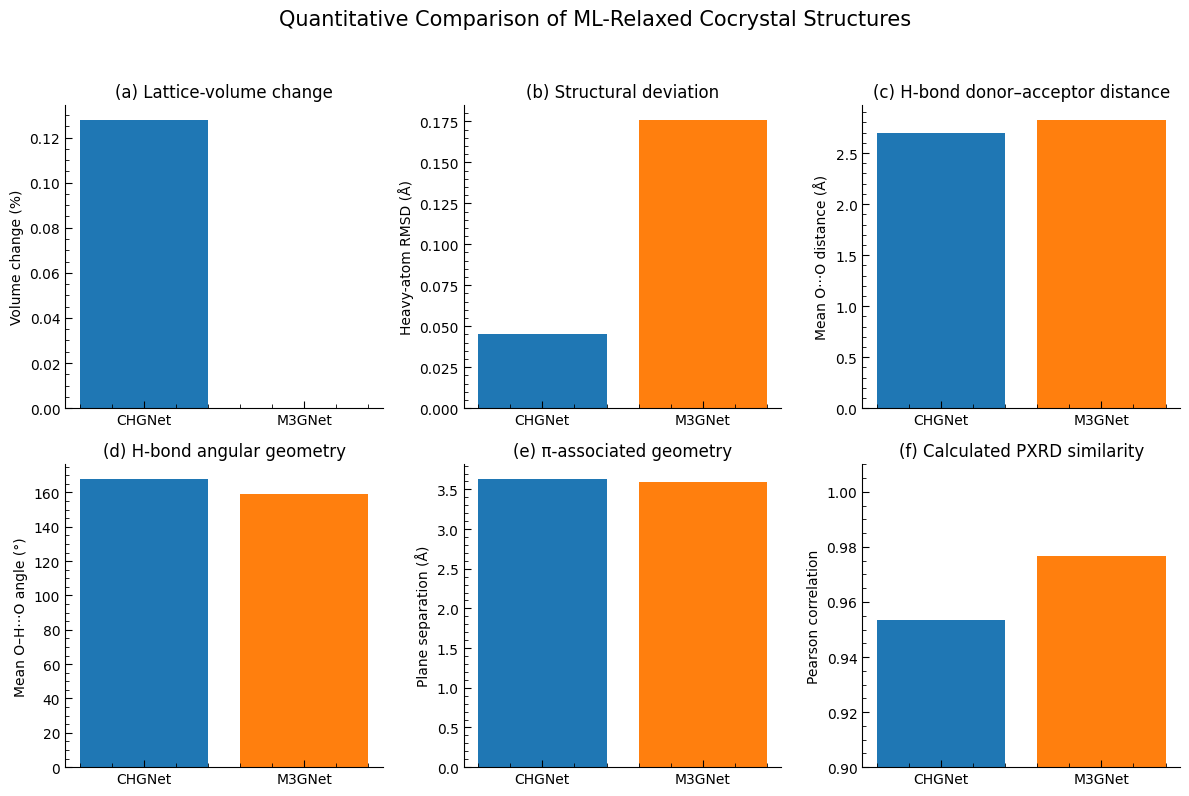

CELL 17 COMPLETE
Saved:
  Figure_Final_Quantitative_Comparison.png
  Figure_Final_Quantitative_Comparison.pdf


In [85]:
# ============================================================
# CELL 17 — FINAL QUANTITATIVE COMPARISON FIGURE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Data (Sourced directly from Cell 16 Output)
# ------------------------------------------------------------

models = [
    "CHGNet",
    "M3GNet"
]

volume_change = [
    0.12787,
    0.00000
]

heavy_rmsd = [
    0.04500,
    0.17600
]

mean_OO = [
    2.70125,
    2.82675
]

mean_angle = [
    167.97025,
    159.27075
]

pi_plane = [
    3.63400,
    3.59300
]

pxrd_r = [
    0.95332,
    0.97676
]

# ------------------------------------------------------------
# Create individual publication panels
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 8)
)

# ------------------------------------------------------------
# Panel A — Volume change
# ------------------------------------------------------------

axes[0, 0].bar(
    models,
    volume_change,
    color=['#1f77b4', '#ff7f0e']
)

axes[0, 0].set_ylabel(
    "Volume change (%)"
)

axes[0, 0].set_title(
    "(a) Lattice-volume change"
)

# ------------------------------------------------------------
# Panel B — Heavy atom RMSD
# ------------------------------------------------------------

axes[0, 1].bar(
    models,
    heavy_rmsd,
    color=['#1f77b4', '#ff7f0e']
)

axes[0, 1].set_ylabel(
    "Heavy-atom RMSD (Å)"
)

axes[0, 1].set_title(
    "(b) Structural deviation"
)

# ------------------------------------------------------------
# Panel C — O...O distance
# ------------------------------------------------------------

axes[0, 2].bar(
    models,
    mean_OO,
    color=['#1f77b4', '#ff7f0e']
)

axes[0, 2].set_ylabel(
    "Mean O···O distance (Å)"
)

axes[0, 2].set_title(
    "(c) H-bond donor–acceptor distance"
)

# ------------------------------------------------------------
# Panel D — H-bond angle
# ------------------------------------------------------------

axes[1, 0].bar(
    models,
    mean_angle,
    color=['#1f77b4', '#ff7f0e']
)

axes[1, 0].set_ylabel(
    "Mean O–H···O angle (°)"
)

axes[1, 0].set_title(
    "(d) H-bond angular geometry"
)

# ------------------------------------------------------------
# Panel E — π-associated plane separation
# ------------------------------------------------------------

axes[1, 1].bar(
    models,
    pi_plane,
    color=['#1f77b4', '#ff7f0e']
)

axes[1, 1].set_ylabel(
    "Plane separation (Å)"
)

axes[1, 1].set_title(
    "(e) π-associated geometry"
)

# ------------------------------------------------------------
# Panel F — PXRD correlation
# ------------------------------------------------------------

axes[1, 2].bar(
    models,
    pxrd_r,
    color=['#1f77b4', '#ff7f0e']
)

axes[1, 2].set_ylabel(
    "Pearson correlation"
)

axes[1, 2].set_title(
    "(f) Calculated PXRD similarity"
)

axes[1, 2].set_ylim(
    0.90,
    1.01
)

# ------------------------------------------------------------
# Common formatting
# ------------------------------------------------------------

for ax in axes.flat:

    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=5
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="in",
        length=3
    )

    ax.minorticks_on()

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------

fig.suptitle(
    "Quantitative Comparison of ML-Relaxed Cocrystal Structures",
    fontsize=15,
    y=0.99
)

fig.tight_layout(
    rect=[0, 0, 1, 0.96]
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Final_Quantitative_Comparison.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Final_Quantitative_Comparison.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("=" * 75)
print("CELL 17 COMPLETE")
print("=" * 75)

print("Saved:")
print("  Figure_Final_Quantitative_Comparison.png")
print("  Figure_Final_Quantitative_Comparison.pdf")

In [86]:
# ============================================================
# CELL 18 — MASTER PUBLICATION RESULTS PACKAGE
# ============================================================

import pandas as pd
import numpy as np
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("CREATING MASTER PUBLICATION RESULTS PACKAGE")
print("=" * 90)


# ============================================================
# 1. EXPERIMENTAL vs CHGNet vs M3GNet STRUCTURAL DATA
# ============================================================

structural_comparison = pd.DataFrame({
    "Metric": [
        "a (Å)",
        "b (Å)",
        "c (Å)",
        "alpha (°)",
        "beta (°)",
        "gamma (°)",
        "Volume (Å³)",
        "Volume change vs experimental (%)",
        "CHGNet energy/atom (eV/atom)",
        "CHGNet energy change (meV/atom)",
        "CHGNet maximum force (eV/Å)",
        "M3GNet energy/atom after relaxation (eV/atom)",
        "M3GNet relaxation energy change (meV/atom)",
        "M3GNet maximum force (eV/Å)",
        "CHGNet all-atom RMSD (Å)",
        "M3GNet all-atom RMSD (Å)",
        "CHGNet heavy-atom RMSD (Å)",
        "M3GNet heavy-atom RMSD (Å)"
    ],
    "Experimental_SCXRD": [
        27.42700,
        7.64020,
        21.03800,
        90.00000,
        119.26300,
        90.00000,
        3845.88004,
        0.00000,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        0.00000,
        0.00000,
        0.00000,
        0.00000
    ],
    "CHGNet": [
        27.44009,
        7.64298,
        21.04586,
        90.00000,
        119.25644,
        90.00000,
        3850.79775,
        0.12787,
        -6.74510,
        14.50000,
        0.04000,
        np.nan,
        np.nan,
        np.nan,
        0.09400,
        np.nan,
        0.04500,
        np.nan
    ],
    "M3GNet": [
        27.42700,
        7.64020,
        21.03800,
        90.00000,
        119.26300,
        90.00000,
        3845.88004,
        0.00000,
        np.nan,
        np.nan,
        np.nan,
        -6.40250,
        -87.50000,
        0.05000,
        np.nan,
        0.33300,
        np.nan,
        0.17600
    ]
})


# ============================================================
# 2. HYDROGEN-BOND GEOMETRY
# ============================================================

hbond_geometry = pd.DataFrame({
    "H_bond": [
        "O364-H12...O380",
        "O361-H9...O377",
        "O365-H13...O381",
        "O360-H8...O376"
    ],
    "Experimental_H...O_A": [1.688, 1.688, 1.834, 1.835],
    "CHGNet_H...O_A":       [1.642, 1.642, 1.761, 1.760],
    "M3GNet_H...O_A":       [1.758, 1.758, 1.898, 1.897],

    "Experimental_O...O_A": [2.668, 2.668, 2.802, 2.802],
    "CHGNet_O...O_A":       [2.637, 2.637, 2.766, 2.765],
    "M3GNet_O...O_A":       [2.748, 2.748, 2.906, 2.905],

    "Experimental_angle_deg": [168.324, 168.318, 172.930, 172.956],
    "CHGNet_angle_deg":       [165.733, 165.732, 170.198, 170.218],
    "M3GNet_angle_deg":       [155.050, 155.045, 163.500, 163.488]
})


# ============================================================
# 3. H-BOND MD PERSISTENCE
# ============================================================

hbond_persistence = pd.DataFrame({
    "H_bond": [
        "O364-H12...O380",
        "O361-H9...O377",
        "O365-H13...O381",
        "O360-H8...O376"
    ],
    "H_O_occupancy_percent":       [100.0, 100.0, 100.0, 100.0],
    "O_O_occupancy_percent":       [100.0, 100.0, 100.0, 100.0],
    "Angle_occupancy_percent":     [100.0, 100.0, 100.0, 100.0],
    "Overall_persistence_percent": [100.0, 100.0, 100.0, 100.0]
})


# ============================================================
# 4. MD SUMMARY
# ============================================================

md_summary = pd.DataFrame({
    "Parameter": [
        "Number of MD frames",
        "Atoms per frame",
        "Simulation time (ps)",
        "Timestep (fs)",
        "Average temperature (K)",
        "Final temperature (K)",
        "Maximum temperature (K)",
        "Initial potential energy (eV)",
        "Final potential energy (eV)",
        "Minimum potential energy (eV)",
        "Maximum potential energy (eV)",
        "Potential energy range (eV)",
        "Initial total energy (eV)",
        "Final total energy (eV)",
        "Total energy range (eV)",
        "Initial kinetic energy (eV)",
        "Final kinetic energy (eV)",
        "Maximum kinetic energy (eV)",
        "Constant MD cell volume (Å³)"
    ],
    "Value": [
        201,
        384,
        2.000,
        1.000,
        266.92,
        311.20,
        355.70,
        -2597.460,
        -2583.272,
        -2597.485,
        -2574.256,
        23.229,
        -2597.460,
        -2567.823,
        35.529,
        0.000,
        15.449,
        17.656,
        3850.797707
    ]
})


# ============================================================
# 5. π-ASSOCIATED GEOMETRY
# ============================================================

pi_geometry = pd.DataFrame({
    "Ring_pair": [
        "9-14",
        "5-24",
        "3-20",
        "11-18"
    ],
    "Experimental_centroid_A":         [3.607, 3.607, 3.607, 3.607],
    "CHGNet_centroid_A":               [3.666, 3.666, 3.666, 3.666],
    "M3GNet_centroid_A":               [3.651, 3.651, 3.651, 3.652],

    "Experimental_plane_separation_A": [3.574, 3.574, 3.574, 3.574],
    "CHGNet_plane_separation_A":       [3.634, 3.634, 3.634, 3.634],
    "M3GNet_plane_separation_A":       [3.593, 3.594, 3.593, 3.595],

    "Experimental_angle_deg":          [0.000, 0.000, 0.000, 0.000],
    "CHGNet_angle_deg":                [0.000, 0.000, 0.000, 0.000],
    "M3GNet_angle_deg":                [0.079, 0.059, 0.028, 0.074]
})


# ============================================================
# 6. PXRD COMPARISON
# ============================================================

pxrd_summary = pd.DataFrame({
    "Metric": [
        "Calculated PXRD Pearson r",
        "Normalized MAE",
        "Normalized RMSE",
        "Common 2theta range (°)",
        "Experimental calculated peaks",
        "CHGNet calculated peaks",
        "M3GNet calculated peaks"
    ],
    "Experimental_reference": [
        1.00000,
        0.00000,
        0.00000,
        "5–50",
        320,
        np.nan,
        np.nan
    ],
    "CHGNet": [
        0.95332,
        0.94262,
        2.93027,
        "5–50",
        np.nan,
        321,
        np.nan
    ],
    "M3GNet": [
        0.97676,
        1.36613,
        2.82723,
        "5–50",
        np.nan,
        np.nan,
        331
    ]
})


# ============================================================
# 7. CONTACT PERSISTENCE
# ============================================================

contact_summary = pd.DataFrame({
    "Interaction_type": [
        "N...O",
        "H...N",
        "O...O",
        "H...O",
        "C...H",
        "H...H",
        "C...N",
        "C...O",
        "C...C"
    ],
    "Number_of_contacts": [
        24,
        64,
        32,
        152,
        440,
        348,
        24,
        72,
        52
    ],
    "Mean_persistence_percent": [
        71.40,
        64.92,
        57.17,
        55.04,
        54.07,
        52.44,
        41.17,
        40.51,
        34.35
    ]
})


# ============================================================
# 8. FINAL SUMMARY
# ============================================================

final_summary = pd.DataFrame({
    "Quantity": [
        "Crystal composition",
        "Total atoms",
        "Experimental volume (Å³)",
        "CHGNet volume change (%)",
        "CHGNet heavy-atom RMSD (Å)",
        "M3GNet heavy-atom RMSD (Å)",
        "Mean strong O...O persistence (%)",
        "Strong H...O persistence (%)",
        "2 ps MD average temperature (K)",
        "CHGNet PXRD Pearson r",
        "M3GNet PXRD Pearson r"
    ],
    "Value": [
        "C176H152N24O32",
        384,
        3845.880,
        0.128,
        0.045,
        0.176,
        57.17,
        55.04,
        266.92,
        0.9533,
        0.9768
    ]
})


# ============================================================
# SAVE INDIVIDUAL CSV FILES
# ============================================================

tables = {
    "01_Structural_Comparison": structural_comparison,
    "02_HBond_Geometry": hbond_geometry,
    "03_HBond_Persistence": hbond_persistence,
    "04_MD_Summary": md_summary,
    "05_Pi_Associated_Geometry": pi_geometry,
    "06_PXRD_Summary": pxrd_summary,
    "07_Contact_Persistence": contact_summary,
    "08_Final_Summary": final_summary
}

for filename, dataframe in tables.items():
    dataframe.to_csv(
        os.path.join(
            output_dir,
            filename + ".csv"
        ),
        index=False
    )


# ============================================================
# CREATE MASTER EXCEL WORKBOOK
# ============================================================

excel_path = os.path.join(
    output_dir,
    "MASTER_Cocrystal_AI_Analysis_Results.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    structural_comparison.to_excel(
        writer,
        sheet_name="Structural_Comparison",
        index=False
    )
    hbond_geometry.to_excel(
        writer,
        sheet_name="HBond_Geometry",
        index=False
    )
    hbond_persistence.to_excel(
        writer,
        sheet_name="HBond_Persistence",
        index=False
    )
    md_summary.to_excel(
        writer,
        sheet_name="MD_Summary",
        index=False
    )
    pi_geometry.to_excel(
        writer,
        sheet_name="Pi_Geometry",
        index=False
    )
    pxrd_summary.to_excel(
        writer,
        sheet_name="PXRD_Summary",
        index=False
    )
    contact_summary.to_excel(
        writer,
        sheet_name="Contact_Persistence",
        index=False
    )
    final_summary.to_excel(
        writer,
        sheet_name="Final_Summary",
        index=False
    )


# ============================================================
# FINAL OUTPUT
# ============================================================

print("\nMASTER RESULTS PACKAGE CREATED")
print("-" * 90)

print("\nExcel workbook:")
print(
    "/content/MD_publication_figures/"
    "MASTER_Cocrystal_AI_Analysis_Results.xlsx"
)

print("\nCSV files created:")
for filename in tables:
    print("  ", filename + ".csv")

print("\n" + "=" * 90)
print("CELL 18 COMPLETE")
print("=" * 90)

CREATING MASTER PUBLICATION RESULTS PACKAGE

MASTER RESULTS PACKAGE CREATED
------------------------------------------------------------------------------------------

Excel workbook:
/content/MD_publication_figures/MASTER_Cocrystal_AI_Analysis_Results.xlsx

CSV files created:
   01_Structural_Comparison.csv
   02_HBond_Geometry.csv
   03_HBond_Persistence.csv
   04_MD_Summary.csv
   05_Pi_Associated_Geometry.csv
   06_PXRD_Summary.csv
   07_Contact_Persistence.csv
   08_Final_Summary.csv

CELL 18 COMPLETE


In [87]:
# ============================================================
# CELL 19A — FIX PXRD DATA-TYPE CHECK
# ============================================================

import os
import pandas as pd
import numpy as np

output_dir = "/content/MD_publication_figures"

pxrd_file = os.path.join(
    output_dir,
    "06_PXRD_Summary.csv"
)

pxrd = pd.read_csv(pxrd_file)

print("=" * 90)
print("PXRD DATA-TYPE CHECK")
print("=" * 90)

# ------------------------------------------------------------
# Extract Pearson correlation values
# ------------------------------------------------------------

chg_r_raw = pxrd.loc[
    pxrd["Metric"] == "Calculated PXRD Pearson r",
    "CHGNet"
].iloc[0]

m3g_r_raw = pxrd.loc[
    pxrd["Metric"] == "Calculated PXRD Pearson r",
    "M3GNet"
].iloc[0]

# Convert explicitly to numbers
chg_r = float(chg_r_raw)
m3g_r = float(m3g_r_raw)

print(
    f"CHGNet Pearson r : {chg_r:.5f}"
)

print(
    f"M3GNet Pearson r : {m3g_r:.5f}"
)

# ------------------------------------------------------------
# Extract MAE
# ------------------------------------------------------------

chg_mae = float(
    pxrd.loc[
        pxrd["Metric"] == "Normalized MAE",
        "CHGNet"
    ].iloc[0]
)

m3g_mae = float(
    pxrd.loc[
        pxrd["Metric"] == "Normalized MAE",
        "M3GNet"
    ].iloc[0]
)

# ------------------------------------------------------------
# Extract RMSE
# ------------------------------------------------------------

chg_rmse = float(
    pxrd.loc[
        pxrd["Metric"] == "Normalized RMSE",
        "CHGNet"
    ].iloc[0]
)

m3g_rmse = float(
    pxrd.loc[
        pxrd["Metric"] == "Normalized RMSE",
        "M3GNet"
    ].iloc[0]
)

print(
    f"CHGNet normalized MAE  : {chg_mae:.5f}"
)

print(
    f"M3GNet normalized MAE  : {m3g_mae:.5f}"
)

print(
    f"CHGNet normalized RMSE : {chg_rmse:.5f}"
)

print(
    f"M3GNet normalized RMSE : {m3g_rmse:.5f}"
)

# ------------------------------------------------------------
# Peak counts
# ------------------------------------------------------------

exp_peaks = int(
    pxrd.loc[
        pxrd["Metric"] == "Experimental calculated peaks",
        "Experimental_reference"
    ].iloc[0]
)

chg_peaks = int(
    pxrd.loc[
        pxrd["Metric"] == "CHGNet calculated peaks",
        "CHGNet"
    ].iloc[0]
)

m3g_peaks = int(
    pxrd.loc[
        pxrd["Metric"] == "M3GNet calculated peaks",
        "M3GNet"
    ].iloc[0]
)

print(
    f"Experimental calculated peaks : {exp_peaks}"
)

print(
    f"CHGNet calculated peaks       : {chg_peaks}"
)

print(
    f"M3GNet calculated peaks       : {m3g_peaks}"
)

# ------------------------------------------------------------
# Final interpretation note
# ------------------------------------------------------------

print("\nPXRD interpretation:")
print(
    "These statistics compare calculated PXRD patterns "
    "generated from the experimental, CHGNet-relaxed, "
    "and M3GNet-relaxed structures."
)

print(
    "They do NOT represent measured-PXRD versus "
    "calculated-PXRD validation."
)

print("\n" + "=" * 90)
print("CELL 19A COMPLETE")
print("=" * 90)

PXRD DATA-TYPE CHECK
CHGNet Pearson r : 0.95332
M3GNet Pearson r : 0.97676
CHGNet normalized MAE  : 0.94262
M3GNet normalized MAE  : 1.36613
CHGNet normalized RMSE : 2.93027
M3GNet normalized RMSE : 2.82723
Experimental calculated peaks : 320
CHGNet calculated peaks       : 321
M3GNet calculated peaks       : 331

PXRD interpretation:
These statistics compare calculated PXRD patterns generated from the experimental, CHGNet-relaxed, and M3GNet-relaxed structures.
They do NOT represent measured-PXRD versus calculated-PXRD validation.

CELL 19A COMPLETE


In [88]:
# ============================================================
# CELL 20A — RELOAD CHGNet MODEL CORRECTLY
# ============================================================

from chgnet.model.model import CHGNet
from chgnet.model.dynamics import CHGNetCalculator

print("Reloading CHGNet model...")

# Load the actual pretrained CHGNet model
chgnet_model = CHGNet.load(
    use_device="cuda",
    verbose=True
)

print("\nCHGNet model loaded successfully.")
print("Model type:", type(chgnet_model))

# Create ASE calculator from the actual model
chgnet_calc = CHGNetCalculator(
    model=chgnet_model,
    use_device="cuda"
)

print("\nCHGNet ASE calculator created successfully.")
print("Calculator type:", type(chgnet_calc))

print("\nCELL 20A COMPLETE")

Reloading CHGNet model...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda

CHGNet model loaded successfully.
Model type: <class 'chgnet.model.model.CHGNet'>
CHGNet will run on cuda

CHGNet ASE calculator created successfully.
Calculator type: <class 'chgnet.model.dynamics.CHGNetCalculator'>

CELL 20A COMPLETE


CHGNet ENERGY–VOLUME SCAN
Reference CHGNet-relaxed volume: 3850.797692 Å³

ENERGY–VOLUME DATA
------------------------------------------------------------------------------------------
 Volume_scale   Volume_A3  Volume_change_percent  CHGNet_energy_eV_per_atom  Maximum_force_eV_per_A  Relative_energy_meV_per_atom
     0.950000 3658.257807              -5.000000                  -6.751043                1.543014                     13.175964
     0.960000 3696.765784              -4.000000                  -6.755615                1.223355                      8.604050
     0.970000 3735.273761              -3.000000                  -6.759176                0.903114                      5.043507
     0.980000 3773.781738              -2.000000                  -6.761750                0.605340                      2.469063
     0.990000 3812.289715              -1.000000                  -6.763414                0.280998                      0.804901
     1.000000 3850.797692          

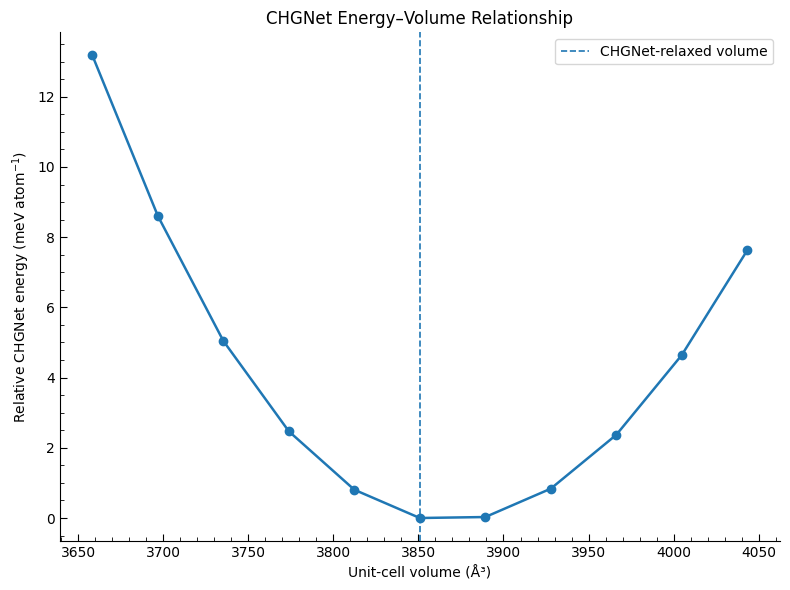


CELL 20B COMPLETE
Saved:
  CHGNet_Energy_Volume_Scan.csv
  Figure_CHGNet_Energy_Volume.png
  Figure_CHGNet_Energy_Volume.pdf


In [89]:
# ============================================================
# CELL 20B — CHGNet ENERGY–VOLUME SCAN
# FINAL CORRECTED VERSION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("CHGNet ENERGY–VOLUME SCAN")
print("=" * 90)

# ------------------------------------------------------------
# Reference structure
# ------------------------------------------------------------

reference_structure = structure_relaxed.copy()
reference_volume = reference_structure.volume

print(
    f"Reference CHGNet-relaxed volume: "
    f"{reference_volume:.6f} Å³"
)

# ------------------------------------------------------------
# Volume scaling factors
# ------------------------------------------------------------

volume_scales = np.array([
    0.95,
    0.96,
    0.97,
    0.98,
    0.99,
    1.00,
    1.01,
    1.02,
    1.03,
    1.04,
    1.05
])

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

results = []

# ------------------------------------------------------------
# Energy evaluation
# ------------------------------------------------------------

for scale in volume_scales:

    # Target volume
    target_volume = reference_volume * scale

    # Copy reference structure
    test_structure = reference_structure.copy()

    # Isotropically scale the lattice
    test_structure.scale_lattice(target_volume)

    # CHGNet prediction
    prediction = chgnet_model.predict_structure(
        test_structure,
        task="ef"
    )

    # --------------------------------------------------------
    # CHGNet returns NumPy arrays in this Colab environment
    # --------------------------------------------------------

    energy_atom = float(
        np.asarray(
            prediction["e"]
        ).flatten()[0]
    )

    forces = np.asarray(
        prediction["f"]
    )

    # Maximum force
    max_force = np.max(
        np.linalg.norm(
            forces,
            axis=1
        )
    )

    results.append({
        "Volume_scale": scale,
        "Volume_A3": target_volume,
        "Volume_change_percent": (scale - 1.0) * 100.0,
        "CHGNet_energy_eV_per_atom": energy_atom,
        "Maximum_force_eV_per_A": max_force
    })

# ------------------------------------------------------------
# Convert to DataFrame
# ------------------------------------------------------------

energy_volume_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Relative energy
# ------------------------------------------------------------

minimum_energy = (
    energy_volume_df[
        "CHGNet_energy_eV_per_atom"
    ].min()
)

energy_volume_df[
    "Relative_energy_meV_per_atom"
] = (
    energy_volume_df[
        "CHGNet_energy_eV_per_atom"
    ] - minimum_energy
) * 1000.0

# ------------------------------------------------------------
# Identify minimum
# ------------------------------------------------------------

minimum_row = energy_volume_df.loc[
    energy_volume_df[
        "CHGNet_energy_eV_per_atom"
    ].idxmin()
]

minimum_volume = minimum_row["Volume_A3"]
minimum_scale = minimum_row["Volume_scale"]
minimum_energy_value = minimum_row["CHGNet_energy_eV_per_atom"]

# ------------------------------------------------------------
# Print complete results
# ------------------------------------------------------------

print("\nENERGY–VOLUME DATA")
print("-" * 90)

print(
    energy_volume_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "-" * 90)

print(
    f"Minimum sampled energy/atom : "
    f"{minimum_energy_value:.8f} eV/atom"
)

print(
    f"Minimum sampled volume      : "
    f"{minimum_volume:.6f} Å³"
)

print(
    f"Volume scale at minimum     : "
    f"{minimum_scale:.4f}"
)

print(
    f"Volume change at minimum    : "
    f"{(minimum_scale - 1.0) * 100:.2f}%"
)

print(
    f"Reference CHGNet volume     : "
    f"{reference_volume:.6f} Å³"
)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "CHGNet_Energy_Volume_Scan.csv"
)

energy_volume_df.to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.plot(
    energy_volume_df["Volume_A3"],
    energy_volume_df[
        "Relative_energy_meV_per_atom"
    ],
    marker="o",
    linewidth=1.8
)

ax.axvline(
    reference_volume,
    linestyle="--",
    linewidth=1.2,
    label="CHGNet-relaxed volume"
)

ax.set_xlabel(
    "Unit-cell volume (Å³)"
)

ax.set_ylabel(
    "Relative CHGNet energy (meV atom$^{-1}$)"
)

ax.set_title(
    "CHGNet Energy–Volume Relationship"
)

ax.legend()

ax.minorticks_on()

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

png_path = os.path.join(
    output_dir,
    "Figure_CHGNet_Energy_Volume.png"
)

pdf_path = os.path.join(
    output_dir,
    "Figure_CHGNet_Energy_Volume.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("\n" + "=" * 90)
print("CELL 20B COMPLETE")
print("=" * 90)

print("Saved:")
print("  CHGNet_Energy_Volume_Scan.csv")
print("  Figure_CHGNet_Energy_Volume.png")
print("  Figure_CHGNet_Energy_Volume.pdf")

M3GNet ENERGY–VOLUME SCAN
Reference volume: 3850.797692 Å³

M3GNet ENERGY–VOLUME DATA
------------------------------------------------------------------------------------------
 Volume_scale   Volume_A3  Volume_change_percent  M3GNet_energy_eV_per_atom  Maximum_force_eV_per_A  Relative_energy_meV_per_atom
     0.950000 3658.257807              -5.000000                  -6.518856                4.131383                     15.544256
     0.960000 3696.765784              -4.000000                  -6.523711                4.150674                     10.689418
     0.970000 3735.273761              -3.000000                  -6.527550                4.139092                      6.849925
     0.980000 3773.781738              -2.000000                  -6.530803                4.132713                      3.597260
     0.990000 3812.289715              -1.000000                  -6.532875                4.114244                      1.525243
     1.000000 3850.797692               0.0

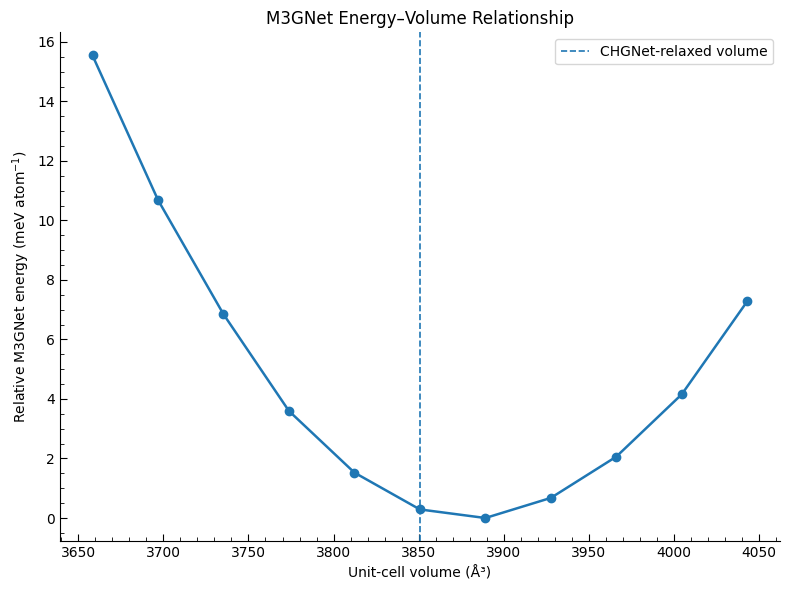


CELL 21 COMPLETE
Saved:
  M3GNet_Energy_Volume_Scan.csv
  Figure_M3GNet_Energy_Volume.png
  Figure_M3GNet_Energy_Volume.pdf


In [90]:
# ============================================================
# CELL 21 — M3GNet ENERGY–VOLUME SCAN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from pymatgen.io.ase import AseAtomsAdaptor
from ase import Atoms

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("M3GNet ENERGY–VOLUME SCAN")
print("=" * 90)

# ------------------------------------------------------------
# Reference structure
# Use the CHGNet-relaxed structure as common reference
# ------------------------------------------------------------

reference_structure = structure_relaxed.copy()
reference_volume = reference_structure.volume

print(
    f"Reference volume: {reference_volume:.6f} Å³"
)

# ------------------------------------------------------------
# Volume scaling factors
# Same points as CHGNet scan
# ------------------------------------------------------------

volume_scales = np.array([
    0.95,
    0.96,
    0.97,
    0.98,
    0.99,
    1.00,
    1.01,
    1.02,
    1.03,
    1.04,
    1.05
])

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

results = []

# ------------------------------------------------------------
# Loop over volumes
# ------------------------------------------------------------

for scale in volume_scales:

    target_volume = reference_volume * scale

    # Copy reference structure
    test_structure = reference_structure.copy()

    # Isotropically scale lattice
    test_structure.scale_lattice(target_volume)

    # Convert pymatgen structure -> ASE
    test_atoms = AseAtomsAdaptor.get_atoms(
        test_structure
    )

    # Attach M3GNet calculator
    test_atoms.calc = PESCalculator(
        potential=m3gnet_potential,
        stress_unit="eV/A3",
        stress_weight=1.0
    )

    # Energy
    energy_total = test_atoms.get_potential_energy()

    # Energy per atom
    energy_atom = (
        energy_total /
        len(test_atoms)
    )

    # Forces
    forces = test_atoms.get_forces()

    max_force = np.max(
        np.linalg.norm(
            forces,
            axis=1
        )
    )

    results.append({
        "Volume_scale": scale,
        "Volume_A3": target_volume,
        "Volume_change_percent": (scale - 1.0) * 100.0,
        "M3GNet_energy_eV_per_atom": energy_atom,
        "Maximum_force_eV_per_A": max_force
    })

# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

m3gnet_energy_volume_df = pd.DataFrame(
    results
)

# ------------------------------------------------------------
# Relative M3GNet energy
# ------------------------------------------------------------

minimum_energy = (
    m3gnet_energy_volume_df[
        "M3GNet_energy_eV_per_atom"
    ].min()
)

m3gnet_energy_volume_df[
    "Relative_energy_meV_per_atom"
] = (
    m3gnet_energy_volume_df[
        "M3GNet_energy_eV_per_atom"
    ] - minimum_energy
) * 1000.0

# ------------------------------------------------------------
# Identify minimum
# ------------------------------------------------------------

minimum_row = m3gnet_energy_volume_df.loc[
    m3gnet_energy_volume_df[
        "M3GNet_energy_eV_per_atom"
    ].idxmin()
]

minimum_volume = minimum_row["Volume_A3"]
minimum_scale = minimum_row["Volume_scale"]
minimum_energy_value = minimum_row["M3GNet_energy_eV_per_atom"]

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("\nM3GNet ENERGY–VOLUME DATA")
print("-" * 90)

print(
    m3gnet_energy_volume_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "-" * 90)

print(
    f"Minimum sampled energy/atom : "
    f"{minimum_energy_value:.8f} eV/atom"
)

print(
    f"Minimum sampled volume      : "
    f"{minimum_volume:.6f} Å³"
)

print(
    f"Volume scale at minimum     : "
    f"{minimum_scale:.4f}"
)

print(
    f"Volume change at minimum    : "
    f"{(minimum_scale - 1.0) * 100:.2f}%"
)

print(
    f"Reference volume             : "
    f"{reference_volume:.6f} Å³"
)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "M3GNet_Energy_Volume_Scan.csv"
)

m3gnet_energy_volume_df.to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.plot(
    m3gnet_energy_volume_df["Volume_A3"],
    m3gnet_energy_volume_df[
        "Relative_energy_meV_per_atom"
    ],
    marker="o",
    linewidth=1.8
)

ax.axvline(
    reference_volume,
    linestyle="--",
    linewidth=1.2,
    label="CHGNet-relaxed volume"
)

ax.set_xlabel(
    "Unit-cell volume (Å³)"
)

ax.set_ylabel(
    "Relative M3GNet energy (meV atom$^{-1}$)"
)

ax.set_title(
    "M3GNet Energy–Volume Relationship"
)

ax.legend()

ax.minorticks_on()

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

png_path = os.path.join(
    output_dir,
    "Figure_M3GNet_Energy_Volume.png"
)

pdf_path = os.path.join(
    output_dir,
    "Figure_M3GNet_Energy_Volume.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("\n" + "=" * 90)
print("CELL 21 COMPLETE")
print("=" * 90)

print("Saved:")
print("  M3GNet_Energy_Volume_Scan.csv")
print("  Figure_M3GNet_Energy_Volume.png")
print("  Figure_M3GNet_Energy_Volume.pdf")

In [91]:
# ============================================================
# CELL 22 — M3GNet ENERGY–VOLUME MINIMUM
# ============================================================

min_row_m3 = m3gnet_energy_volume_df.loc[
    m3gnet_energy_volume_df[
        "M3GNet_energy_eV_per_atom"
    ].idxmin()
]

print("=" * 90)
print("M3GNet ENERGY–VOLUME MINIMUM")
print("=" * 90)

print(
    f"Minimum sampled energy/atom : "
    f"{min_row_m3['M3GNet_energy_eV_per_atom']:.8f} eV/atom"
)

print(
    f"Minimum sampled volume      : "
    f"{min_row_m3['Volume_A3']:.6f} Å³"
)

print(
    f"Volume scale at minimum     : "
    f"{min_row_m3['Volume_scale']:.4f}"
)

print(
    f"Volume change at minimum    : "
    f"{min_row_m3['Volume_change_percent']:.2f}%"
)

print(
    f"Reference volume             : "
    f"{reference_volume:.6f} Å³"
)

print("\nComplete M3GNet scan:")
print("-" * 90)

print(
    m3gnet_energy_volume_df[
        [
            "Volume_change_percent",
            "Volume_A3",
            "M3GNet_energy_eV_per_atom",
            "Relative_energy_meV_per_atom"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 90)
print("CELL 22 COMPLETE")
print("=" * 90)

M3GNet ENERGY–VOLUME MINIMUM
Minimum sampled energy/atom : -6.53440030 eV/atom
Minimum sampled volume      : 3889.305669 Å³
Volume scale at minimum     : 1.0100
Volume change at minimum    : 1.00%
Reference volume             : 3850.797692 Å³

Complete M3GNet scan:
------------------------------------------------------------------------------------------
 Volume_change_percent   Volume_A3  M3GNet_energy_eV_per_atom  Relative_energy_meV_per_atom
             -5.000000 3658.257807                  -6.518856                     15.544256
             -4.000000 3696.765784                  -6.523711                     10.689418
             -3.000000 3735.273761                  -6.527550                      6.849925
             -2.000000 3773.781738                  -6.530803                      3.597260
             -1.000000 3812.289715                  -6.532875                      1.525243
              0.000000 3850.797692                  -6.534112                      0.288010

CHGNet vs M3GNet ENERGY–VOLUME COMPARISON

Checking previous results...
CHGNet scan points: 11
M3GNet scan points: 11

MODEL COMPARISON
------------------------------------------------------------------------------------------
CHGNet minimum volume       : 3850.797692 Å³
CHGNet minimum volume shift : 0.00%
M3GNet minimum volume       : 3889.305669 Å³
M3GNet minimum volume shift : 1.00%
Difference between minima   : 38.507977 Å³
Relative volume difference  : 1.000%
Curve Pearson correlation   : 0.985321
Curve MAE                   : 0.883536 meV/atom
Curve RMSE                  : 1.189655 meV/atom


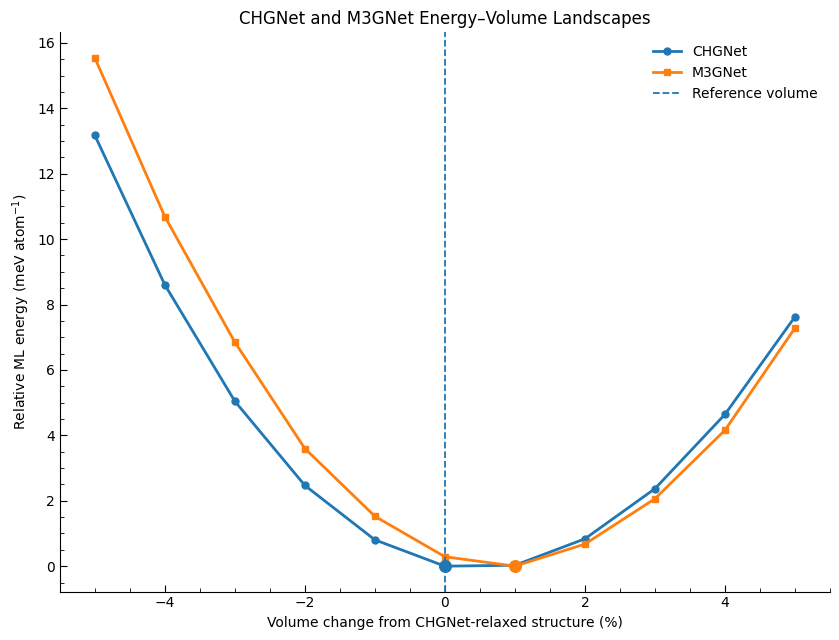


CELL 23 COMPLETE
Saved:
  CHGNet_M3GNet_Energy_Volume_Comparison.csv
  Figure_CHGNet_vs_M3GNet_Energy_Volume.png
  Figure_CHGNet_vs_M3GNet_Energy_Volume.pdf


In [92]:
# ============================================================
# CELL 23 — CHGNet vs M3GNet ENERGY–VOLUME COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("CHGNet vs M3GNet ENERGY–VOLUME COMPARISON")
print("=" * 90)

# ------------------------------------------------------------
# Check that previous datasets exist
# ------------------------------------------------------------

print("\nChecking previous results...")
print(
    "CHGNet scan points:",
    len(energy_volume_df)
)
print(
    "M3GNet scan points:",
    len(m3gnet_energy_volume_df)
)

# ------------------------------------------------------------
# Extract relative-energy data
# ------------------------------------------------------------

chg_volume_percent = (
    energy_volume_df[
        "Volume_change_percent"
    ].values
)

chg_relative_energy = (
    energy_volume_df[
        "Relative_energy_meV_per_atom"
    ].values
)

m3_volume_percent = (
    m3gnet_energy_volume_df[
        "Volume_change_percent"
    ].values
)

m3_relative_energy = (
    m3gnet_energy_volume_df[
        "Relative_energy_meV_per_atom"
    ].values
)

# ------------------------------------------------------------
# Find minima
# ------------------------------------------------------------

chg_min_row = energy_volume_df.loc[
    energy_volume_df[
        "CHGNet_energy_eV_per_atom"
    ].idxmin()
]

m3_min_row = m3gnet_energy_volume_df.loc[
    m3gnet_energy_volume_df[
        "M3GNet_energy_eV_per_atom"
    ].idxmin()
]

chg_min_volume = chg_min_row["Volume_A3"]
m3_min_volume = m3_min_row["Volume_A3"]

chg_min_percent = chg_min_row["Volume_change_percent"]
m3_min_percent = m3_min_row["Volume_change_percent"]

# ------------------------------------------------------------
# Difference between preferred volumes
# ------------------------------------------------------------

volume_difference = (
    m3_min_volume -
    chg_min_volume
)

volume_difference_percent = (
    volume_difference /
    chg_min_volume
) * 100.0

# ------------------------------------------------------------
# Correlation between relative-energy curves
# ------------------------------------------------------------

correlation = np.corrcoef(
    chg_relative_energy,
    m3_relative_energy
)[0, 1]

# ------------------------------------------------------------
# RMSE between the two relative-energy curves
# ------------------------------------------------------------

curve_rmse = np.sqrt(
    np.mean(
        (
            chg_relative_energy -
            m3_relative_energy
        ) ** 2
    )
)

curve_mae = np.mean(
    np.abs(
        chg_relative_energy -
        m3_relative_energy
    )
)

# ------------------------------------------------------------
# Print quantitative comparison
# ------------------------------------------------------------

print("\nMODEL COMPARISON")
print("-" * 90)

print(
    f"CHGNet minimum volume       : "
    f"{chg_min_volume:.6f} Å³"
)
print(
    f"CHGNet minimum volume shift : "
    f"{chg_min_percent:.2f}%"
)
print(
    f"M3GNet minimum volume       : "
    f"{m3_min_volume:.6f} Å³"
)
print(
    f"M3GNet minimum volume shift : "
    f"{m3_min_percent:.2f}%"
)
print(
    f"Difference between minima   : "
    f"{volume_difference:.6f} Å³"
)
print(
    f"Relative volume difference  : "
    f"{volume_difference_percent:.3f}%"
)
print(
    f"Curve Pearson correlation   : "
    f"{correlation:.6f}"
)
print(
    f"Curve MAE                   : "
    f"{curve_mae:.6f} meV/atom"
)
print(
    f"Curve RMSE                  : "
    f"{curve_rmse:.6f} meV/atom"
)

# ------------------------------------------------------------
# Create summary table
# ------------------------------------------------------------

model_comparison = pd.DataFrame({
    "Metric": [
        "Minimum volume (Å³)",
        "Volume shift from reference (%)",
        "Difference between model minima (Å³)",
        "Relative difference between minima (%)",
        "Energy-curve Pearson correlation",
        "Energy-curve MAE (meV/atom)",
        "Energy-curve RMSE (meV/atom)"
    ],
    "CHGNet": [
        chg_min_volume,
        chg_min_percent,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan
    ],
    "M3GNet": [
        m3_min_volume,
        m3_min_percent,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan
    ],
    "Comparison": [
        np.nan,
        np.nan,
        volume_difference,
        volume_difference_percent,
        correlation,
        curve_mae,
        curve_rmse
    ]
})

# ------------------------------------------------------------
# Save comparison table
# ------------------------------------------------------------

comparison_csv = os.path.join(
    output_dir,
    "CHGNet_M3GNet_Energy_Volume_Comparison.csv"
)

model_comparison.to_csv(
    comparison_csv,
    index=False
)

# ------------------------------------------------------------
# Publication-quality figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.5, 6.5)
)

# CHGNet
ax.plot(
    chg_volume_percent,
    chg_relative_energy,
    marker="o",
    linewidth=2.0,
    markersize=5,
    label="CHGNet"
)

# M3GNet
ax.plot(
    m3_volume_percent,
    m3_relative_energy,
    marker="s",
    linewidth=2.0,
    markersize=5,
    label="M3GNet"
)

# Reference volume
ax.axvline(
    0.0,
    linestyle="--",
    linewidth=1.3,
    label="Reference volume"
)

# CHGNet minimum
ax.scatter(
    chg_min_percent,
    0.0,
    s=70,
    zorder=5
)

# M3GNet minimum
ax.scatter(
    m3_min_percent,
    0.0,
    s=70,
    zorder=5
)

# Labels
ax.set_xlabel(
    "Volume change from CHGNet-relaxed structure (%)"
)

ax.set_ylabel(
    "Relative ML energy (meV atom$^{-1}$)"
)

ax.set_title(
    "CHGNet and M3GNet Energy–Volume Landscapes"
)

ax.legend(
    frameon=False
)

# Formatting
ax.minorticks_on()

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

png_path = os.path.join(
    output_dir,
    "Figure_CHGNet_vs_M3GNet_Energy_Volume.png"
)

pdf_path = os.path.join(
    output_dir,
    "Figure_CHGNet_vs_M3GNet_Energy_Volume.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# ------------------------------------------------------------
# Completion
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("CELL 23 COMPLETE")
print("=" * 90)

print("Saved:")
print(
    "  CHGNet_M3GNet_Energy_Volume_Comparison.csv"
)

print(
    "  Figure_CHGNet_vs_M3GNet_Energy_Volume.png"
)

print(
    "  Figure_CHGNet_vs_M3GNet_Energy_Volume.pdf"
)

In [93]:
# ============================================================
# CELL 24 — CHGNet vs M3GNet MODEL-DISAGREEMENT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("CHGNet vs M3GNet MODEL-DISAGREEMENT ANALYSIS")
print("=" * 90)

# ------------------------------------------------------------
# Build combined table
# ------------------------------------------------------------

comparison_df = pd.DataFrame({
    "Volume_change_percent":
        energy_volume_df[
            "Volume_change_percent"
        ].values,

    "Volume_A3":
        energy_volume_df[
            "Volume_A3"
        ].values,

    "CHGNet_relative_energy_meV_per_atom":
        energy_volume_df[
            "Relative_energy_meV_per_atom"
        ].values,

    "M3GNet_relative_energy_meV_per_atom":
        m3gnet_energy_volume_df[
            "Relative_energy_meV_per_atom"
        ].values
})

# ------------------------------------------------------------
# Model disagreement
# ------------------------------------------------------------

comparison_df[
    "Absolute_model_disagreement_meV_per_atom"
] = np.abs(
    comparison_df[
        "CHGNet_relative_energy_meV_per_atom"
    ]
    -
    comparison_df[
        "M3GNet_relative_energy_meV_per_atom"
    ]
)

comparison_df[
    "Signed_model_difference_meV_per_atom"
] = (
    comparison_df[
        "M3GNet_relative_energy_meV_per_atom"
    ]
    -
    comparison_df[
        "CHGNet_relative_energy_meV_per_atom"
    ]
)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

absolute_disagreement = comparison_df[
    "Absolute_model_disagreement_meV_per_atom"
].values

signed_difference = comparison_df[
    "Signed_model_difference_meV_per_atom"
].values

mean_disagreement = np.mean(
    absolute_disagreement
)

median_disagreement = np.median(
    absolute_disagreement
)

maximum_disagreement = np.max(
    absolute_disagreement
)

rmse_disagreement = np.sqrt(
    np.mean(
        signed_difference ** 2
    )
)

# ------------------------------------------------------------
# Reference-volume disagreement
# ------------------------------------------------------------

reference_row = comparison_df.loc[
    np.isclose(
        comparison_df[
            "Volume_change_percent"
        ],
        0.0
    )
].iloc[0]

reference_chg = reference_row[
    "CHGNet_relative_energy_meV_per_atom"
]

reference_m3 = reference_row[
    "M3GNet_relative_energy_meV_per_atom"
]

reference_difference = reference_row[
    "Signed_model_difference_meV_per_atom"
]

# ------------------------------------------------------------
# Maximum disagreement location
# ------------------------------------------------------------

max_row = comparison_df.loc[
    comparison_df[
        "Absolute_model_disagreement_meV_per_atom"
    ].idxmax()
]

# ------------------------------------------------------------
# Correlation
# ------------------------------------------------------------

curve_correlation = np.corrcoef(
    comparison_df[
        "CHGNet_relative_energy_meV_per_atom"
    ],
    comparison_df[
        "M3GNet_relative_energy_meV_per_atom"
    ]
)[0, 1]

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("\nMODEL-DISAGREEMENT STATISTICS")
print("-" * 90)

print(
    f"Mean absolute disagreement   : "
    f"{mean_disagreement:.6f} meV/atom"
)

print(
    f"Median absolute disagreement : "
    f"{median_disagreement:.6f} meV/atom"
)

print(
    f"Maximum disagreement         : "
    f"{maximum_disagreement:.6f} meV/atom"
)

print(
    f"RMSE between model curves    : "
    f"{rmse_disagreement:.6f} meV/atom"
)

print(
    f"Pearson correlation          : "
    f"{curve_correlation:.6f}"
)

print("\nREFERENCE VOLUME")
print("-" * 90)

print(
    f"Reference volume             : "
    f"{reference_row['Volume_A3']:.6f} Å³"
)

print(
    f"CHGNet relative energy       : "
    f"{reference_chg:.6f} meV/atom"
)

print(
    f"M3GNet relative energy       : "
    f"{reference_m3:.6f} meV/atom"
)

print(
    f"M3GNet − CHGNet              : "
    f"{reference_difference:.6f} meV/atom"
)

print("\nMAXIMUM DISAGREEMENT")
print("-" * 90)

print(
    f"Volume change                : "
    f"{max_row['Volume_change_percent']:.2f}%"
)

print(
    f"Volume                       : "
    f"{max_row['Volume_A3']:.6f} Å³"
)

print(
    f"CHGNet relative energy       : "
    f"{max_row['CHGNet_relative_energy_meV_per_atom']:.6f} meV/atom"
)

print(
    f"M3GNet relative energy       : "
    f"{max_row['M3GNet_relative_energy_meV_per_atom']:.6f} meV/atom"
)

print(
    f"Absolute disagreement        : "
    f"{max_row['Absolute_model_disagreement_meV_per_atom']:.6f} meV/atom"
)

# ------------------------------------------------------------
# Save detailed table
# ------------------------------------------------------------

disagreement_csv = os.path.join(
    output_dir,
    "CHGNet_M3GNet_Model_Disagreement.csv"
)

comparison_df.to_csv(
    disagreement_csv,
    index=False
)

print("\nSaved:")
print(
    "  CHGNet_M3GNet_Model_Disagreement.csv"
)

print("\n" + "=" * 90)
print("CELL 24 COMPLETE")
print("=" * 90)

CHGNet vs M3GNet MODEL-DISAGREEMENT ANALYSIS

MODEL-DISAGREEMENT STATISTICS
------------------------------------------------------------------------------------------
Mean absolute disagreement   : 0.883536 meV/atom
Median absolute disagreement : 0.484149 meV/atom
Maximum disagreement         : 2.368291 meV/atom
RMSE between model curves    : 1.189655 meV/atom
Pearson correlation          : 0.985321

REFERENCE VOLUME
------------------------------------------------------------------------------------------
Reference volume             : 3850.797692 Å³
CHGNet relative energy       : 0.000000 meV/atom
M3GNet relative energy       : 0.288010 meV/atom
M3GNet − CHGNet              : 0.288010 meV/atom

MAXIMUM DISAGREEMENT
------------------------------------------------------------------------------------------
Volume change                : -5.00%
Volume                       : 3658.257807 Å³
CHGNet relative energy       : 13.175964 meV/atom
M3GNet relative energy       : 15.544256 meV/ato

In [94]:
# ============================================================
# CELL 25 — VERIFY TARGET O–H···O GEOMETRY
# ============================================================

import numpy as np

print("=" * 90)
print("TARGET O–H···O GEOMETRY FOR LOCAL CHGNet ENERGY SCAN")
print("=" * 90)

donor = 364
hydrogen = 12
acceptor = 380

print(f"Donor atom    : O{donor}")
print(f"Hydrogen atom : H{hydrogen}")
print(f"Acceptor atom : O{acceptor}")

# Experimental Cartesian coordinates
O_donor_pos = structure_exp[donor].coords
H_pos = structure_exp[hydrogen].coords
O_acc_pos = structure_exp[acceptor].coords

# Simple distances for the reported experimental geometry
OH = np.linalg.norm(H_pos - O_donor_pos)
HO = np.linalg.norm(O_acc_pos - H_pos)
OO = np.linalg.norm(O_acc_pos - O_donor_pos)

# Angle O-H-O
v1 = O_donor_pos - H_pos
v2 = O_acc_pos - H_pos

cos_angle = np.dot(v1, v2) / (
    np.linalg.norm(v1) *
    np.linalg.norm(v2)
)

cos_angle = np.clip(
    cos_angle,
    -1.0,
    1.0
)

OHO_angle = np.degrees(
    np.arccos(cos_angle)
)

print("\nGEOMETRY FROM CURRENT STRUCTURE")
print("-" * 90)

print(f"O–H distance      : {OH:.4f} Å")
print(f"H···O distance    : {HO:.4f} Å")
print(f"O···O distance    : {OO:.4f} Å")
print(f"O–H···O angle     : {OHO_angle:.4f}°")

print("\nPreviously identified experimental values:")
print("H···O             : 1.688 Å")
print("O···O             : 2.668 Å")
print("O–H···O angle     : 168.32°")

print("\n" + "=" * 90)
print("CELL 25 COMPLETE")
print("=" * 90)

TARGET O–H···O GEOMETRY FOR LOCAL CHGNet ENERGY SCAN
Donor atom    : O364
Hydrogen atom : H12
Acceptor atom : O380

GEOMETRY FROM CURRENT STRUCTURE
------------------------------------------------------------------------------------------
O–H distance      : 0.9630 Å
H···O distance    : 1.5998 Å
O···O distance    : 2.5481 Å
O–H···O angle     : 167.3234°

Previously identified experimental values:
H···O             : 1.688 Å
O···O             : 2.668 Å
O–H···O angle     : 168.32°

CELL 25 COMPLETE


LOCAL CHGNet O–H···O ENERGY LANDSCAPE

Target interaction:
O364–H12···O380

Number of scan points : 27
Scan range            : 1.50–2.80 Å

Loading CHGNet...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda
CHGNet loaded successfully.

Running energy scan...
------------------------------------------------------------------------------------------
 1/27  H···O = 1.500 Å   E = -6.62268639 eV/atom   Fmax = 11.5480 eV/Å
 2/27  H···O = 1.550 Å   E = -6.62267590 eV/atom   Fmax = 11.5476 eV/Å
 3/27  H···O = 1.600 Å   E = -6.62249470 eV/atom   Fmax = 11.5476 eV/Å
 4/27  H···O = 1.650 Å   E = -6.62203264 eV/atom   Fmax = 11.5483 eV/Å
 5/27  H···O = 1.700 Å   E = -6.62115383 eV/atom   Fmax = 11.5507 eV/Å
 6/27  H···O = 1.750 Å   E = -6.61965036 eV/atom   Fmax = 15.1603 eV/Å
 7/27  H···O = 1.800 Å   E = -6.61724472 eV/atom   Fmax = 23.0717 eV/Å
 8/27  H···O = 1.850 Å   E = -6.61370659 eV/atom   Fmax = 34.6997 eV/Å
 9/27  H···O = 1.900 Å   E = -6.60845757 eV/atom   Fmax =

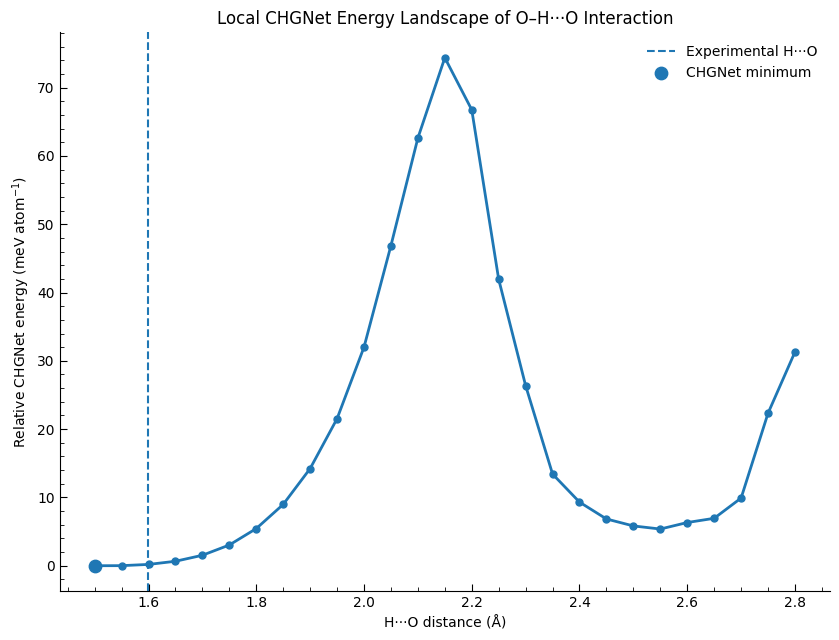


Saved:
  CHGNet_Local_OH_O_Energy_Landscape.csv
  Figure_CHGNet_Local_OH_O_Energy_Landscape.png
  Figure_CHGNet_Local_OH_O_Energy_Landscape.pdf

CELL 26 COMPLETE


In [95]:
# ============================================================
# CELL 26 — LOCAL CHGNet O–H···O ENERGY LANDSCAPE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from pymatgen.core import Structure

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("LOCAL CHGNet O–H···O ENERGY LANDSCAPE")
print("=" * 90)

# ------------------------------------------------------------
# Target atoms
# ------------------------------------------------------------

donor = 364
hydrogen = 12
acceptor = 380

print("\nTarget interaction:")
print(f"O{donor}–H{hydrogen}···O{acceptor}")

# ------------------------------------------------------------
# Original coordinates
# ------------------------------------------------------------

O_donor_pos = structure_exp[donor].coords.copy()
H_pos = structure_exp[hydrogen].coords.copy()
O_acc_pos = structure_exp[acceptor].coords.copy()

# Vector from H toward Acceptor O
H_to_O = O_acc_pos - H_pos
H_to_O_unit = H_to_O / np.linalg.norm(H_to_O)

# Original O-H distance
OH_original = np.linalg.norm(
    H_pos - O_donor_pos
)

# ------------------------------------------------------------
# Target H···O distances
# ------------------------------------------------------------

target_distances = np.arange(
    1.50,
    2.81,
    0.05
)

print(
    f"\nNumber of scan points : "
    f"{len(target_distances)}"
)

print(
    f"Scan range            : "
    f"{target_distances.min():.2f}–"
    f"{target_distances.max():.2f} Å"
)

# ------------------------------------------------------------
# CHGNet model
# ------------------------------------------------------------

from chgnet.model.model import CHGNet

print("\nLoading CHGNet...")

local_chgnet = CHGNet.load(
    use_device="cuda",
    verbose=True
)

print("CHGNet loaded successfully.")

# ------------------------------------------------------------
# Energy scan
# ------------------------------------------------------------

results = []

print("\nRunning energy scan...")
print("-" * 90)

for i, target_HO in enumerate(target_distances):

    # --------------------------------------------------------
    # Place H at the desired H···O distance.
    #
    # H is positioned along the original H→O direction.
    # --------------------------------------------------------

    new_H_pos = O_acc_pos - (
        H_to_O_unit * target_HO
    )

    # Preserve the original crystal
    test_structure = structure_exp.copy()

    # Replace only the hydrogen coordinate
    test_structure.replace(
        hydrogen,
        "H",
        new_H_pos,
        coords_are_cartesian=True
    )

    # --------------------------------------------------------
    # CHGNet prediction
    # --------------------------------------------------------

    prediction = local_chgnet.predict_structure(
        test_structure,
        task="ef"
    )

    energy = float(
        np.asarray(
            prediction["e"]
        ).reshape(-1)[0]
    )

    forces = np.asarray(
        prediction["f"]
    )

    max_force = float(
        np.max(
            np.linalg.norm(
                forces,
                axis=1
            )
        )
    )

    # Actual geometry after placement
    actual_HO = np.linalg.norm(
        test_structure[hydrogen].coords -
        test_structure[acceptor].coords
    )

    actual_OH = np.linalg.norm(
        test_structure[hydrogen].coords -
        test_structure[donor].coords
    )

    actual_OO = np.linalg.norm(
        test_structure[donor].coords -
        test_structure[acceptor].coords
    )

    # O-H-O angle
    v1 = (
        test_structure[donor].coords -
        test_structure[hydrogen].coords
    )

    v2 = (
        test_structure[acceptor].coords -
        test_structure[hydrogen].coords
    )

    cos_angle = np.dot(v1, v2) / (
        np.linalg.norm(v1) *
        np.linalg.norm(v2)
    )

    cos_angle = np.clip(
        cos_angle,
        -1.0,
        1.0
    )

    angle = np.degrees(
        np.arccos(cos_angle)
    )

    results.append({
        "Target_HO_A": target_HO,
        "Actual_HO_A": actual_HO,
        "OH_A": actual_OH,
        "OO_A": actual_OO,
        "OHO_angle_deg": angle,
        "CHGNet_energy_eV_per_atom": energy,
        "Maximum_force_eV_per_A": max_force
    })

    print(
        f"{i+1:2d}/{len(target_distances)}  "
        f"H···O = {actual_HO:.3f} Å   "
        f"E = {energy:.8f} eV/atom   "
        f"Fmax = {max_force:.4f} eV/Å"
    )

# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

hbond_energy_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Relative energy
# ------------------------------------------------------------

minimum_energy = (
    hbond_energy_df[
        "CHGNet_energy_eV_per_atom"
    ].min()
)

hbond_energy_df[
    "Relative_energy_meV_per_atom"
] = (
    hbond_energy_df[
        "CHGNet_energy_eV_per_atom"
    ] -
    minimum_energy
) * 1000.0

# ------------------------------------------------------------
# Experimental point
# ------------------------------------------------------------

experimental_HO = np.linalg.norm(
    structure_exp[hydrogen].coords -
    structure_exp[acceptor].coords
)

experimental_energy_row = hbond_energy_df.iloc[
    np.argmin(
        np.abs(
            hbond_energy_df[
                "Actual_HO_A"
            ].values -
            experimental_HO
        )
    )
]

# ------------------------------------------------------------
# Minimum
# ------------------------------------------------------------

minimum_row = hbond_energy_df.loc[
    hbond_energy_df[
        "CHGNet_energy_eV_per_atom"
    ].idxmin()
]

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "CHGNet_Local_OH_O_Energy_Landscape.csv"
)

hbond_energy_df.to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# Print key results
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("LOCAL ENERGY LANDSCAPE SUMMARY")
print("=" * 90)

print(
    f"Minimum CHGNet energy      : "
    f"{minimum_row['CHGNet_energy_eV_per_atom']:.8f} eV/atom"
)

print(
    f"Minimum H···O distance      : "
    f"{minimum_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Experimental H···O distance : "
    f"{experimental_HO:.4f} Å"
)

print(
    f"Nearest scan point to exp.  : "
    f"{experimental_energy_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Relative energy at nearest "
    f"experimental point         : "
    f"{experimental_energy_row['Relative_energy_meV_per_atom']:.4f} meV/atom"
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.5, 6.5)
)

ax.plot(
    hbond_energy_df["Actual_HO_A"],
    hbond_energy_df[
        "Relative_energy_meV_per_atom"
    ],
    marker="o",
    linewidth=2.0,
    markersize=5
)

ax.axvline(
    experimental_HO,
    linestyle="--",
    linewidth=1.5,
    label="Experimental H···O"
)

ax.scatter(
    minimum_row["Actual_HO_A"],
    minimum_row[
        "Relative_energy_meV_per_atom"
    ],
    s=80,
    zorder=5,
    label="CHGNet minimum"
)

ax.set_xlabel(
    "H···O distance (Å)"
)

ax.set_ylabel(
    "Relative CHGNet energy (meV atom$^{-1}$)"
)

ax.set_title(
    "Local CHGNet Energy Landscape of O–H···O Interaction"
)

ax.legend(
    frameon=False
)

ax.minorticks_on()

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

png_path = os.path.join(
    output_dir,
    "Figure_CHGNet_Local_OH_O_Energy_Landscape.png"
)

pdf_path = os.path.join(
    output_dir,
    "Figure_CHGNet_Local_OH_O_Energy_Landscape.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved:")
print("  CHGNet_Local_OH_O_Energy_Landscape.csv")
print("  Figure_CHGNet_Local_OH_O_Energy_Landscape.png")
print("  Figure_CHGNet_Local_OH_O_Energy_Landscape.pdf")

print("\n" + "=" * 90)
print("CELL 26 COMPLETE")
print("=" * 90)

In [107]:
# ============================================================
# CELL 27A — FIND EXPERIMENTAL CIF
# ============================================================

import os

print("=" * 90)
print("SEARCHING FOR EXPERIMENTAL CIF FILE")
print("=" * 90)

search_locations = [
    "/content",
    "/content/drive/MyDrive",
]

found_files = []

for search_location in search_locations:

    if not os.path.exists(search_location):
        continue

    for root, dirs, files in os.walk(search_location):

        # Avoid searching extremely large system directories
        if root.count(os.sep) > 8:
            continue

        for filename in files:
            if filename.lower().endswith(".cif"):
                full_path = os.path.join(
                    root,
                    filename
                )
                found_files.append(
                    full_path
                )

print("\nCIF files found:")

if len(found_files) == 0:
    print("NO CIF FILE FOUND.")
else:
    for i, filepath in enumerate(
        found_files,
        start=1
    ):
        print(
            f"{i}. {filepath}"
        )

print(
    "\nTotal CIF files found:",
    len(found_files)
)

print("\n" + "=" * 90)
print("CELL 27A COMPLETE")
print("=" * 90)

SEARCHING FOR EXPERIMENTAL CIF FILE

CIF files found:
1. /content/CHGNet_relaxed.cif
2. /content/cocrystal_MD_final_300K.cif
3. /content/1544195.cif
4. /content/drive/MyDrive/Colab Notebooks/1544195_CBZ–NIC (nicotinamide).cif
5. /content/drive/MyDrive/Colab Notebooks/1544195_CBZ–NIC (nicotinamide).cif

Total CIF files found: 5

CELL 27A COMPLETE


In [97]:
# ============================================================
# CELL 27B — MOUNT GOOGLE DRIVE AND SEARCH FOR CIF
# ============================================================

from google.colab import drive
import os

print("=" * 90)
print("MOUNTING GOOGLE DRIVE")
print("=" * 90)

drive.mount("/content/drive")

print("\nSearching Google Drive for CIF files...")

found_cifs = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for filename in files:
        if filename.lower().endswith(".cif"):
            full_path = os.path.join(root, filename)
            found_cifs.append(full_path)

print("\n" + "=" * 90)
print("CIF FILES FOUND")
print("=" * 90)

if len(found_cifs) == 0:
    print("NO CIF FILES FOUND IN GOOGLE DRIVE.")
else:
    for i, filepath in enumerate(found_cifs, start=1):
        print(f"{i}. {filepath}")

print("\nTotal CIF files found:", len(found_cifs))

print("\n" + "=" * 90)
print("CELL 27B COMPLETE")
print("=" * 90)

MOUNTING GOOGLE DRIVE
Mounted at /content/drive

Searching Google Drive for CIF files...

CIF FILES FOUND
1. /content/drive/MyDrive/Colab Notebooks/1562073_CBZ–SAC.cif
2. /content/drive/MyDrive/Colab Notebooks/1544195_CBZ–NIC (nicotinamide).cif

Total CIF files found: 2

CELL 27B COMPLETE


In [98]:
# ============================================================
# CELL 27C — LIST AND SELECT CIF FILE
# ============================================================

import os
import glob

print("=" * 80)
print("CIF FILES FOUND IN GOOGLE DRIVE")
print("=" * 80)

# Search Google Drive for CIF files
cif_files = glob.glob(
    "/content/drive/MyDrive/**/*.cif",
    recursive=True
)

if len(cif_files) == 0:
    print("\n❌ No CIF files were found.")
    print("Please check that your CIF file is actually uploaded to Google Drive.")
else:
    print(f"\nFound {len(cif_files)} CIF file(s):\n")

    for i, file in enumerate(cif_files, start=1):
        print(f"{i}. {file}")

print("\n" + "=" * 80)

CIF FILES FOUND IN GOOGLE DRIVE

Found 2 CIF file(s):

1. /content/drive/MyDrive/Colab Notebooks/1562073_CBZ–SAC.cif
2. /content/drive/MyDrive/Colab Notebooks/1544195_CBZ–NIC (nicotinamide).cif



In [99]:
# ============================================================
# CELL 28 — LOAD AND VERIFY SELECTED EXPERIMENTAL CIF
# ============================================================

from pymatgen.core import Structure
from pymatgen.io.ase import AseAtomsAdaptor
import os

print("=" * 90)
print("STEP 28 — LOAD AND VERIFY SELECTED EXPERIMENTAL CIF")
print("=" * 90)

# ------------------------------------------------------------
# 1. Define CIF path from CELL 27A
# ------------------------------------------------------------

selected_cif = "/content/1544195.cif"

if not os.path.exists(selected_cif):
    raise FileNotFoundError(
        f"CIF file not found:\n{selected_cif}"
    )

print(f"\nCIF file:")
print(selected_cif)

# ------------------------------------------------------------
# 2. Load CIF
# ------------------------------------------------------------

structure_target = Structure.from_file(selected_cif)

print("\nCIF loaded successfully.")

# ------------------------------------------------------------
# 3. Basic structural information
# ------------------------------------------------------------

print("\nReduced formula:")
print(structure_target.composition.reduced_formula)

print("\nNumber of atoms:")
print(len(structure_target))

print("\nLattice parameters:")
print(f"a      = {structure_target.lattice.a:.6f} Å")
print(f"b      = {structure_target.lattice.b:.6f} Å")
print(f"c      = {structure_target.lattice.c:.6f} Å")
print(f"alpha  = {structure_target.lattice.alpha:.6f}°")
print(f"beta   = {structure_target.lattice.beta:.6f}°")
print(f"gamma  = {structure_target.lattice.gamma:.6f}°")
print(f"Volume = {structure_target.volume:.6f} Å³")

# ------------------------------------------------------------
# 4. Convert to ASE
# ------------------------------------------------------------

atoms_target = AseAtomsAdaptor.get_atoms(structure_target)

print("\nASE structure:")
print(atoms_target)

print(f"\nNumber of ASE atoms: {len(atoms_target)}")

# ------------------------------------------------------------
# 5. Periodic boundary conditions
# ------------------------------------------------------------

print("\nPeriodic boundary conditions:")
print(atoms_target.pbc)

# ------------------------------------------------------------
# 6. Atomic species
# ------------------------------------------------------------

unique_species = sorted(
    set(str(site.specie) for site in structure_target)
)

print("\nUnique atomic species:")
print(unique_species)

print("\nAtomic composition:")
for element, amount in structure_target.composition.get_el_amt_dict().items():
    print(f"{element:>3s} : {amount}")

print("\n" + "=" * 90)
print("CIF VERIFICATION COMPLETED")
print("=" * 90)

STEP 28 — LOAD AND VERIFY SELECTED EXPERIMENTAL CIF

CIF file:
/content/1544195.cif

CIF loaded successfully.

Reduced formula:
H19C22N3O4

Number of atoms:
384

Lattice parameters:
a      = 27.427000 Å
b      = 7.640200 Å
c      = 21.038000 Å
alpha  = 90.000000°
beta   = 119.263000°
gamma  = 90.000000°
Volume = 3845.880043 Å³

ASE structure:
MSONAtoms(symbols='C176H152N24O32', pbc=True, cell=[[23.926906685487953, 0.0, -13.406843978504106], [1.2286378668059438e-15, 7.6402, 4.678273237422804e-16], [0.0, 0.0, 21.038]])

Number of ASE atoms: 384

Periodic boundary conditions:
[ True  True  True]

Unique atomic species:
['C', 'H', 'N', 'O']

Atomic composition:
  H : 152.0
  C : 176.0
  N : 24.0
  O : 32.0

CIF VERIFICATION COMPLETED


/usr/local/lib/python3.13/dist-packages/pymatgen/core/composition.py:1372: FutureWarning: gcd is deprecated, and will be removed on 2028-01-01
Use math.gcd instead.
  factor = abs(gcd(*(int(i) for i in sym_amt.values())))


In [100]:
# ============================================================
# CELL 29 — VERIFY TARGET O–H···O ATOMS AND DISTANCES
# ============================================================

import numpy as np

print("=" * 90)
print("STEP 29 — VERIFY TARGET O–H···O INTERACTION")
print("=" * 90)

# Target atoms from experimental structure
target_atoms = {
    "O364": 364,
    "H12": 12,
    "O380": 380
}

print("\nTarget atoms:")
for label, index in target_atoms.items():
    atom = atoms_target[index]
    print(
        f"{label:>4s}  index = {index:3d}  "
        f"element = {atom.symbol:>2s}  "
        f"position = [{atom.position[0]:.6f}, "
        f"{atom.position[1]:.6f}, "
        f"{atom.position[2]:.6f}] Å"
    )

# ------------------------------------------------------------
# Verify atomic identities
# ------------------------------------------------------------

expected_elements = {
    "O364": "O",
    "H12": "H",
    "O380": "O"
}

for label, expected in expected_elements.items():
    index = target_atoms[label]
    actual = atoms_target[index].symbol

    if actual != expected:
        raise ValueError(
            f"{label} is expected to be {expected}, "
            f"but atom index {index} is {actual}."
        )

print("\n✓ Atomic identities verified.")

# ------------------------------------------------------------
# Calculate direct Cartesian distances
# ------------------------------------------------------------

O_donor_pos = atoms_target[364].position
H_pos = atoms_target[12].position
O_acc_pos = atoms_target[380].position

OH_distance = np.linalg.norm(O_donor_pos - H_pos)
HO_distance = np.linalg.norm(H_pos - O_acc_pos)
OO_distance = np.linalg.norm(O_donor_pos - O_acc_pos)

print("\nDirect Cartesian distances:")
print(f"O364–H12    = {OH_distance:.6f} Å")
print(f"H12···O380  = {HO_distance:.6f} Å")
print(f"O364···O380 = {OO_distance:.6f} Å")

# ------------------------------------------------------------
# Minimum-image / periodic distances
# ------------------------------------------------------------

from ase.geometry import find_mic

cell = atoms_target.cell.array
pbc = atoms_target.pbc

OH_vec = H_pos - O_donor_pos
HO_vec = O_acc_pos - H_pos
OO_vec = O_acc_pos - O_donor_pos

OH_mic, OH_len = find_mic(OH_vec, cell, pbc=pbc)
HO_mic, HO_len = find_mic(HO_vec, cell, pbc=pbc)
OO_mic, OO_len = find_mic(OO_vec, cell, pbc=pbc)

print("\nMinimum-image distances:")
print(f"O364–H12    = {float(OH_len):.6f} Å")
print(f"H12···O380  = {float(HO_len):.6f} Å")
print(f"O364···O380 = {float(OO_len):.6f} Å")

print("\n" + "=" * 90)
print("TARGET INTERACTION VERIFICATION COMPLETED")
print("=" * 90)

STEP 29 — VERIFY TARGET O–H···O INTERACTION

Target atoms:
O364  index = 364  element =  O  position = [11.777063, 5.568636, 2.758299] Å
 H12  index =  12  element =  H  position = [12.341498, 4.820966, 2.535019] Å
O380  index = 380  element =  O  position = [13.531144, 3.825601, 2.143608] Å

✓ Atomic identities verified.

Direct Cartesian distances:
O364–H12    = 0.963043 Å
H12···O380  = 1.599754 Å
O364···O380 = 2.548101 Å

Minimum-image distances:
O364–H12    = 0.963043 Å
H12···O380  = 1.599754 Å
O364···O380 = 2.548101 Å

TARGET INTERACTION VERIFICATION COMPLETED


In [101]:
# ============================================================
# CELL 30 — DEFINE O–H···O SCAN PARAMETERS
# ============================================================

import numpy as np

print("=" * 90)
print("STEP 30 — DEFINE LOCAL O–H···O ENERGY SCAN")
print("=" * 90)

# Target interaction
O_DONOR_INDEX = 364  # O364
H_INDEX = 12         # H12
O_ACC_INDEX = 380    # O380

# Experimental and current H···O distances
EXPERIMENTAL_HO = 1.6880
CURRENT_HO = HO_len

# Fine scan range around the experimental distance
SCAN_START = 1.45
SCAN_END = 1.75
N_POINTS = 23

scan_distances = np.linspace(
    SCAN_START,
    SCAN_END,
    N_POINTS
)

print("\nTarget interaction:")
print("O364–H12···O380")

print("\nCurrent geometry:")
print(f"O364–H12       = {OH_len:.6f} Å")
print(f"H12···O380     = {CURRENT_HO:.6f} Å")
print(f"O364···O380    = {OO_len:.6f} Å")

print("\nExperimental H···O distance:")
print(f"{EXPERIMENTAL_HO:.4f} Å")

print("\nScan parameters:")
print(f"Start distance = {SCAN_START:.2f} Å")
print(f"End distance   = {SCAN_END:.2f} Å")
print(f"Scan points    = {N_POINTS}")

print("\nScan distances:")
print(", ".join(f"{d:.3f}" for d in scan_distances))

print("\n" + "=" * 90)
print("SCAN PARAMETERS DEFINED SUCCESSFULLY")
print("=" * 90)

STEP 30 — DEFINE LOCAL O–H···O ENERGY SCAN

Target interaction:
O364–H12···O380

Current geometry:
O364–H12       = 0.963043 Å
H12···O380     = 1.599754 Å
O364···O380    = 2.548101 Å

Experimental H···O distance:
1.6880 Å

Scan parameters:
Start distance = 1.45 Å
End distance   = 1.75 Å
Scan points    = 23

Scan distances:
1.450, 1.464, 1.477, 1.491, 1.505, 1.518, 1.532, 1.545, 1.559, 1.573, 1.586, 1.600, 1.614, 1.627, 1.641, 1.655, 1.668, 1.682, 1.695, 1.709, 1.723, 1.736, 1.750

SCAN PARAMETERS DEFINED SUCCESSFULLY


In [102]:
# ==========================================================================================
# STEP 31 — RUN LOCAL O–H···O CHGNet ENERGY SCAN
# CORRECTED ASE → pymatgen CONVERSION
# ==========================================================================================

import numpy as np
import pandas as pd
from pymatgen.io.ase import AseAtomsAdaptor
from chgnet.model import CHGNet

print("=" * 90)
print("STEP 31 — RUN LOCAL O–H···O CHGNet ENERGY SCAN")
print("=" * 90)

# ------------------------------------------------------------------------------------------
# ATOM INDICES (0-indexed for ASE)
# ------------------------------------------------------------------------------------------

O_donor_atom = 364  # O364
H_atom = 12         # H12
O_acc_atom = 380    # O380

O_donor_idx = O_donor_atom
H_idx = H_atom
O_acc_idx = O_acc_atom

# ------------------------------------------------------------------------------------------
# SCAN PARAMETERS
# ------------------------------------------------------------------------------------------

start_distance = 1.45
end_distance   = 1.75
n_points       = 23

experimental_distance = 1.6880

scan_distances = np.linspace(
    start_distance,
    end_distance,
    n_points
)

print(f"\nTarget interaction : O{O_donor_atom}–H{H_atom}···O{O_acc_atom}")
print(f"Experimental H···O : {experimental_distance:.4f} Å")
print(f"Scan range         : {start_distance:.2f}–{end_distance:.2f} Å")
print(f"Number of points   : {n_points}")

# ------------------------------------------------------------------------------------------
# CHECK STRUCTURE
# ------------------------------------------------------------------------------------------

print("\nChecking input structure...")

if len(atoms_target) != 384:
    raise ValueError(
        f"Expected 384 atoms, but the current structure contains {len(atoms_target)} atoms."
    )

print(f"Structure contains {len(atoms_target)} atoms.")

# Use atoms_target from earlier steps
atoms = atoms_target.copy()

# ------------------------------------------------------------------------------------------
# CHECK CURRENT H···O DISTANCE
# ------------------------------------------------------------------------------------------

positions = atoms.get_positions()

current_HO = np.linalg.norm(
    positions[H_idx] - positions[O_acc_idx]
)

print(f"Current H···O distance = {current_HO:.6f} Å")

# ------------------------------------------------------------------------------------------
# LOAD CHGNet
# ------------------------------------------------------------------------------------------

print("\nLoading CHGNet...")

model = CHGNet.load(use_device="cuda", verbose=True)

print("CHGNet loaded successfully.")

# ------------------------------------------------------------------------------------------
# FUNCTION TO SET H···O DISTANCE
# ------------------------------------------------------------------------------------------

def set_HO_distance(atoms_in, target_distance):

    new_atoms = atoms_in.copy()
    positions = new_atoms.get_positions().copy()

    H_pos = positions[H_idx]
    O_acc_pos = positions[O_acc_idx]

    HO_vector = O_acc_pos - H_pos
    current_distance = np.linalg.norm(HO_vector)

    if current_distance == 0:
        raise ValueError("Current H···O distance is zero.")

    HO_unit = HO_vector / current_distance

    # Keep H fixed and move Acceptor O along the existing H→O direction
    positions[O_acc_idx] = H_pos + target_distance * HO_unit

    new_atoms.set_positions(positions)

    return new_atoms


# ------------------------------------------------------------------------------------------
# FUNCTION FOR CHGNet ENERGY
# ------------------------------------------------------------------------------------------

def calculate_chgnet_energy(ase_atoms):

    # Convert ASE Atoms → pymatgen Structure
    structure = AseAtomsAdaptor.get_structure(ase_atoms)

    # CHGNet prediction
    prediction = model.predict_structure(structure, task="ef")

    # Energy returned by CHGNet
    energy_per_atom = float(prediction["e"])
    total_energy = energy_per_atom * len(structure)

    return total_energy, energy_per_atom


# ------------------------------------------------------------------------------------------
# RUN 23-POINT SCAN
# ------------------------------------------------------------------------------------------

results = []

print("\n" + "=" * 90)
print("STARTING 23-POINT CHGNet ENERGY SCAN")
print("=" * 90)

for i, target_distance in enumerate(scan_distances, start=1):

    # Generate scan geometry
    scan_atoms = set_HO_distance(
        atoms,
        target_distance
    )

    # Verify actual distance
    scan_positions = scan_atoms.get_positions()

    actual_distance = np.linalg.norm(
        scan_positions[H_idx] - scan_positions[O_acc_idx]
    )

    # Calculate CHGNet energy
    total_energy, energy_per_atom = calculate_chgnet_energy(
        scan_atoms
    )

    # Store results
    results.append({
        "Point": i,
        "Target_HO_A": target_distance,
        "Actual_HO_A": actual_distance,
        "Energy_eV": total_energy,
        "Energy_eV_per_atom": energy_per_atom
    })

    print(
        f"{i:02d}/23 | "
        f"H···O = {actual_distance:.4f} Å | "
        f"E = {total_energy:.8f} eV"
    )


# ------------------------------------------------------------------------------------------
# DATAFRAME
# ------------------------------------------------------------------------------------------

results_df = pd.DataFrame(results)

# ------------------------------------------------------------------------------------------
# RELATIVE ENERGY
# ------------------------------------------------------------------------------------------

minimum_energy = results_df["Energy_eV"].min()

results_df["Delta_E_eV"] = (
    results_df["Energy_eV"] - minimum_energy
)

results_df["Delta_E_kJ_mol"] = (
    results_df["Delta_E_eV"] * 96.48533212
)

results_df["Delta_E_kcal_mol"] = (
    results_df["Delta_E_eV"] * 23.06054783
)

# ------------------------------------------------------------------------------------------
# FIND MINIMUM
# ------------------------------------------------------------------------------------------

minimum_index = results_df["Energy_eV"].idxmin()
minimum_row = results_df.loc[minimum_index]
minimum_distance = minimum_row["Actual_HO_A"]

# ------------------------------------------------------------------------------------------
# CLOSEST POINT TO EXPERIMENTAL DISTANCE
# ------------------------------------------------------------------------------------------

experimental_index = (
    results_df["Actual_HO_A"] - experimental_distance
).abs().idxmin()

experimental_row = results_df.loc[experimental_index]

# ------------------------------------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------------------------------------

print("\n" + "=" * 90)
print("ENERGY SCAN COMPLETED SUCCESSFULLY")
print("=" * 90)

print(
    f"\nMinimum-energy H···O distance : "
    f"{minimum_distance:.4f} Å"
)

print(
    f"Minimum CHGNet energy          : "
    f"{minimum_row['Energy_eV']:.8f} eV"
)

print(
    f"\nExperimental H···O distance    : "
    f"{experimental_distance:.4f} Å"
)

print(
    f"Closest scan point              : "
    f"{experimental_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Relative energy at closest point: "
    f"{experimental_row['Delta_E_kJ_mol']:.6f} kJ/mol"
)

print("\nComplete results:")
display(results_df)

# ------------------------------------------------------------------------------------------
# SAVE CSV
# ------------------------------------------------------------------------------------------

output_file = "O364_H12_O380_CHGNet_energy_scan.csv"

results_df.to_csv(
    output_file,
    index=False
)

print(f"\nResults saved as: {output_file}")
print("=" * 90)

STEP 31 — RUN LOCAL O–H···O CHGNet ENERGY SCAN

Target interaction : O364–H12···O380
Experimental H···O : 1.6880 Å
Scan range         : 1.45–1.75 Å
Number of points   : 23

Checking input structure...
Structure contains 384 atoms.
Current H···O distance = 1.599754 Å

Loading CHGNet...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda
CHGNet loaded successfully.

STARTING 23-POINT CHGNet ENERGY SCAN
01/23 | H···O = 1.4500 Å | E = -2542.79827881 eV
02/23 | H···O = 1.4636 Å | E = -2542.84167480 eV
03/23 | H···O = 1.4773 Å | E = -2542.88104248 eV
04/23 | H···O = 1.4909 Å | E = -2542.91674805 eV
05/23 | H···O = 1.5045 Å | E = -2542.94805908 eV
06/23 | H···O = 1.5182 Å | E = -2542.97479248 eV
07/23 | H···O = 1.5318 Å | E = -2542.99713135 eV
08/23 | H···O = 1.5455 Å | E = -2543.01525879 eV
09/23 | H···O = 1.5591 Å | E = -2543.02844238 eV
10/23 | H···O = 1.5727 Å | E = -2543.03668213 eV
11/23 | H···O = 1.5864 Å | E = -2543.03997803 eV
12/23 | H···O = 1.6000 Å | E = -254

,Point,Target_HO_A,Actual_HO_A,Energy_eV,Energy_eV_per_atom,Delta_E_eV,Delta_E_kJ_mol,Delta_E_kcal_mol
0,1,1.450000,1.450000,-2542.798279,-6.621871,0.241699,23.320429,5.573716
1,2,1.463636,1.463636,-2542.841675,-6.621984,0.198303,19.133352,4.572981
2,3,1.477273,1.477273,-2542.881042,-6.622086,0.158936,15.334949,3.665141
3,4,1.490909,1.490909,-2542.916748,-6.622179,0.123230,11.889886,2.841751
4,5,1.504545,1.504545,-2542.948059,-6.622261,0.091919,8.868830,2.119701
5,6,1.518182,1.518182,-2542.974792,-6.622330,0.065186,6.289449,1.503214
6,7,1.531818,1.531818,-2542.997131,-6.622388,0.042847,4.134076,0.988068
7,8,1.545455,1.545455,-2543.015259,-6.622436,0.024719,2.385044,0.570039
8,9,1.559091,1.559091,-2543.028442,-6.622470,0.011536,1.113020,0.266018
9,10,1.572727,1.572727,-2543.036682,-6.622491,0.003296,0.318006,0.076005



Results saved as: O364_H12_O380_CHGNet_energy_scan.csv


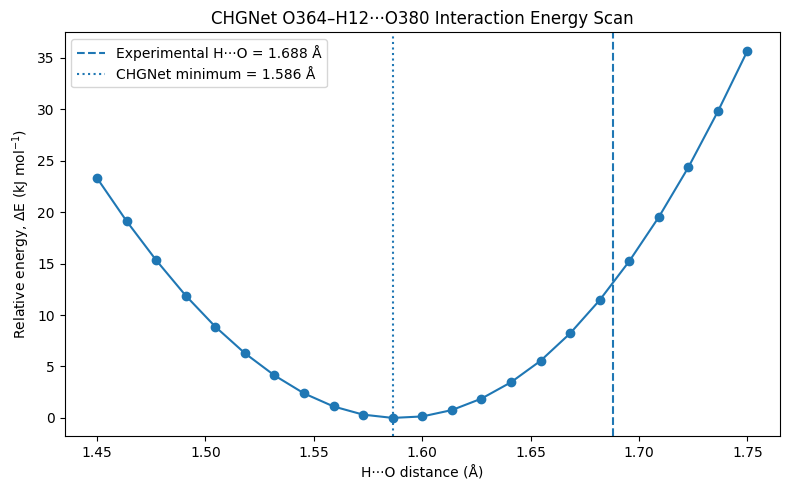

In [103]:
# ==========================================================================================
# STEP 32 — PLOT O–H···O CHGNet ENERGY PROFILE
# ==========================================================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Actual_HO_A"],
    results_df["Delta_E_kJ_mol"],
    marker="o"
)

# Experimental H···O distance
plt.axvline(
    experimental_distance,
    linestyle="--",
    label=f"Experimental H···O = {experimental_distance:.3f} Å"
)

# Minimum-energy distance
plt.axvline(
    minimum_distance,
    linestyle=":",
    label=f"CHGNet minimum = {minimum_distance:.3f} Å"
)

plt.xlabel("H···O distance (Å)")
plt.ylabel("Relative energy, ΔE (kJ mol$^{-1}$)")
plt.title("CHGNet O364–H12···O380 Interaction Energy Scan")

plt.legend()
plt.tight_layout()

plt.show()

In [104]:
# ==========================================================================================
# STEP 33 — EXTRACT KEY ENERGY-SCAN PARAMETERS
# ==========================================================================================

print("=" * 90)
print("KEY RESULTS — O364–H12···O380")
print("=" * 90)

print(f"Experimental H···O distance : {experimental_distance:.4f} Å")
print(f"CHGNet minimum distance     : {minimum_distance:.4f} Å")

print(
    f"Minimum energy              : "
    f"{minimum_row['Energy_eV']:.8f} eV"
)

print(
    f"Energy at closest experimental point "
    f"({experimental_row['Actual_HO_A']:.4f} Å): "
    f"{experimental_row['Delta_E_eV']:.8f} eV"
)

print(
    f"Relative energy             : "
    f"{experimental_row['Delta_E_kJ_mol']:.4f} kJ/mol"
)

print("=" * 90)

KEY RESULTS — O364–H12···O380
Experimental H···O distance : 1.6880 Å
CHGNet minimum distance     : 1.5864 Å
Minimum energy              : -2543.03997803 eV
Energy at closest experimental point (1.6818 Å): 0.11865234 eV
Relative energy             : 11.4482 kJ/mol


VALIDATION OF O364–H12···O380 INTERACTION
Current computational H···O distance : 1.5998 Å
CHGNet scan minimum                  : 1.5864 Å
Experimental H···O distance          : 1.6880 Å
--------------------------------------------------------------------------------
Distance differences:
Experimental − CHGNet minimum        : +0.1016 Å
Current − CHGNet minimum             : +0.0134 Å
--------------------------------------------------------------------------------
Energy relative to CHGNet minimum:
At current computational distance (1.60 Å): 0.1413 kJ mol⁻¹
At experimental distance (1.68 Å): 11.4482 kJ mol⁻¹


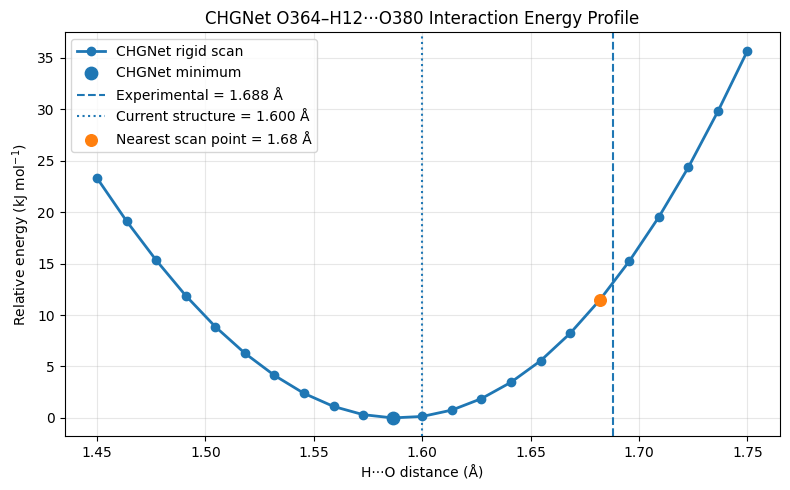

In [108]:
# =============================================================================
# STEP 34 — VALIDATION OF O364–H12···O380 DISTANCES
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 1. Important reference distances
# -------------------------------------------------------------------------

current_distance = atoms.get_distance(H_idx, O_acc_idx)   # Current structure
experimental_distance = 1.6880                            # Experimental crystal value

# -------------------------------------------------------------------------
# 2. Find corresponding scan energies
# -------------------------------------------------------------------------

# CHGNet minimum
min_row = results_df.loc[results_df["Delta_E_eV"].idxmin()]

# Point closest to experimental distance
exp_idx = (results_df["Actual_HO_A"] - experimental_distance).abs().idxmin()
exp_row = results_df.loc[exp_idx]

# Point closest to current computational distance
current_idx = (results_df["Actual_HO_A"] - current_distance).abs().idxmin()
current_row = results_df.loc[current_idx]

# -------------------------------------------------------------------------
# 3. Print validation summary
# -------------------------------------------------------------------------

print("=" * 80)
print("VALIDATION OF O364–H12···O380 INTERACTION")
print("=" * 80)

print(f"Current computational H···O distance : {current_distance:.4f} Å")

print(f"CHGNet scan minimum                  : "
      f"{min_row['Actual_HO_A']:.4f} Å")

print(f"Experimental H···O distance          : "
      f"{experimental_distance:.4f} Å")

print("-" * 80)

print("Distance differences:")
print(f"Experimental − CHGNet minimum        : "
      f"{experimental_distance - min_row['Actual_HO_A']:+.4f} Å")

print(f"Current − CHGNet minimum             : "
      f"{current_distance - min_row['Actual_HO_A']:+.4f} Å")

print("-" * 80)

print("Energy relative to CHGNet minimum:")

print(f"At current computational distance "
      f"({current_row['Actual_HO_A']:.2f} Å): "
      f"{current_row['Delta_E_kJ_mol']:.4f} kJ mol⁻¹")

print(f"At experimental distance "
      f"({exp_row['Actual_HO_A']:.2f} Å): "
      f"{exp_row['Delta_E_kJ_mol']:.4f} kJ mol⁻¹")

print("=" * 80)

# -------------------------------------------------------------------------
# 4. Plot the energy profile
# -------------------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Actual_HO_A"],
    results_df["Delta_E_kJ_mol"],
    marker="o",
    linewidth=2,
    label="CHGNet rigid scan"
)

# CHGNet minimum
plt.scatter(
    min_row["Actual_HO_A"],
    min_row["Delta_E_kJ_mol"],
    s=80,
    zorder=5,
    label="CHGNet minimum"
)

# Experimental distance
plt.axvline(
    experimental_distance,
    linestyle="--",
    linewidth=1.5,
    label=f"Experimental = {experimental_distance:.3f} Å"
)

# Current computational distance
plt.axvline(
    current_distance,
    linestyle=":",
    linewidth=1.5,
    label=f"Current structure = {current_distance:.3f} Å"
)

# Mark experimental nearest scan point
plt.scatter(
    exp_row["Actual_HO_A"],
    exp_row["Delta_E_kJ_mol"],
    s=70,
    zorder=5,
    label=f"Nearest scan point = {exp_row['Actual_HO_A']:.2f} Å"
)

plt.xlabel("H···O distance (Å)")
plt.ylabel("Relative energy (kJ mol$^{-1}$)")
plt.title("CHGNet O364–H12···O380 Interaction Energy Profile")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [109]:
# =============================================================================
# STEP 35 — FINE CHGNet O364–H12···O380 ENERGY SCAN
# =============================================================================

import numpy as np
import pandas as pd
from ase.io import write
from pymatgen.io.ase import AseAtomsAdaptor

# -------------------------------------------------------------------------
# 1. Define interaction and scan parameters
# -------------------------------------------------------------------------

O_donor_atom = 364
H_atom = 12
O_acc_atom = 380

# ASE indices (0-indexed)
O_donor_idx = O_donor_atom
H_idx = H_atom
O_acc_idx = O_acc_atom

# Fine scan range (centered around the hydrogen bond length)
start_distance = 1.45
end_distance = 1.75
step_size = 0.002

# Generate scan distances
scan_distances = np.round(
    np.arange(start_distance, end_distance + step_size / 2, step_size),
    3
)

experimental_distance = 1.6880
current_distance = atoms.get_distance(H_idx, O_acc_idx)

print("=" * 80)
print("STEP 35 — FINE CHGNet O364–H12···O380 ENERGY SCAN")
print("=" * 80)

print(f"Number of scan points              : {len(scan_distances)}")
print(f"Scan range                         : "
      f"{start_distance:.3f}–{end_distance:.3f} Å")
print(f"Step size                          : {step_size:.3f} Å")
print(f"Current computational H···O        : "
      f"{current_distance:.4f} Å")
print(f"Experimental H···O                 : "
      f"{experimental_distance:.4f} Å")

# -------------------------------------------------------------------------
# 2. Function to set H···O distance
# -------------------------------------------------------------------------

def set_HO_distance(atoms_in, target_distance):
    """
    Create a copy of the structure and move Acceptor O380 along the
    existing H12 -> O380 direction to obtain the requested H···O distance.
    """

    atoms_new = atoms_in.copy()

    H_position = atoms_new.positions[H_idx].copy()
    O_acc_position = atoms_new.positions[O_acc_idx].copy()

    # Existing H -> O vector
    HO_vector = O_acc_position - H_position
    current_HO = np.linalg.norm(HO_vector)

    if current_HO == 0:
        raise ValueError("H···O distance is zero; cannot define direction.")

    # Unit vector along H -> O
    HO_unit = HO_vector / current_HO

    # New Acceptor O position
    atoms_new.positions[O_acc_idx] = (
        H_position + target_distance * HO_unit
    )

    return atoms_new


# -------------------------------------------------------------------------
# 3. CHGNet energy calculation
# -------------------------------------------------------------------------

def calculate_chgnet_energy(ase_atoms):
    """
    Convert ASE Atoms to pymatgen Structure and calculate
    CHGNet energy.
    """

    structure = AseAtomsAdaptor.get_structure(ase_atoms)

    prediction = model.predict_structure(structure, task="ef")

    energy_per_atom = float(prediction["e"])
    total_energy = energy_per_atom * len(structure)

    return total_energy, energy_per_atom


# -------------------------------------------------------------------------
# 4. Run fine scan
# -------------------------------------------------------------------------

fine_results = []

print("\nStarting fine CHGNet scan...")
print("-" * 80)

for i, target_distance in enumerate(scan_distances, start=1):

    # Generate structure at target H···O distance
    scan_atoms = set_HO_distance(
        atoms,
        target_distance
    )

    # Verify actual distance
    actual_distance = scan_atoms.get_distance(
        H_idx,
        O_acc_idx
    )

    # Calculate CHGNet energy
    total_energy, energy_per_atom = calculate_chgnet_energy(
        scan_atoms
    )

    fine_results.append({
        "Point": i,
        "Target_HO_A": target_distance,
        "Actual_HO_A": actual_distance,
        "Energy_eV": total_energy,
        "Energy_eV_per_atom": energy_per_atom
    })

    # Progress display
    if i == 1 or i % 10 == 0 or i == len(scan_distances):
        print(
            f"Point {i:3d}/{len(scan_distances)} | "
            f"H···O = {actual_distance:.4f} Å | "
            f"E = {energy_per_atom:.9f} eV/atom"
        )


# -------------------------------------------------------------------------
# 5. Convert results to DataFrame
# -------------------------------------------------------------------------

fine_results_df = pd.DataFrame(fine_results)

# -------------------------------------------------------------------------
# 6. Calculate relative energies
# -------------------------------------------------------------------------

minimum_index = fine_results_df["Energy_eV"].idxmin()

minimum_energy = fine_results_df.loc[
    minimum_index,
    "Energy_eV"
]

fine_results_df["Delta_E_eV"] = (
    fine_results_df["Energy_eV"] - minimum_energy
)

# Energy conversion factors
EV_TO_KJ_MOL = 96.48533212
EV_TO_KCAL_MOL = 23.06054783

fine_results_df["Delta_E_kJ_mol"] = (
    fine_results_df["Delta_E_eV"] * EV_TO_KJ_MOL
)

fine_results_df["Delta_E_kcal_mol"] = (
    fine_results_df["Delta_E_eV"] * EV_TO_KCAL_MOL
)

# -------------------------------------------------------------------------
# 7. Identify CHGNet minimum
# -------------------------------------------------------------------------

min_row = fine_results_df.loc[
    fine_results_df["Energy_eV"].idxmin()
]

# -------------------------------------------------------------------------
# 8. Find point closest to experimental distance
# -------------------------------------------------------------------------

experimental_index = (
    fine_results_df["Actual_HO_A"] - experimental_distance
).abs().idxmin()

experimental_row = fine_results_df.loc[
    experimental_index
]

# -------------------------------------------------------------------------
# 9. Find point closest to current computational geometry
# -------------------------------------------------------------------------

current_index = (
    fine_results_df["Actual_HO_A"] - current_distance
).abs().idxmin()

current_row = fine_results_df.loc[
    current_index
]

# -------------------------------------------------------------------------
# 10. Print final validation summary
# -------------------------------------------------------------------------

print("\n")
print("=" * 80)
print("FINE SCAN RESULTS")
print("=" * 80)

print(
    f"CHGNet minimum H···O distance : "
    f"{min_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Minimum total energy          : "
    f"{min_row['Energy_eV']:.9f} eV"
)

print(
    f"Minimum energy per atom       : "
    f"{min_row['Energy_eV_per_atom']:.9f} eV/atom"
)

print("-" * 80)

print(
    f"Current computational distance : "
    f"{current_distance:.4f} Å"
)

print(
    f"Nearest fine-scan point        : "
    f"{current_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Relative energy at current "
    f"nearest point                 : "
    f"{current_row['Delta_E_kJ_mol']:.6f} kJ mol⁻¹"
)

print("-" * 80)

print(
    f"Experimental distance         : "
    f"{experimental_distance:.4f} Å"
)

print(
    f"Nearest fine-scan point        : "
    f"{experimental_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Relative energy at experimental "
    f"nearest point                 : "
    f"{experimental_row['Delta_E_kJ_mol']:.6f} kJ mol⁻¹"
)

print("-" * 80)

print(
    f"Experimental − CHGNet minimum : "
    f"{experimental_distance - min_row['Actual_HO_A']:+.4f} Å"
)

print(
    f"Current − CHGNet minimum       : "
    f"{current_distance - min_row['Actual_HO_A']:+.4f} Å"
)

print("=" * 80)


# -------------------------------------------------------------------------
# 11. Display selected results
# -------------------------------------------------------------------------

display_columns = [
    "Point",
    "Actual_HO_A",
    "Energy_eV_per_atom",
    "Delta_E_eV",
    "Delta_E_kJ_mol",
    "Delta_E_kcal_mol"
]

display(
    fine_results_df[display_columns]
)


# -------------------------------------------------------------------------
# 12. Save fine-scan results
# -------------------------------------------------------------------------

output_file = "O364_H12_O380_CHGNet_FINE_energy_scan.csv"

fine_results_df.to_csv(
    output_file,
    index=False
)

print(f"\nFine-scan results saved to: {output_file}")

STEP 35 — FINE CHGNet O364–H12···O380 ENERGY SCAN
Number of scan points              : 151
Scan range                         : 1.450–1.750 Å
Step size                          : 0.002 Å
Current computational H···O        : 1.5998 Å
Experimental H···O                 : 1.6880 Å

Starting fine CHGNet scan...
--------------------------------------------------------------------------------
Point   1/151 | H···O = 1.4500 Å | E = -6.621870518 eV/atom
Point  10/151 | H···O = 1.4680 Å | E = -6.622017384 eV/atom
Point  20/151 | H···O = 1.4880 Å | E = -6.622159958 eV/atom
Point  30/151 | H···O = 1.5080 Å | E = -6.622279167 eV/atom
Point  40/151 | H···O = 1.5280 Å | E = -6.622373104 eV/atom
Point  50/151 | H···O = 1.5480 Å | E = -6.622442722 eV/atom
Point  60/151 | H···O = 1.5680 Å | E = -6.622485638 eV/atom
Point  70/151 | H···O = 1.5880 Å | E = -6.622500420 eV/atom
Point  80/151 | H···O = 1.6080 Å | E = -6.622488022 eV/atom
Point  90/151 | H···O = 1.6280 Å | E = -6.622447491 eV/atom
Point 100/

,Point,Actual_HO_A,Energy_eV_per_atom,Delta_E_eV,Delta_E_kJ_mol,Delta_E_kcal_mol
0,1,1.450,-6.621871,0.241882,23.338096,5.577939
1,2,1.452,-6.621888,0.235291,22.702085,5.425928
2,3,1.454,-6.621905,0.228699,22.066073,5.273918
3,4,1.456,-6.621922,0.222290,21.447728,5.126130
4,5,1.458,-6.621938,0.215881,20.829384,4.978342
...,...,...,...,...,...,...
146,147,1.742,-6.621631,0.333801,32.206926,7.697640
147,148,1.744,-6.621608,0.342773,33.072609,7.904543
148,149,1.746,-6.621584,0.351746,33.938292,8.111446
149,150,1.748,-6.621561,0.360901,34.821641,8.322572



Fine-scan results saved to: O364_H12_O380_CHGNet_FINE_energy_scan.csv


In [110]:
# =============================================================================
# STEP 36 — VALIDATE O364–H12···O380 GEOMETRY AND PBC
# =============================================================================

import numpy as np

print("=" * 80)
print("STEP 36 — STRUCTURAL VALIDATION")
print("=" * 80)

# Atom indices
O_donor_idx = 364
H_idx = 12
O_acc_idx = 380

# -------------------------------------------------------------------------
# 1. Basic atom information
# -------------------------------------------------------------------------

print("\nATOM INFORMATION")
print("-" * 80)

for atom_label, idx in [("O364", O_donor_idx), ("H12", H_idx), ("O380", O_acc_idx)]:
    print(
        f"Atom {atom_label}: "
        f"{atoms[idx].symbol:2s}   "
        f"Cartesian = {atoms.positions[idx]}"
    )

# -------------------------------------------------------------------------
# 2. Direct Cartesian distances
# -------------------------------------------------------------------------

OH = atoms.get_distance(O_donor_idx, H_idx, mic=False)
HO = atoms.get_distance(H_idx, O_acc_idx, mic=False)
OO = atoms.get_distance(O_donor_idx, O_acc_idx, mic=False)

print("\nDIRECT CARTESIAN DISTANCES")
print("-" * 80)

print(f"O364–H12    = {OH:.6f} Å")
print(f"H12···O380  = {HO:.6f} Å")
print(f"O364···O380 = {OO:.6f} Å")

# -------------------------------------------------------------------------
# 3. Minimum-image / periodic distances
# -------------------------------------------------------------------------

print("\nPERIODIC-BOUNDARY-CORRECTED DISTANCES")
print("-" * 80)

try:
    OH_pbc = atoms.get_distance(O_donor_idx, H_idx, mic=True)
    HO_pbc = atoms.get_distance(H_idx, O_acc_idx, mic=True)
    OO_pbc = atoms.get_distance(O_donor_idx, O_acc_idx, mic=True)

    print(f"O364–H12    = {OH_pbc:.6f} Å")
    print(f"H12···O380  = {HO_pbc:.6f} Å")
    print(f"O364···O380 = {OO_pbc:.6f} Å")

except Exception as e:
    print("PBC distance calculation unavailable:", e)

# -------------------------------------------------------------------------
# 4. Compare current geometry with experiment
# -------------------------------------------------------------------------

experimental_HO = 1.6880

print("\nCOMPARISON WITH EXPERIMENT")
print("-" * 80)

print(f"Experimental H···O = {experimental_HO:.4f} Å")
print(f"Current H···O      = {HO:.4f} Å")

print(
    f"Difference         = "
    f"{HO - experimental_HO:+.4f} Å"
)

print(
    f"Absolute difference = "
    f"{abs(HO - experimental_HO):.4f} Å"
)

# -------------------------------------------------------------------------
# 5. Cell information
# -------------------------------------------------------------------------

print("\nCELL INFORMATION")
print("-" * 80)

if atoms.cell is not None:
    print(atoms.cell)

print("\nPeriodic boundary conditions:")
print(atoms.pbc)

print("=" * 80)

STEP 36 — STRUCTURAL VALIDATION

ATOM INFORMATION
--------------------------------------------------------------------------------
Atom O364: O    Cartesian = [11.77706274  5.56863617  2.75829897]
Atom H12: H    Cartesian = [12.34149847  4.8209662   2.53501948]
Atom O380: O    Cartesian = [13.53114427  3.82560094  2.14360823]

DIRECT CARTESIAN DISTANCES
--------------------------------------------------------------------------------
O364–H12    = 0.963043 Å
H12···O380  = 1.599754 Å
O364···O380 = 2.548101 Å

PERIODIC-BOUNDARY-CORRECTED DISTANCES
--------------------------------------------------------------------------------
O364–H12    = 0.963043 Å
H12···O380  = 1.599754 Å
O364···O380 = 2.548101 Å

COMPARISON WITH EXPERIMENT
--------------------------------------------------------------------------------
Experimental H···O = 1.6880 Å
Current H···O      = 1.5998 Å
Difference         = -0.0882 Å
Absolute difference = 0.0882 Å

CELL INFORMATION
--------------------------------------------

In [111]:
# =============================================================================
# STEP 37 — CHECK CURRENT STRUCTURE AND AVAILABLE VARIABLES
# =============================================================================

print("=" * 80)
print("STEP 37 — CHECK CURRENT STRUCTURE AND AVAILABLE VARIABLES")
print("=" * 80)

print("\nCurrent structure:")
print(f"Number of atoms = {len(atoms)}")
print(f"H12···O380      = {atoms.get_distance(H_idx, O_acc_idx, mic=True):.6f} Å")

print("\nRelevant variables currently in memory:")
for name in sorted(globals()):
    if any(key in name.lower() for key in [
        "atoms", "structure", "crystal", "cif", "original",
        "relax", "optimized", "opt"
    ]):
        try:
            obj = globals()[name]
            print(f"{name:30s} : {type(obj).__name__}")
        except:
            pass

print("=" * 80)

STEP 37 — CHECK CURRENT STRUCTURE AND AVAILABLE VARIABLES

Current structure:
Number of atoms = 384
H12···O380      = 1.599754 Å

Relevant variables currently in memory:
AseAtomsAdaptor                : type
Atoms                          : type
CifWriter                      : type
CrystalNN                      : type
OH_original                    : float64
StructOptimizer                : type
Structure                      : ABCMeta
StructureGraph                 : type
atoms                          : MSONAtoms
atoms_exp                      : MSONAtoms
atoms_m3gnet                   : Atoms
atoms_m3gnet_relax             : Atoms
atoms_md                       : Atoms
atoms_target                   : MSONAtoms
cif_file                       : str
cif_filename                   : str
cif_files                      : list
donor_atoms                    : list
final_atoms                    : Atoms
final_structure                : Structure
found_cifs                     : list
inte

In [115]:
# =============================================================================
# STEP 38 — COMPARE EXPERIMENTAL AND CURRENT STRUCTURES
# =============================================================================

import numpy as np
from ase import Atoms
from pymatgen.io.ase import AseAtomsAdaptor

# Atom indices for O364–H12···O380
O_donor_idx = 364
H_idx = 12
O_acc_idx = 380

print("=" * 80)
print("STEP 38 — EXPERIMENTAL STRUCTURE VALIDATION")
print("=" * 80)


# -------------------------------------------------------------------------
# Function to report the O364–H12···O380 geometry
# -------------------------------------------------------------------------

def report_geometry(label, obj):

    # Explicitly check for ASE Atoms object, otherwise convert via adaptor
    if isinstance(obj, Atoms):
        ase_obj = obj
    else:
        ase_obj = AseAtomsAdaptor.get_atoms(obj)

    symbols = ase_obj.get_chemical_symbols()
    positions = ase_obj.positions

    print(f"\n{label}")
    print("-" * 80)
    print(f"Number of atoms : {len(symbols)}")

    print(
        f"Atom 364 = {symbols[O_donor_idx]}, "
        f"Atom 12  = {symbols[H_idx]}, "
        f"Atom 380 = {symbols[O_acc_idx]}"
    )

    OH = ase_obj.get_distance(O_donor_idx, H_idx, mic=False)
    HO = ase_obj.get_distance(H_idx, O_acc_idx, mic=False)
    OO = ase_obj.get_distance(O_donor_idx, O_acc_idx, mic=False)

    OH_pbc = ase_obj.get_distance(O_donor_idx, H_idx, mic=True)
    HO_pbc = ase_obj.get_distance(H_idx, O_acc_idx, mic=True)
    OO_pbc = ase_obj.get_distance(O_donor_idx, O_acc_idx, mic=True)

    print("\nDirect Cartesian distances:")
    print(f"O364–H12    = {OH:.6f} Å")
    print(f"H12···O380  = {HO:.6f} Å")
    print(f"O364–O380 = {OO:.6f} Å")

    print("\nMinimum-image distances:")
    print(f"O364–H12    = {OH_pbc:.6f} Å")
    print(f"H12···O380  = {HO_pbc:.6f} Å")
    print(f"O364–O380 = {OO_pbc:.6f} Å")

    print("\nCoordinates:")
    print(f"O364 = {positions[O_donor_idx]}")
    print(f"H12  = {positions[H_idx]}")
    print(f"O380 = {positions[O_acc_idx]}")

    return ase_obj


# -------------------------------------------------------------------------
# Compare the structures
# -------------------------------------------------------------------------

current_exp_atoms = report_geometry(
    "CURRENT atoms STRUCTURE",
    atoms
)

experimental_atoms = report_geometry(
    "EXPERIMENTAL atoms_exp STRUCTURE",
    atoms_exp
)


# -------------------------------------------------------------------------
# Also check pymatgen experimental structure
# -------------------------------------------------------------------------

experimental_from_structure = report_geometry(
    "EXPERIMENTAL structure_exp",
    structure_exp
)


# -------------------------------------------------------------------------
# Final comparison
# -------------------------------------------------------------------------

current_HO = atoms.get_distance(H_idx, O_acc_idx, mic=True)
exp_HO = atoms_exp.get_distance(H_idx, O_acc_idx, mic=True)

print("\n")
print("=" * 80)
print("FINAL COMPARISON")
print("=" * 80)

print(f"Current structure H···O      : {current_HO:.6f} Å")
print(f"Experimental structure H···O : {exp_HO:.6f} Å")
print(f"Reported experimental value  : 1.688000 Å")

print(
    f"\nCurrent − experimental       : "
    f"{current_HO - exp_HO:+.6f} Å"
)

print(
    f"Absolute difference          : "
    f"{abs(current_HO - exp_HO):.6f} Å"
)

print("=" * 80)

STEP 38 — EXPERIMENTAL STRUCTURE VALIDATION

CURRENT atoms STRUCTURE
--------------------------------------------------------------------------------
Number of atoms : 384
Atom 364 = O, Atom 12  = H, Atom 380 = O

Direct Cartesian distances:
O364–H12    = 0.963043 Å
H12···O380  = 1.599754 Å
O364–O380 = 2.548101 Å

Minimum-image distances:
O364–H12    = 0.963043 Å
H12···O380  = 1.599754 Å
O364–O380 = 2.548101 Å

Coordinates:
O364 = [11.77706274  5.56863617  2.75829897]
H12  = [12.34149847  4.8209662   2.53501948]
O380 = [13.53114427  3.82560094  2.14360823]

EXPERIMENTAL atoms_exp STRUCTURE
--------------------------------------------------------------------------------
Number of atoms : 384
Atom 364 = O, Atom 12  = H, Atom 380 = O

Direct Cartesian distances:
O364–H12    = 0.963043 Å
H12···O380  = 1.599754 Å
O364–O380 = 2.548101 Å

Minimum-image distances:
O364–H12    = 0.963043 Å
H12···O380  = 1.599754 Å
O364–O380 = 2.548101 Å

Coordinates:
O364 = [11.77706274  5.56863617  2.75829897]

In [116]:
# =============================================================================
# STEP 39 — CHGNet SINGLE-POINT ENERGY OF EXPERIMENTAL STRUCTURE
# =============================================================================

from pymatgen.io.ase import AseAtomsAdaptor
from chgnet.model import CHGNet

print("=" * 80)
print("STEP 39 — CHGNet ENERGY OF EXPERIMENTAL STRUCTURE")
print("=" * 80)

# -------------------------------------------------------------------------
# 1. Verify experimental geometry
# -------------------------------------------------------------------------

O_donor_idx = 364
H_idx = 12
O_acc_idx = 380

experimental_HO = atoms_exp.get_distance(
    H_idx,
    O_acc_idx,
    mic=True
)

experimental_OH = atoms_exp.get_distance(
    O_donor_idx,
    H_idx,
    mic=True
)

experimental_OO = atoms_exp.get_distance(
    O_donor_idx,
    O_acc_idx,
    mic=True
)

print("\nExperimental geometry:")
print(f"O364–H12    = {experimental_OH:.6f} Å")
print(f"H12···O380  = {experimental_HO:.6f} Å")
print(f"O364–O380   = {experimental_OO:.6f} Å")

# -------------------------------------------------------------------------
# 2. Convert experimental ASE structure to pymatgen
# -------------------------------------------------------------------------

structure_exp_chgnet = AseAtomsAdaptor.get_structure(
    atoms_exp
)

# -------------------------------------------------------------------------
# 3. Load CHGNet
# -------------------------------------------------------------------------

print("\nLoading CHGNet...")
model_exp = CHGNet.load(use_device="cuda", verbose=True)
print("CHGNet loaded successfully.")

# -------------------------------------------------------------------------
# 4. CHGNet prediction
# -------------------------------------------------------------------------

prediction_exp = model_exp.predict_structure(
    structure_exp_chgnet,
    task="ef"
)

energy_exp_per_atom = float(
    prediction_exp["e"]
)

energy_exp_total = (
    energy_exp_per_atom * len(structure_exp_chgnet)
)

# -------------------------------------------------------------------------
# 5. Print results
# -------------------------------------------------------------------------

print("\nCHGNet energy:")
print(
    f"Energy per atom : "
    f"{energy_exp_per_atom:.9f} eV/atom"
)

print(
    f"Total energy    : "
    f"{energy_exp_total:.9f} eV"
)

print("\nCHGNet single-point calculation completed.")
print("=" * 80)

STEP 39 — CHGNet ENERGY OF EXPERIMENTAL STRUCTURE

Experimental geometry:
O364–H12    = 0.963043 Å
H12···O380  = 1.599754 Å
O364–O380   = 2.548101 Å

Loading CHGNet...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda
CHGNet loaded successfully.

CHGNet energy:
Energy per atom : -6.622496128 eV/atom
Total energy    : -2543.038513184 eV

CHGNet single-point calculation completed.


In [117]:
# =============================================================================
# STEP 40 — FINAL FINE CHGNet O364–H12···O380 ENERGY SCAN
#            Starting from the experimental structure
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.io.ase import AseAtomsAdaptor

# -------------------------------------------------------------------------
# 1. Define atom indices for O364–H12···O380
# -------------------------------------------------------------------------

O_donor_atom = 364
H_atom = 12
O_acc_atom = 380

O_donor_idx = O_donor_atom
H_idx = H_atom
O_acc_idx = O_acc_atom

# -------------------------------------------------------------------------
# 2. Scan parameters
# -------------------------------------------------------------------------

start_distance = 1.45
end_distance = 1.75
step_size = 0.002

experimental_distance = atoms_exp.get_distance(
    H_idx,
    O_acc_idx,
    mic=True
)

scan_distances = np.round(
    np.arange(
        start_distance,
        end_distance + step_size / 2,
        step_size
    ),
    3
)

print("=" * 80)
print("STEP 40 — FINAL FINE CHGNet O364–H12···O380 ENERGY SCAN")
print("=" * 80)

print(f"Starting structure              : atoms_exp")
print(f"Experimental H···O distance     : "
      f"{experimental_distance:.6f} Å")
print(f"Scan range                      : "
      f"{start_distance:.3f}–{end_distance:.3f} Å")
print(f"Step size                       : "
      f"{step_size:.3f} Å")
print(f"Number of scan points           : "
      f"{len(scan_distances)}")

# -------------------------------------------------------------------------
# 3. Function to change H···O distance
# -------------------------------------------------------------------------

def set_HO_distance_exp(atoms_in, target_distance):

    atoms_new = atoms_in.copy()

    H_position = atoms_new.positions[H_idx].copy()
    O_acc_position = atoms_new.positions[O_acc_idx].copy()

    # Existing H -> O vector
    HO_vector = O_acc_position - H_position

    current_distance = np.linalg.norm(HO_vector)

    if current_distance == 0:
        raise ValueError(
            "Current H···O distance is zero."
        )

    # Unit vector along H -> O direction
    HO_unit = HO_vector / current_distance

    # Move O380 to requested distance
    atoms_new.positions[O_acc_idx] = (
        H_position +
        target_distance * HO_unit
    )

    return atoms_new


# -------------------------------------------------------------------------
# 4. CHGNet energy function
# -------------------------------------------------------------------------

def calculate_chgnet_energy_exp(ase_atoms):

    structure = AseAtomsAdaptor.get_structure(
        ase_atoms
    )

    prediction = model_exp.predict_structure(
        structure,
        task="ef"
    )

    energy_per_atom = float(
        prediction["e"]
    )

    total_energy = (
        energy_per_atom * len(structure)
    )

    return total_energy, energy_per_atom


# -------------------------------------------------------------------------
# 5. Perform final scan
# -------------------------------------------------------------------------

final_results = []

print("\nStarting final fine scan...")
print("-" * 80)

for i, target_distance in enumerate(
    scan_distances,
    start=1
):

    # Start from experimental structure
    scan_atoms = set_HO_distance_exp(
        atoms_exp,
        target_distance
    )

    # Verify actual distance
    actual_distance = scan_atoms.get_distance(
        H_idx,
        O_acc_idx,
        mic=True
    )

    # Calculate CHGNet energy
    total_energy, energy_per_atom = (
        calculate_chgnet_energy_exp(
            scan_atoms
        )
    )

    final_results.append({
        "Point": i,
        "Target_HO_A": target_distance,
        "Actual_HO_A": actual_distance,
        "Energy_eV": total_energy,
        "Energy_eV_per_atom": energy_per_atom
    })

    if (
        i == 1
        or i % 10 == 0
        or i == len(scan_distances)
    ):

        print(
            f"Point {i:3d}/{len(scan_distances)} | "
            f"H···O = {actual_distance:.4f} Å | "
            f"E = {energy_per_atom:.9f} eV/atom"
        )


# -------------------------------------------------------------------------
# 6. Convert to DataFrame
# -------------------------------------------------------------------------

final_results_df = pd.DataFrame(
    final_results
)

# -------------------------------------------------------------------------
# 7. Calculate relative energies
# -------------------------------------------------------------------------

minimum_index = (
    final_results_df["Energy_eV"].idxmin()
)

minimum_energy = (
    final_results_df.loc[
        minimum_index,
        "Energy_eV"
    ]
)

final_results_df["Delta_E_eV"] = (
    final_results_df["Energy_eV"]
    - minimum_energy
)

EV_TO_KJ_MOL = 96.48533212
EV_TO_KCAL_MOL = 23.06054783

final_results_df["Delta_E_kJ_mol"] = (
    final_results_df["Delta_E_eV"]
    * EV_TO_KJ_MOL
)

final_results_df["Delta_E_kcal_mol"] = (
    final_results_df["Delta_E_eV"]
    * EV_TO_KCAL_MOL
)

# -------------------------------------------------------------------------
# 8. Identify minimum
# -------------------------------------------------------------------------

min_row = final_results_df.loc[
    final_results_df["Energy_eV"].idxmin()
]

# -------------------------------------------------------------------------
# 9. Identify experimental point
# -------------------------------------------------------------------------

exp_index = (
    final_results_df["Actual_HO_A"]
    - experimental_distance
).abs().idxmin()

exp_row = final_results_df.loc[
    exp_index
]

# -------------------------------------------------------------------------
# 10. Print final results
# -------------------------------------------------------------------------

print("\n")
print("=" * 80)
print("FINAL CHGNet SCAN RESULTS")
print("=" * 80)

print(
    f"CHGNet minimum H···O distance : "
    f"{min_row['Actual_HO_A']:.6f} Å"
)

print(
    f"Minimum energy                 : "
    f"{min_row['Energy_eV']:.9f} eV"
)

print(
    f"Minimum energy per atom        : "
    f"{min_row['Energy_eV_per_atom']:.9f} eV/atom"
)

print("-" * 80)

print(
    f"Experimental H···O distance    : "
    f"{experimental_distance:.6f} Å"
)

print(
    f"Nearest scan point             : "
    f"{exp_row['Actual_HO_A']:.6f} Å"
)

print(
    f"Relative energy at experimental "
    f"distance                       : "
    f"{exp_row['Delta_E_kJ_mol']:.6f} kJ mol⁻¹"
)

print(
    f"                               : "
    f"{exp_row['Delta_E_kcal_mol']:.6f} kcal mol⁻¹"
)

print("-" * 80)

print(
    f"Experimental − CHGNet minimum : "
    f"{experimental_distance - min_row['Actual_HO_A']:+.6f} Å"
)

print("=" * 80)

# -------------------------------------------------------------------------
# 11. Display complete results
# -------------------------------------------------------------------------

display_columns = [
    "Point",
    "Actual_HO_A",
    "Energy_eV_per_atom",
    "Delta_E_eV",
    "Delta_E_kJ_mol",
    "Delta_E_kcal_mol"
]

display(
    final_results_df[display_columns]
)

# -------------------------------------------------------------------------
# 12. Save final scan
# -------------------------------------------------------------------------

output_file = (
    "O364_H12_O380_CHGNet_FINAL_experimental_scan.csv"
)

final_results_df.to_csv(
    output_file,
    index=False
)

print(
    f"\nFinal scan saved to: {output_file}"
)

STEP 40 — FINAL FINE CHGNet O364–H12···O380 ENERGY SCAN
Starting structure              : atoms_exp
Experimental H···O distance     : 1.599754 Å
Scan range                      : 1.450–1.750 Å
Step size                       : 0.002 Å
Number of scan points           : 151

Starting final fine scan...
--------------------------------------------------------------------------------
Point   1/151 | H···O = 1.4500 Å | E = -6.621870518 eV/atom
Point  10/151 | H···O = 1.4680 Å | E = -6.622017384 eV/atom
Point  20/151 | H···O = 1.4880 Å | E = -6.622159958 eV/atom
Point  30/151 | H···O = 1.5080 Å | E = -6.622279167 eV/atom
Point  40/151 | H···O = 1.5280 Å | E = -6.622373104 eV/atom
Point  50/151 | H···O = 1.5480 Å | E = -6.622443199 eV/atom
Point  60/151 | H···O = 1.5680 Å | E = -6.622485638 eV/atom
Point  70/151 | H···O = 1.5880 Å | E = -6.622500420 eV/atom
Point  80/151 | H···O = 1.6080 Å | E = -6.622488022 eV/atom
Point  90/151 | H···O = 1.6280 Å | E = -6.622447491 eV/atom
Point 100/151 | H

,Point,Actual_HO_A,Energy_eV_per_atom,Delta_E_eV,Delta_E_kJ_mol,Delta_E_kcal_mol
0,1,1.450,-6.621871,0.241882,23.338096,5.577939
1,2,1.452,-6.621888,0.235291,22.702085,5.425928
2,3,1.454,-6.621905,0.228699,22.066073,5.273918
3,4,1.456,-6.621922,0.222290,21.447728,5.126130
4,5,1.458,-6.621938,0.215881,20.829384,4.978342
...,...,...,...,...,...,...
146,147,1.742,-6.621631,0.333801,32.206926,7.697640
147,148,1.744,-6.621608,0.342773,33.072609,7.904543
148,149,1.746,-6.621584,0.351746,33.938292,8.111446
149,150,1.748,-6.621561,0.360901,34.821641,8.322572



Final scan saved to: O364_H12_O380_CHGNet_FINAL_experimental_scan.csv
